# Effectiveness of thrombolysis in early (4-hour) arrivals with moderate stroke (NIHSS 6–10): S-learner with NIHSS components

**Good outcome = discharge mRS 0–2, or discharge mRS no worse than pre-stroke mRS**

*This notebook is a version of `03_mild_thrombolysis_s_learner_mRS_2_nihss_detail.ipynb`, with the selection changed from total NIHSS 1–5 to 6–10. Patients are selected on total NIHSS (6–10), but every model uses the 15 NIHSS item scores in place of the total, so that the analysis shows which deficits affect outcome and where thrombolysis is most effective.*

## Summary

**Aim.** To estimate the effect of thrombolysis on good outcome at discharge in patients with moderate ischaemic stroke (NIHSS 6–10) arriving within 4 hours of known onset. Patients are selected on total NIHSS, but the models use the 15 NIHSS items instead, to show which deficits affect outcome and where thrombolysis is most effective. We also describe how the effect varies with onset-to-thrombolysis time and other characteristics, and test how robust the estimates are.

**Data.** 27,818 patients, of whom 14,004 (50.3%) received thrombolysis. Use varied little with total NIHSS (49–53%), and thrombolysed and untreated patients had almost the same mean NIHSS (7.6). Treated patients were younger, less disabled before the stroke and rarely anticoagulated. The most common deficits were facial palsy (67%), dysarthria (64%), language (43%) and left arm and leg weakness (42% each). No patient has an isolated single-item deficit at this severity.

**Method.** An S-learner: one XGBoost model predicts good outcome from patient characteristics (including the 15 NIHSS item scores), stroke team and onset-to-thrombolysis time. Its hyperparameters are tuned by cross-validated log loss. For each thrombolysed patient, the out-of-fold model predicts the outcome with and without thrombolysis, and the difference is the estimated individual benefit.
* **Influence on outcome**: out-of-fold SHAP values of the outcome model, and an adjusted logistic regression.
* **Where thrombolysis is most effective**: benefit by item score and deficit; time regressions with and without each deficit; and a SHAP meta-model of individual benefit.
* **Uncertainty**: bootstrapping the whole pipeline, including the difference in benefit between patients with and without each deficit.
* **Sensitivity analyses**: overlap, analytic choices (including total NIHSS in place of the items), unmeasured confounding (E-values and sensemakr), and leaving out confounders and single items.

**Key results.**
* **Average benefit.** In thrombolysed patients, thrombolysis was associated with a 9.4 percentage-point higher probability of good outcome (bootstrap 95% CI 8.3 to 10.6), a mean log odds ratio of 0.44 (OR 1.55, 95% CI 1.46 to 1.64). The estimate was very stable across model specifications (9.0 to 10.4 points).
* **Influence on outcome.**
  * Per point, gaze (OR 0.72), LOC (0.70) and arm weakness (0.77–0.78) were most strongly associated with poor outcome, followed by extinction/inattention (0.83) and LOC questions (0.86).
  * Language, limb ataxia and sensory deficits were not associated with worse outcome. For the same total NIHSS, the deficit mix changes the prognosis.
* **Where thrombolysis is most effective.**
  * Benefit was large with every deficit (7.9–11.5 points).
  * It was greatest with LOC (11.5 points; +2.1 vs no LOC deficit, 0.3 to 3.9), and tended to be greater with LOC commands, gaze, LOC questions and language deficits.
  * It was smaller with right-sided weakness (7.9–8.2 points; −1.8 to −2.3), sensory (8.5; −1.7) and limb ataxia (8.8; −0.9) deficits.
  * The pattern was consistent across sensitivity scenarios.
  * Differences between deficits were small next to those for time, pre-stroke disability and age.
* **Other modifiers.**
  * Benefit was much smaller in patients with pre-stroke mRS 4–5 (log OR about 0.1, vs 0.42–0.47 at mRS 0–2), over 85 years (0.31 vs about 0.47) and with diabetes (0.34 vs 0.46).
* **Time.** Benefit fell by about 0.13 log odds ratio per hour, from about 0.65 at 30–89 minutes to under 0.1 after 5 hours. The extrapolated zero point is about 372 minutes (bootstrap 95% CI 307 to 436).
* **Model quality.** The outcome model discriminated moderately (AUC 0.71) and was well calibrated (intercept 0.00, slope 1.01).
* **Unmeasured confounding.** E-value 1.79 (bootstrap CI limit 1.71); sensemakr robustness value 8.7%. A confounder 3 times as strong as pre-stroke mRS would reduce the benefit to 4.4 points (3.1 to 5.8).
* **Confounding by severity is weak here.** Leaving all NIHSS items out barely changed the average estimate (9.8 points), because treated and untreated patients have similar severity. Pre-stroke mRS and age were the most influential confounders (leaving either out changed the estimate by up to 1 point).

**Conclusion.** In moderate stroke (NIHSS 6–10) treated within 4 hours of onset, thrombolysis is associated with a substantial average benefit, about 9 percentage points, that falls steadily with delay. The benefit is robust to model choice and moderately robust to unmeasured confounding. The type of deficit modifies it only modestly: somewhat greater with consciousness and gaze deficits, somewhat smaller with right-sided weakness, sensory and ataxia deficits. Pre-stroke disability, age and time matter more.

## Selection criteria

* Arrival within 4 hours of known stroke onset
* No thrombectomy
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity (total NIHSS) 6–10 (used for selection only)
* Thrombolysis, if given, given within 6 hours of onset
* Stroke team gave thrombolysis to at least 10 patients in the selected data

## Outcome

* Good outcome: discharge mRS 0–2, or discharge mRS ≤ pre-stroke mRS

## Treatment variable

* Onset-to-thrombolysis time (continuous; 'not given' coded with a sentinel value)

## Adjustment features

Prior disability (pre-stroke mRS), the 15 NIHSS item scores on arrival (level of consciousness, LOC questions, LOC commands, best gaze, visual fields, facial palsy, motor arm left and right, motor leg left and right, limb ataxia, sensory, best language, dysarthria, extinction/inattention), age, congestive heart failure, hypertension, diabetes, atrial fibrillation anticoagulant, any atrial fibrillation diagnosis (existing or new), stroke team, ethnicity.

Total NIHSS is not a model feature. It equals the sum of the item scores, so it adds no information once the items are in the model.

## Notebook structure

1. **Set-up**: modules, settings, data selection, descriptive statistics (including NIHSS item deficits), shared modelling functions.
2. **S-learner**: hyperparameter tuning; 5-fold cross-validated XGBoost model; out-of-fold counterfactual predictions for thrombolysed patients with thrombolysis removed; average effect; **influence of NIHSS items on outcome** (out-of-fold SHAP values and an adjusted logistic regression).
3. **Benefit by NIHSS item, other characteristics and time**: mean benefit by item score; benefit with vs without each deficit; isolated deficits; regression of benefit on onset-to-thrombolysis time, overall and with vs without each deficit.
4. **Meta-model of benefit**: model of individual estimated benefit, with SHAP, to show which NIHSS items modify the benefit of thrombolysis after adjusting for the other features.
5. **Uncertainty, discrimination and calibration**: bootstrap confidence intervals, overall and for patients with each deficit; ROC AUC and calibration.
6. **Sensitivity analysis** (S1–S6): overlap, analytic choices (including a model with total NIHSS in place of the items), unmeasured confounding (E-values and sensemakr), leave-one-out analysis of the main confounders and of each NIHSS item, further options.
7. **Summary of observations and conclusions.**

*The model is fitted to all patients (thrombolysed and not); treatment effects are reported for thrombolysed patients. "Deficit" means an item score of 1 or more.*

# 1. Set-up

## 1.1 Load modules

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
import xgboost as xgb
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, r2_score, roc_auc_score
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

# Suppress library warnings for cleaner output
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

**Results.** Modules loaded; the cell produces no output.

## 1.2 Settings

* Thrombolysis not given is coded as `NO_TREATMENT` (99999 minutes). Because this is far beyond any real treatment time, the tree model can separate treated from untreated patients with a single split on the time feature. Setting the time to the sentinel is how the 'no thrombolysis' counterfactual is created.
* `MRS_TARGET` sets the upper mRS limit for good outcome (2).
* `POS_WEIGHT_FACTOR` is a class-weight multiplier. It is used only in the class-weighted sensitivity scenario (S2); the primary analysis uses no class weighting.
* `N_TUNING_TRIALS`, `TUNING_TIMEOUT` and `TUNING_CV` control the Optuna hyperparameter search.
* `N_SPLITS` (5) and `RANDOM_STATE` control cross-validation.
* `PREFIX` differs from the total-NIHSS notebook, so the two notebooks do not overwrite each other's output files.

In [2]:
PREFIX = "nihss_6_10_early_arrival_good_outcome_s_learner_nihss_items"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2  # Good outcome: discharge mRS <= MRS_TARGET (or no worse than pre-stroke)
NO_TREATMENT = 99999  # Sentinel time meaning 'thrombolysis not given'
POS_WEIGHT_FACTOR = 1.15  # Original specification: multiplier for scale_pos_weight (neg/pos ratio x factor)
N_TUNING_TRIALS = 60  # Optuna trials (TPE sampler, median pruning)
TUNING_TIMEOUT = None  # Optional time limit for the search, in seconds (None = no limit)
TUNING_CV = 3  # Folds used to score each trial

N_SPLITS = 5
RANDOM_STATE = 42

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

os.makedirs(OUTPUT_DIR, exist_ok=True)

def output_path(name):
    """Path for a saved output file, using the notebook prefix."""
    return f"{OUTPUT_DIR}/{PREFIX}_{name}"

**Results.** Settings defined and the output folder created; no output. Output files are prefixed `nihss_6_10_early_arrival_good_outcome_s_learner_nihss_items_`.

## 1.3 Features

Adjustment features are the measured confounders. Stroke severity enters the model as the 15 NIHSS item scores on arrival (`NIHSS_COMPONENTS`), not as the total. Stroke team and ethnicity are categorical and are passed to XGBoost as pandas `category` columns (native categorical handling). Onset-to-thrombolysis time is the treatment feature.

`NIHSS_LABELS` gives short names for tables and plots.

In [3]:
NIHSS_COMPONENTS = [
    "nihss_arrival_loc",
    "nihss_arrival_loc_questions",
    "nihss_arrival_loc_commands",
    "nihss_arrival_best_gaze",
    "nihss_arrival_visual",
    "nihss_arrival_facial_palsy",
    "nihss_arrival_motor_arm_left",
    "nihss_arrival_motor_arm_right",
    "nihss_arrival_motor_leg_left",
    "nihss_arrival_motor_leg_right",
    "nihss_arrival_limb_ataxia",
    "nihss_arrival_sensory",
    "nihss_arrival_best_language",
    "nihss_arrival_dysarthria",
    "nihss_arrival_extinction_inattention",
]
NIHSS_LABELS = {
    "nihss_arrival_loc": "LOC",
    "nihss_arrival_loc_questions": "LOC questions",
    "nihss_arrival_loc_commands": "LOC commands",
    "nihss_arrival_best_gaze": "Best gaze",
    "nihss_arrival_visual": "Visual fields",
    "nihss_arrival_facial_palsy": "Facial palsy",
    "nihss_arrival_motor_arm_left": "Motor arm left",
    "nihss_arrival_motor_arm_right": "Motor arm right",
    "nihss_arrival_motor_leg_left": "Motor leg left",
    "nihss_arrival_motor_leg_right": "Motor leg right",
    "nihss_arrival_limb_ataxia": "Limb ataxia",
    "nihss_arrival_sensory": "Sensory",
    "nihss_arrival_best_language": "Best language",
    "nihss_arrival_dysarthria": "Dysarthria",
    "nihss_arrival_extinction_inattention": "Extinction/inattention",
}

ADJUSTMENT_FEATURES = [
    "prior_disability",
    *NIHSS_COMPONENTS,
    "age",
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
]
CATEGORICAL_FEATURES = ["stroke_team", "ethnicity"]
NUMERIC_FEATURES = ADJUSTMENT_FEATURES + [TIME_THROMBOLYSIS]

X_FIELDS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Non-NIHSS features summarised in the benefit plots
OTHER_EFFECT_FEATURES = [
    "prior_disability",
    "age",
    TIME_THROMBOLYSIS,
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
    "ethnicity",
]

def label(feature):
    """Short display name (NIHSS items), otherwise the column name."""
    return NIHSS_LABELS.get(feature, feature)

def deficit_group(component):
    """Name of the group of patients with a deficit (item score >= 1) on one NIHSS item."""
    return f"{label(component)}: deficit"

def no_deficit_group(component):
    """Name of the group of patients without a deficit (item score 0) on one NIHSS item."""
    return f"{label(component)}: no deficit"

DEFICIT_GROUPS = [deficit_group(c) for c in NIHSS_COMPONENTS]

**Results.** Feature lists defined; no output. The model uses 25 features: pre-stroke mRS, the 15 NIHSS items, age, 5 comorbidity/medication features, onset-to-thrombolysis time, stroke team and ethnicity.

## 1.4 Load and select data

Selection steps, in order:

1. Remove patients with missing discharge mRS (outcome unknown).
2. Keep ischaemic stroke (infarction) only.
3. Keep arrivals within 4 hours of onset.
4. Exclude patients where perfusion imaging was used.
5. Exclude patients who received thrombectomy.
6. Keep moderate stroke: total NIHSS 6–10.
7. Keep stroke teams that thrombolysed at least 10 patients in this selection, so team effects can be estimated alongside thrombolysis.
8. Code missing thrombolysis time with the sentinel value; remove thrombolysis at 6 hours or later.

The cell also checks that the NIHSS item scores are complete and add up to the total NIHSS.

In [4]:
data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Initial data shape: {data.shape}")

# Categorical features: label empty strings and use pandas 'category' dtype
for col in CATEGORICAL_FEATURES:
    data[col] = data[col].replace("", "Empty").astype("category")

# Numeric features (and total NIHSS, used for selection): coerce non-numeric entries to NaN
# (XGBoost handles missing values)
for col in NUMERIC_FEATURES + ["stroke_severity"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# 1-6: outcome known, infarction, arrival < 4 hrs, no perfusion imaging, no thrombectomy, NIHSS 6-10
data = data.dropna(subset=["discharge_disability"])
data = data[data["infarction"] == 1]
data = data[data["onset_to_arrival_time"] < 240]
data = data[data["perfusion_imaging_used"] == 0]
data = data[data["thrombectomy"] == 0]
data = data[data["stroke_severity"].between(6, 10)]
data["stroke_severity"] = data["stroke_severity"].astype(int)

# 7: teams with at least 10 thrombolysed patients (count of non-missing thrombolysis times)
thrombolysis_counts = data.groupby("stroke_team", observed=False)[TIME_THROMBOLYSIS].count()
data = data[data["stroke_team"].isin(thrombolysis_counts[thrombolysis_counts >= 10].index)]

# 8: missing time = not thrombolysed; thrombolysis must be within 6 hours
data[TIME_THROMBOLYSIS] = data[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
data = data[(data[TIME_THROMBOLYSIS] < 360) | (data[TIME_THROMBOLYSIS] == NO_TREATMENT)]

data["thrombolysis_given"] = (data[TIME_THROMBOLYSIS] != NO_TREATMENT).astype(int)
data["n_items_affected"] = (data[NIHSS_COMPONENTS] > 0).sum(axis=1)

print(f"Final data shape: {data.shape}")
print(f"Thrombolysed: {data['thrombolysis_given'].sum()} "
      f"({data['thrombolysis_given'].mean():.1%})")

# Check the NIHSS items: complete, and their sum equals total NIHSS
print(f"Patients with any missing NIHSS item: {data[NIHSS_COMPONENTS].isna().any(axis=1).sum()}")
print(f"Item scores sum to total NIHSS: "
      f"{(data[NIHSS_COMPONENTS].sum(axis=1) == data['stroke_severity']).mean():.1%} of patients")

Initial data shape: (452863, 72)
Final data shape: (27818, 74)
Thrombolysed: 14004 (50.3%)
Patients with any missing NIHSS item: 0
Item scores sum to total NIHSS: 100.0% of patients


**Results.** Of 452,863 patients, 27,818 met the selection criteria (NIHSS 6–10) and 14,004 (50.3%) were thrombolysed. No NIHSS item is missing, and the item scores sum to the total NIHSS for every patient.

## 1.5 Descriptive statistics: thrombolysed vs not thrombolysed

Means of each feature for patients who did and did not receive thrombolysis. Total NIHSS is included for description only. Thrombolysis time is summarised for treated patients only (the sentinel value is set to missing). The good-outcome rate here is crude (unadjusted) and is shown for orientation only.

In [5]:
def good_outcome(df, mrs_target=MRS_TARGET, include_no_worse=True):
    """1 if discharge mRS <= target (or, optionally, no worse than pre-stroke mRS), else 0."""
    outcome = df["discharge_disability"] <= mrs_target
    if include_no_worse:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)

descriptive_data = data[ADJUSTMENT_FEATURES + ["stroke_severity", TIME_THROMBOLYSIS, "thrombolysis_given"]].copy()
descriptive_data[TIME_THROMBOLYSIS] = descriptive_data[TIME_THROMBOLYSIS].replace(NO_TREATMENT, np.nan)
descriptive_data["good_outcome"] = good_outcome(data)

descriptive_stats = (
    descriptive_data.groupby("thrombolysis_given")
    .agg(["mean", "std", "count"])
    .T
    .rename(columns={0: "not thrombolysed", 1: "thrombolysed"})
    .round(3)
)
descriptive_stats.to_csv(output_path("descriptive_stats.csv"))
descriptive_stats

thrombolysis_given                not thrombolysed  thrombolysed
prior_disability           mean              1.609         0.788
                           std               1.504         1.148
                           count         13814.000     14004.000
nihss_arrival_loc          mean              0.072         0.041
                           std               0.291         0.215
...                                            ...           ...
onset_to_thrombolysis_time std                 NaN        54.106
                           count             0.000     14004.000
good_outcome               mean              0.513         0.633
                           std               0.500         0.482
                           count         13814.000     14004.000

[75 rows x 2 columns]

**Results.** Compared with untreated patients, thrombolysed patients were younger (mean age 72.2 vs 76.9 years), less disabled before the stroke (mean pre-stroke mRS 0.79 vs 1.61) and much less often anticoagulated (3% vs 29%). Their mean total NIHSS was almost the same (7.63 vs 7.57). They had slightly more facial, sensory, language and right arm deficits, and fewer LOC, LOC questions and left leg deficits. Mean onset-to-thrombolysis time was 171 minutes. The crude good-outcome rate was 63.3% in thrombolysed and 51.3% in untreated patients.

Thrombolysis use by total NIHSS (the selection variable):

In [6]:
pd.crosstab(data["stroke_severity"], data["thrombolysis_given"], margins=True).assign(
    proportion_thrombolysed=lambda t: (t[1] / t["All"]).round(3)
)

thrombolysis_given,0,1,All,proportion_thrombolysed
stroke_severity,,,,
6,4160,4066,8226,0.494
7,3224,3173,6397,0.496
8,2563,2597,5160,0.503
9,2096,2195,4291,0.512
10,1771,1973,3744,0.527
All,13814,14004,27818,0.503


**Results.** Thrombolysis use barely changed with total NIHSS: 49.4% at NIHSS 6, 49.6% at 7, 50.3% at 8, 51.2% at 9 and 52.7% at 10. Severity is therefore not a strong driver of treatment within this range.

### NIHSS item deficits

For each NIHSS item: how many patients have a deficit (score ≥ 1), how many have it as their *only* deficit (isolated deficit), how often patients with and without the deficit are thrombolysed, and the crude good-outcome rate with and without the deficit. The second table gives thrombolysis use by the number of items affected.

In [7]:
def item_deficit_table(df):
    """Prevalence of each NIHSS item deficit, thrombolysis use and crude good-outcome rate with and without it."""
    rows = []
    for c in NIHSS_COMPONENTS:
        present = df[c] > 0
        rows.append({
            "component": label(c),
            "patients with deficit": int(present.sum()),
            "% with deficit": 100 * present.mean(),
            "isolated deficit (only item affected)": int((present & (df["n_items_affected"] == 1)).sum()),
            "mean total NIHSS if deficit": df.loc[present, "stroke_severity"].mean(),
            "% thrombolysed if deficit": 100 * df.loc[present, "thrombolysis_given"].mean(),
            "% thrombolysed if no deficit": 100 * df.loc[~present, "thrombolysis_given"].mean(),
            "% good outcome if deficit": 100 * good_outcome(df[present]).mean(),
            "% good outcome if no deficit": 100 * good_outcome(df[~present]).mean(),
        })
    return pd.DataFrame(rows).set_index("component")

item_deficits = item_deficit_table(data)
item_deficits.to_csv(output_path("nihss_item_deficits.csv"))
display(item_deficits.sort_values("% thrombolysed if deficit", ascending=False).round(1))

display(pd.crosstab(data["n_items_affected"], data["thrombolysis_given"], margins=True).assign(
    proportion_thrombolysed=lambda t: (t[1] / t["All"]).round(3)
))

,patients with deficit,% with deficit,isolated deficit (only item affected),mean total NIHSS if deficit,% thrombolysed if deficit,% thrombolysed if no deficit,% good outcome if deficit,% good outcome if no deficit
component,,,,,,,,
Sensory,10783,38.8,0,7.7,54.9,47.5,61.2,54.9
Limb ataxia,7215,25.9,0,7.5,53.0,49.4,61.3,55.9
Facial palsy,18613,66.9,0,7.7,52.2,46.6,57.1,57.9
Motor arm right,9629,34.6,0,7.7,51.9,49.5,57.6,57.2
Dysarthria,17819,64.1,0,7.7,51.6,48.2,57.4,57.2
Extinction/inattention,7311,26.3,0,8.0,51.3,50.0,53.5,58.7
Best language,11944,42.9,0,7.8,51.1,49.7,59.7,55.6
Best gaze,2970,10.7,0,8.2,50.7,50.3,49.2,58.3
Motor arm left,11663,41.9,0,7.7,50.2,50.5,55.7,58.5


thrombolysis_given,0,1,All,proportion_thrombolysed
n_items_affected,,,,
2,151,118,269,0.439
3,1180,1147,2327,0.493
4,3283,3435,6718,0.511
5,4119,4205,8324,0.505
6,3187,3119,6306,0.495
7,1397,1432,2829,0.506
8,410,456,866,0.527
9,80,82,162,0.506
10,7,10,17,0.588


**Results.** 27,818 patients met the selection criteria (NIHSS 6–10), and 14,004 (50.3%) received thrombolysis. The NIHSS items are complete for every patient and sum to the total NIHSS. Unlike in mild stroke, thrombolysis use barely changes with total NIHSS here: 49% at NIHSS 6 and 53% at NIHSS 10.
* **Thrombolysed and untreated patients have almost the same total NIHSS** (mean 7.63 vs 7.57).
* **The main measured differences are not severity.** Thrombolysed patients were:
  * younger (72.2 vs 76.9 years);
  * less disabled before the stroke (mean pre-stroke mRS 0.79 vs 1.61);
  * much less often on anticoagulants for atrial fibrillation (3% vs 29%).
* **Deficit mix.** Thrombolysed patients had slightly more facial, sensory, language and right arm deficits, and fewer LOC, LOC questions and left leg deficits.
* **Common deficits**: facial palsy (67%), dysarthria (64%), language (43%), left arm and leg weakness (42% each), LOC questions (40%) and sensory (39%).
* **No isolated deficits.** With total NIHSS 6–10 every patient has at least two abnormal items, because no single item scores more than 4.
* **Thrombolysis use** varied little by deficit (45–55%). It was lowest with LOC (37%) and highest with sensory (55%) and limb ataxia (53%) deficits.
* **Crude good outcome** was 57% overall. It was lowest with LOC and gaze deficits (49%), and higher with limb ataxia, sensory and language deficits (60–61%) than without them (55–56%).

## 1.6 Shared modelling functions

* `split_folds`: stratified k-fold split (stratified on outcome). Every patient appears in exactly one test fold.
* `xgb_factory`: returns a function that builds an XGBoost classifier for a training fold, with optional class weighting.
* `train_and_evaluate`: fits one model per fold and reports out-of-fold AUC, balanced accuracy, observed and predicted positive rate, and mean predicted probability (a basic calibration-in-the-large check).
* `to_log_odds`: converts probabilities to log-odds after clipping to avoid infinite values.
* `predict_thrombolysis_counterfactuals`: for thrombolysed patients in each held-out fold, predicts outcome with actual thrombolysis and with thrombolysis removed.
* `add_patient_columns`: adds columns from the patient data (e.g. total NIHSS, or NIHSS items when a model does not use them) to a table of counterfactual predictions.
* `tune_xgb`: Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (see Section 2.1).

In [8]:
def split_folds(X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    """Return a list of (train_X, test_X, train_y, test_y) for stratified k-fold splits."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return [
        (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx])
        for train_idx, test_idx in skf.split(X, y)
    ]

def xgb_factory(pos_weight_factor=None, **xgb_params):
    """
    Return a function that builds an XGBoost classifier for a training fold.

    If pos_weight_factor is given, scale_pos_weight = (negatives / positives) x factor;
    otherwise no class weighting is used.
    """
    def make_model(train_y):
        weight = 1.0
        if pos_weight_factor is not None:
            positives = train_y.sum()
            weight = (len(train_y) - positives) / positives * pos_weight_factor
        return XGBClassifier(
            enable_categorical=True,
            verbosity=0,
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            scale_pos_weight=weight,
            **xgb_params,
        )
    return make_model

def train_and_evaluate(folds, model_factory):
    """Fit one model per fold; return the models and a table of out-of-fold performance."""
    models, results = [], []
    for split, (train_X, test_X, train_y, test_y) in enumerate(folds, start=1):
        model = model_factory(train_y)
        model.fit(train_X, train_y)
        probabilities = model.predict_proba(test_X)[:, 1]
        predictions = model.predict(test_X)
        models.append(model)
        results.append({
            "split": split,
            "AUC": roc_auc_score(test_y, probabilities),
            "balanced_accuracy": balanced_accuracy_score(test_y, predictions),
            "actual_positive_rate": test_y.mean(),
            "predicted_positive_rate": predictions.mean(),
            "mean_predicted_probability": probabilities.mean(),
        })
    return models, pd.DataFrame(results).set_index("split").round(4)

def to_log_odds(probabilities, eps=1e-9):
    """Convert probabilities to log-odds, clipping to avoid infinite values."""
    p = np.clip(probabilities, eps, 1 - eps)
    return np.log(p / (1 - p))

def predict_thrombolysis_counterfactuals(models, folds):
    """Out-of-fold predictions for thrombolysed patients, with and without thrombolysis."""
    frames = []
    for model, (_, test_X, _, test_y) in zip(models, folds):
        treated = test_X[TIME_THROMBOLYSIS] < NO_TREATMENT
        treated_X = test_X[treated]

        fold_cf = treated_X.copy()
        fold_cf.insert(0, "patient_index", treated_X.index)
        fold_cf["actual_y"] = test_y[treated]
        fold_cf["y_prob_treated"] = model.predict_proba(treated_X)[:, 1]
        fold_cf["y_prob_no_thrombolysis"] = model.predict_proba(
            treated_X.assign(**{TIME_THROMBOLYSIS: NO_TREATMENT})
        )[:, 1]
        frames.append(fold_cf)

    cf = pd.concat(frames, ignore_index=True)
    cf["treatment_diff_prob"] = cf["y_prob_treated"] - cf["y_prob_no_thrombolysis"]
    cf["log_odds_treated"] = to_log_odds(cf["y_prob_treated"])
    cf["log_odds_no_thrombolysis"] = to_log_odds(cf["y_prob_no_thrombolysis"])
    cf["log_odds_diff"] = cf["log_odds_treated"] - cf["log_odds_no_thrombolysis"]
    return cf

def add_patient_columns(cf_, columns, source=None):
    """Add patient-level columns (looked up by patient_index) that are not already in a counterfactual table."""
    source = data if source is None else source
    cf_ = cf_.copy()
    for col in columns:
        if col not in cf_.columns:
            cf_[col] = source.loc[cf_["patient_index"], col].to_numpy()
    return cf_

# Hyperparameter search space for Optuna. Ranges are continuous (or integer) rather than a fixed
# grid; learning rate, minimum child weight and the regularisation terms are searched on a log scale.
def suggest_xgb_params(trial):
    """Sample one set of XGBoost hyperparameters for an Optuna trial."""
    return {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5, log=True),
    }

def tune_xgb(X, y, n_trials=N_TUNING_TRIALS, cv_folds=TUNING_CV, timeout=TUNING_TIMEOUT,
             random_state=RANDOM_STATE):
    """
    Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (no class weighting).

    A seeded TPE (tree-structured Parzen estimator) sampler proposes each trial's settings from the
    results of earlier trials. Every trial is scored on the same stratified folds, so trials are
    compared on identical data splits. After each fold the running mean log loss is reported, and
    trials worse than the median of earlier trials at the same fold are pruned (stopped early).

    Returns the best parameters and a table of completed trials, best first, with default XGBoost
    settings added as a reference row. The Optuna study is kept in table.attrs["study"] for
    diagnostics, e.g. optuna.visualization.plot_optimization_history(table.attrs["study"]).
    """
    splits = list(StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state).split(X, y))
    base_settings = dict(enable_categorical=True, verbosity=0, random_state=random_state, eval_metric="logloss")

    def cv_scores(params, trial=None):
        """Mean log loss and AUC over the tuning folds; reports progress to the trial for pruning."""
        losses, aucs = [], []
        for step, (train_idx, test_idx) in enumerate(splits):
            model = XGBClassifier(**base_settings, **params)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            probabilities = model.predict_proba(X.iloc[test_idx])[:, 1]
            losses.append(log_loss(y.iloc[test_idx], probabilities))
            aucs.append(roc_auc_score(y.iloc[test_idx], probabilities))
            if trial is not None:
                trial.report(np.mean(losses), step)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        return np.mean(losses), np.mean(aucs)

    def objective(trial):
        loss, auc = cv_scores(suggest_xgb_params(trial), trial)
        trial.set_user_attr("AUC", auc)
        return loss

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=random_state, multivariate=True, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0),
    )
    study.optimize(objective, n_trials=n_trials, timeout=timeout)

    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"Optuna: {len(completed)} trials completed, {n_pruned} pruned")

    table = pd.DataFrame([t.params for t in completed], index=[t.number for t in completed])
    table.index.name = "trial"
    table["log loss"] = [t.value for t in completed]
    table["AUC"] = [t.user_attrs["AUC"] for t in completed]

    default_loss, default_auc = cv_scores({})
    table.loc["default settings"] = pd.Series({"log loss": default_loss, "AUC": default_auc})

    table = table.sort_values("log loss").round(4)
    table.attrs["study"] = study
    return study.best_params, table

**Results.** Shared functions defined; the cell produces no output.

# 2. S-learner

## 2.1 Method

* **Outcome**: good outcome (binary).
* **Features**: adjustment features (with the 15 NIHSS item scores in place of total NIHSS) plus onset-to-thrombolysis time.
* **Cross-validation**: the data are split into 5 stratified folds. For each fold, an XGBoost classifier is trained on the other four folds (80% of patients) and predicts the held-out fold (20%). Every patient therefore receives predictions from a model that did not see them during training.
* **Hyperparameters**: chosen by an Optuna search (`N_TUNING_TRIALS` trials). They are re-tuned here, because the feature set differs from the total-NIHSS notebook.
  * *Search space*: tree depth, learning rate, number of trees, minimum child weight, row and column subsampling, L1 and L2 regularisation, and minimum split loss (gamma), over continuous ranges.
  * *Sampler*: Optuna's tree-structured Parzen estimator (TPE) uses the scores of earlier trials to propose settings in promising regions. It is seeded for reproducibility.
  * *Scoring*: 3-fold stratified cross-validated **log loss**, which rewards both discrimination and calibration. All trials are scored on the same folds.
  * *Pruning*: a trial is stopped early if its running log loss after a fold is worse than the median of earlier trials.
  * Calibration matters because treatment effects are differences between predicted probabilities. No class weighting is used. Default XGBoost settings are also scored, for reference.
* **Note on tuning**: the search uses all patients, so the chosen settings have seen every patient once during tuning. With about 58,000 patients and a few hyperparameters, the resulting optimism is small. Fully nested tuning (re-tuning inside each training fold) would remove it, at about 5 times the run time.

## 2.2 Hyperparameter tuning

Completed Optuna trials ranked by cross-validated log loss (lower is better). The top 10 trials are shown, followed by default XGBoost settings (unweighted) for reference.

In [9]:
y = good_outcome(data)
best_params, tuning = tune_xgb(data[X_FIELDS], y)
print("Selected hyperparameters:", best_params)
pd.concat([tuning.head(10), tuning.loc[["default settings"]]])

Optuna: 41 trials completed, 19 pruned
Selected hyperparameters: {'max_depth': 5, 'learning_rate': 0.01700920687870807, 'n_estimators': 750, 'min_child_weight': 6.634777120034534, 'subsample': 0.5518699763829841, 'colsample_bytree': 0.7402447032037772, 'reg_lambda': 0.0893218549344879, 'reg_alpha': 6.315721706094774, 'gamma': 0.0332857177703621}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
35,5.0,0.0170,750.0,6.6348,0.5519,0.7402,0.0893,6.3157,0.0333,0.6165,0.7043
39,5.0,0.0189,750.0,3.1147,0.6309,0.7143,0.2762,3.9772,0.0040,0.6167,0.7041
51,6.0,0.0172,700.0,6.4763,0.5715,0.7289,0.1477,7.9796,0.2647,0.6167,0.7042
29,7.0,0.0320,750.0,2.4537,0.5001,0.8553,0.2204,5.1674,2.8328,0.6167,0.7040
45,5.0,0.0300,800.0,3.1500,0.5961,0.7427,0.2882,6.9028,0.0041,0.6168,0.7045
58,5.0,0.0218,700.0,2.3301,0.6021,0.7320,0.1140,9.9381,0.0013,0.6169,0.7039
37,6.0,0.0161,900.0,2.0715,0.6047,0.7553,0.1055,7.9378,0.0099,0.6170,0.7038
59,5.0,0.0282,850.0,2.3522,0.5715,0.6977,0.0639,6.7629,0.0111,0.6170,0.7041
54,5.0,0.0112,800.0,1.4711,0.5848,0.7825,0.1585,6.8758,0.0055,0.6171,0.7038


**Results.** 41 trials ran to completion and 19 were pruned. The selected settings are moderately deep, slowly learning and strongly L1-regularised:
* depth 5, learning rate 0.017 and 750 trees;
* minimum child weight 6.6;
* row and column subsampling 0.55 and 0.74;
* L1 penalty 6.3, L2 penalty 0.09 and gamma 0.03.

Compared with default settings, cross-validated log loss is 0.617 vs 0.694, and AUC is 0.704 vs 0.663. The top trials score almost the same (log loss about 0.617).

## 2.3 Train and evaluate the S-learner

One model is trained per fold with the selected hyperparameters. Performance is measured on each held-out fold.

In [10]:
folds = split_folds(data[X_FIELDS], y)
models, performance = train_and_evaluate(folds, xgb_factory(**best_params))
performance

,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7108,0.6433,0.5733,0.6627,0.5720
2,0.7020,0.6420,0.5733,0.6565,0.5760
3,0.7060,0.6406,0.5733,0.6609,0.5753
4,0.7112,0.6428,0.5734,0.6585,0.5762
5,0.6973,0.6299,0.5733,0.6464,0.5689


**Results.** Out-of-fold AUC is 0.70–0.71 in every fold (mean 0.705), lower than in mild stroke (0.73), because the narrower severity range leaves less to discriminate on. The mean predicted probability (0.569–0.576) matches the observed good-outcome rate (0.573), so the model is calibrated in the large (full calibration is assessed in Section 5.2). At a 0.5 threshold the model predicts good outcome for about 66% of patients (balanced accuracy 0.64); this does not affect the analysis, which uses predicted probabilities.

## 2.4 Counterfactual predictions

For every thrombolysed patient in each held-out fold, the fold's model predicts the probability of good outcome:

* with the actual thrombolysis time (`y_prob_treated`), and
* with thrombolysis time set to the sentinel, i.e. no thrombolysis (`y_prob_no_thrombolysis`).

The individual treatment effect estimate is the difference, on the probability scale (`treatment_diff_prob`) and the log-odds scale (`log_odds_diff`). The mean of individual log-odds differences is reported as the log odds ratio. It is an average of individual (conditional) log odds ratios, not a marginal odds ratio.

Total NIHSS and the number of NIHSS items affected are added to the table for description; they are not model features.

In [11]:
cf = predict_thrombolysis_counterfactuals(models, folds)
cf = add_patient_columns(cf, ["stroke_severity", "n_items_affected"])
cf.head(10)

,patient_index,prior_disability,nihss_arrival_loc,nihss_arrival_loc_questions,nihss_arrival_loc_commands,nihss_arrival_best_gaze,nihss_arrival_visual,nihss_arrival_facial_palsy,nihss_arrival_motor_arm_left,nihss_arrival_motor_arm_right,...,ethnicity,actual_y,y_prob_treated,y_prob_no_thrombolysis,treatment_diff_prob,log_odds_treated,log_odds_no_thrombolysis,log_odds_diff,stroke_severity,n_items_affected
0,63,0,0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,...,White,1,0.804417,0.736700,0.067717,1.414133,1.028888,0.385245,7,3
1,133,0,0,1.0,2.0,1.0,2.0,0.0,0.0,0.0,...,White,0,0.607712,0.509296,0.098416,0.437707,0.037189,0.400518,10,7
2,403,0,0,0.0,0.0,0.0,0.0,1.0,4.0,0.0,...,White,0,0.623673,0.471990,0.151683,0.505170,-0.112157,0.617326,7,4
3,508,0,0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,White,0,0.735826,0.665146,0.070680,1.024384,0.686312,0.338072,6,3
4,739,0,0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,...,White,1,0.609929,0.462965,0.146964,0.447013,-0.148413,0.595426,9,3
5,1132,0,0,0.0,0.0,0.0,0.0,2.0,1.0,0.0,...,Asian,0,0.833422,0.769031,0.064392,1.610078,1.202845,0.407233,9,6
6,1248,0,0,1.0,0.0,0.0,2.0,0.0,0.0,1.0,...,White,1,0.551351,0.434055,0.117296,0.206133,-0.265324,0.471457,9,7
7,1399,0,0,2.0,0.0,0.0,0.0,0.0,0.0,1.0,...,White,0,0.557156,0.476751,0.080405,0.229628,-0.093061,0.322689,9,5
8,1516,1,0,0.0,0.0,0.0,0.0,2.0,3.0,0.0,...,White,1,0.432814,0.364040,0.068774,-0.270379,-0.557870,0.287491,6,3
9,1669,1,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,White,1,0.550259,0.477365,0.072894,0.201718,-0.090600,0.292319,8,5


**Results.** The counterfactual table has one row per thrombolysed patient (14,004): their features, the actual outcome, the predicted probability of good outcome with and without thrombolysis, and the differences on the probability and log-odds scales. The first 10 rows are shown.

Summary statistics (count, mean, SD, minimum, quartiles, maximum) for every column of the counterfactual table: features, predicted probabilities with and without thrombolysis, and the estimated individual benefit.

In [12]:
cf.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_index,14004.0,225852.491931,130744.109993,12.000000,112253.250000,225840.000000,338110.500000,452840.000000
prior_disability,14004.0,0.788132,1.148366,0.000000,0.000000,0.000000,1.000000,5.000000
nihss_arrival_loc,14004.0,0.041131,0.215169,0.000000,0.000000,0.000000,0.000000,3.000000
nihss_arrival_loc_questions,14004.0,0.596544,0.850559,0.000000,0.000000,0.000000,1.000000,2.000000
nihss_arrival_loc_commands,14004.0,0.195301,0.525766,0.000000,0.000000,0.000000,0.000000,2.000000
nihss_arrival_best_gaze,14004.0,0.122394,0.370116,0.000000,0.000000,0.000000,0.000000,2.000000
nihss_arrival_visual,14004.0,0.326835,0.664495,0.000000,0.000000,0.000000,0.000000,3.000000
nihss_arrival_facial_palsy,14004.0,0.959440,0.775387,0.000000,0.000000,1.000000,2.000000,3.000000
nihss_arrival_motor_arm_left,14004.0,0.751571,1.078267,0.000000,0.000000,0.000000,1.000000,4.000000
nihss_arrival_motor_arm_right,14004.0,0.589403,0.957389,0.000000,0.000000,0.000000,1.000000,4.000000


**Results.** The mean predicted probability of good outcome is 0.632 with thrombolysis and 0.538 without, close to the observed rate in thrombolysed patients (0.633). The individual benefit averages 9.4 percentage points (SD 4.6; minimum −4.1) and 0.44 on the log-odds scale (SD 0.20). Treatment times range from 27 to 359 minutes (median 166).

## 2.5 Average effect of thrombolysis

The table gives the mean estimated effect in thrombolysed patients, with a 95% CI of mean ± 1.96 × SD / √n. This CI reflects variation between patients' predicted effects, not uncertainty in the fitted model, so it understates total uncertainty. Section 5.1 gives confidence intervals that include model uncertainty. The proportion of patients with a negative predicted effect is also shown.

In [13]:
def summarise_effect(values):
    """Mean, SD, n and 95% CI of individual effects, and proportion negative."""
    mean, std, n = values.mean(), values.std(), values.count()
    half_width = 1.96 * std / np.sqrt(n)
    return pd.Series({
        "mean": mean, "std": std, "n": n,
        "95% CI lower": mean - half_width, "95% CI upper": mean + half_width,
        "proportion < 0": (values < 0).mean(),
    })

effect_summary = pd.DataFrame({
    "probability difference": summarise_effect(cf["treatment_diff_prob"]),
    "log odds ratio": summarise_effect(cf["log_odds_diff"]),
}).T
effect_summary["odds ratio (exp mean)"] = np.where(
    effect_summary.index == "log odds ratio", np.exp(effect_summary["mean"]), np.nan
)
effect_summary.round(4)

,mean,std,n,95% CI lower,95% CI upper,proportion < 0,odds ratio (exp mean)
probability difference,0.0943,0.046,14004.0,0.0936,0.0951,0.0059,NaN
log odds ratio,0.4355,0.197,14004.0,0.4322,0.4388,0.0059,1.5457


**Results.** In thrombolysed patients, the average estimated effect of thrombolysis is +9.4 percentage points in the probability of good outcome (SD 4.6). The mean log odds ratio is 0.44 (SD 0.20), i.e. OR 1.55. Only 0.6% of individual estimates are negative.

This is much larger than for NIHSS 1–5 (3.5 points; log OR 0.22). The same model with total NIHSS in place of the items gives 10.4 points (log OR 0.48; S2).

## 2.6 Influence of NIHSS items on outcome

This section asks which NIHSS items are associated with outcome (good outcome at discharge), whatever the treatment. Section 4 addresses a different question: which items modify the *benefit* of thrombolysis.

* **Out-of-fold SHAP values of the outcome model.** Each patient's SHAP values come from the fold model that did not see them in training. They are computed with XGBoost's built-in TreeSHAP (`pred_contribs`), on the log-odds scale. A negative SHAP value means the feature value lowers the predicted probability of good outcome, given the other features.
* **Displays**: a beeswarm plot of all features; mean |SHAP| (overall importance), with NIHSS items highlighted; and SHAP values by item score for each NIHSS item.
* **Deficit table**: for each item, the mean SHAP in patients with and without a deficit, and the difference. It is shown with an **adjusted logistic regression** of good outcome on all adjustment features (with stroke team and ethnicity as indicator variables) and thrombolysis, which gives an odds ratio per point of each item score. The regression is a parametric cross-check on the SHAP results.

The SHAP values for onset-to-thrombolysis time include the effect of receiving thrombolysis at all, because 'not given' is coded on the same feature.

Outcome model SHAP base value (value the feature SHAP values are added to), for each fold model: 0.298, 0.298, 0.296, 0.297, 0.298 log odds of good outcome
Check: SHAP values + base value reproduce the predicted log odds (max abs difference 4.1e-06)


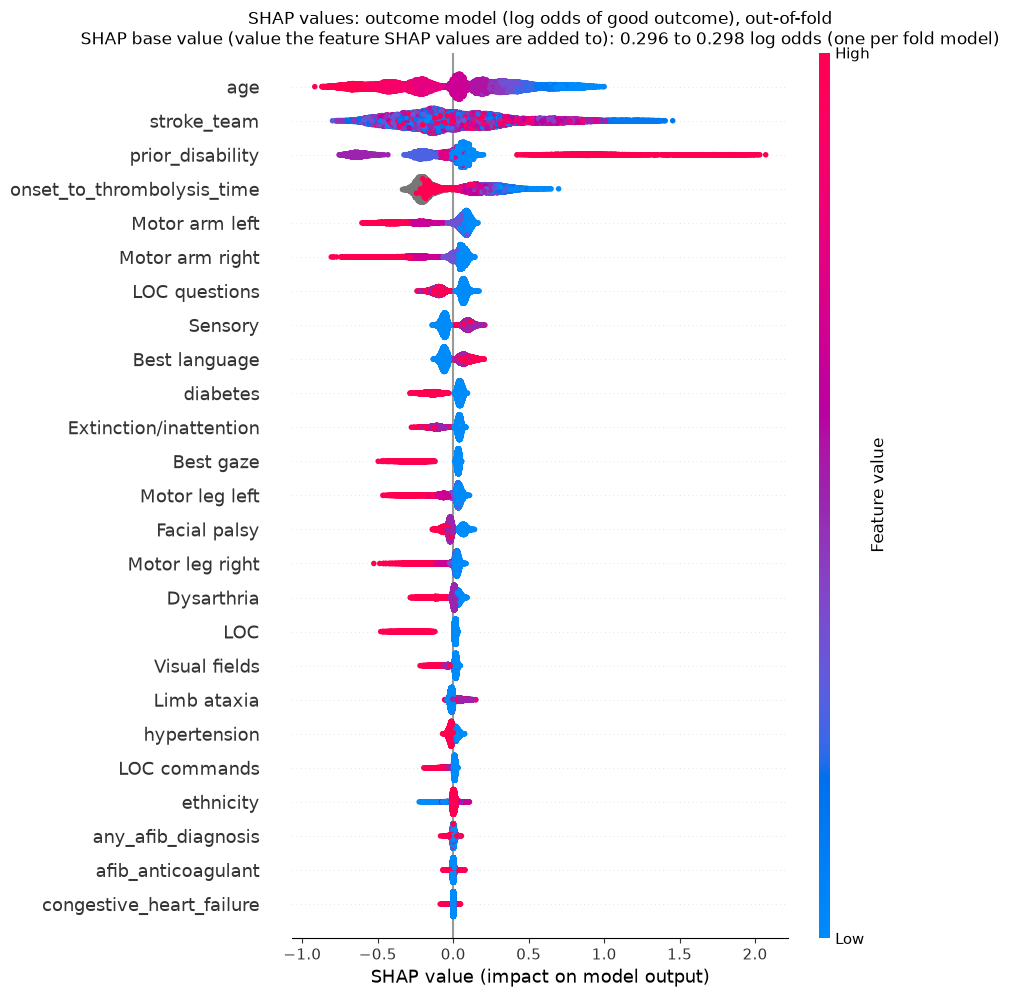

In [14]:
def out_of_fold_shap(models, folds):
    """SHAP values (log odds) for every patient, from the model of the fold in which they were held out."""
    frames, base_values, fold_base_values = [], [], []
    for model, (_, test_X, _, _) in zip(models, folds):
        contributions = model.get_booster().predict(
            xgb.DMatrix(test_X, enable_categorical=True), pred_contribs=True)
        frames.append(pd.DataFrame(contributions[:, :-1], columns=test_X.columns, index=test_X.index))
        base_values.append(pd.Series(contributions[:, -1], index=test_X.index))
        fold_base_values.append(float(contributions[0, -1]))  # the fold model's SHAP base value (same for every patient)
    return pd.concat(frames).loc[data.index], pd.concat(base_values).loc[data.index], fold_base_values

def shap_display_data(X):
    """Feature values for colouring SHAP plots: categories as codes, 'not thrombolysed' sentinel as missing."""
    X = X.copy()
    for col in CATEGORICAL_FEATURES:
        if col in X:
            X[col] = X[col].cat.codes.astype(float)
    if TIME_THROMBOLYSIS in X:
        X[TIME_THROMBOLYSIS] = X[TIME_THROMBOLYSIS].replace(NO_TREATMENT, np.nan)
    return X.astype(float)

outcome_shap, outcome_base, outcome_fold_base = out_of_fold_shap(models, folds)
outcome_base_text = (f"{min(outcome_fold_base):.3f} to {max(outcome_fold_base):.3f} log odds "
                     f"(one per fold model)")
X_outcome = data[X_FIELDS]
print("Outcome model SHAP base value (value the feature SHAP values are added to), for each fold model: "
      + ", ".join(f"{b:.3f}" for b in outcome_fold_base) + " log odds of good outcome")
oof_log_odds = pd.concat([
    pd.Series(to_log_odds(model.predict_proba(test_X)[:, 1]), index=test_X.index)
    for model, (_, test_X, _, _) in zip(models, folds)
]).loc[data.index]
print(f"Check: SHAP values + base value reproduce the predicted log odds "
      f"(max abs difference {(outcome_shap.sum(axis=1) + outcome_base - oof_log_odds).abs().max():.1e})")

outcome_explanation = shap.Explanation(
    values=outcome_shap.to_numpy(),
    base_values=outcome_base.to_numpy(),
    data=shap_display_data(X_outcome).to_numpy(),
    feature_names=[label(c) for c in X_FIELDS],
)
shap.plots.beeswarm(outcome_explanation, max_display=99, show=False)
plt.title(f"SHAP values: outcome model (log odds of good outcome), out-of-fold\n"
          f"SHAP base value (value the feature SHAP values are added to): {outcome_base_text}")
plt.savefig(output_path("outcome_shap_beeswarm.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Each of the 5 fold models has its own SHAP base value (the value the feature SHAP values are added to): 0.296 to 0.298 log odds of good outcome. For every patient, the base value of their fold model plus their feature SHAP values reproduces the model's predicted log odds exactly (maximum difference 4e-06). In the beeswarm plot, higher values of age, pre-stroke mRS and most NIHSS items (red points) lie to the left (lower chance of good outcome); sensory and language deficits lie slightly to the right.

Bar chart of the mean absolute SHAP value of each feature in the outcome model, i.e. its average influence on the predicted log odds of good outcome. NIHSS items are shown in red.

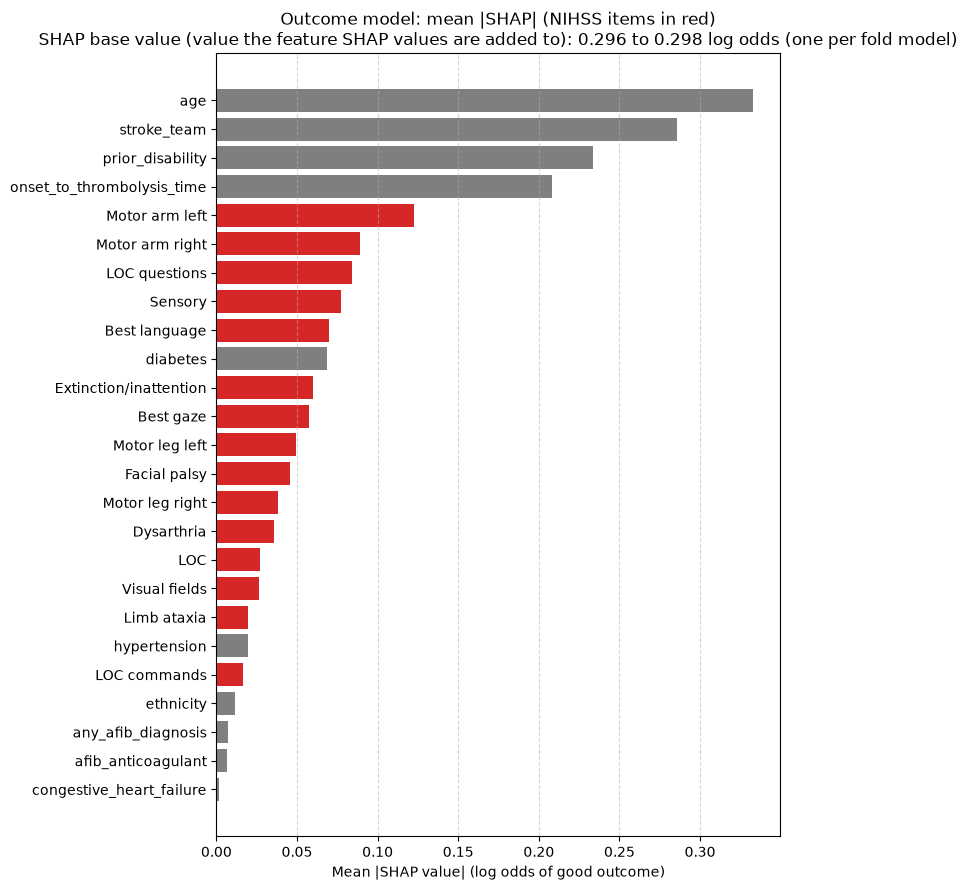

In [15]:
def plot_mean_abs_shap(shap_df, title, xlabel, filename):
    """Horizontal bar chart of mean |SHAP| per feature; NIHSS items in red, other features in grey."""
    importance = shap_df.abs().mean().sort_values()
    colours = ["tab:red" if f in NIHSS_COMPONENTS else "tab:grey" for f in importance.index]
    fig, ax = plt.subplots(figsize=(8, 9))
    ax.barh([label(f) for f in importance.index], importance, color=colours)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    return importance[::-1]

outcome_importance = plot_mean_abs_shap(
    outcome_shap, f"Outcome model: mean |SHAP| (NIHSS items in red)\n"
    f"SHAP base value (value the feature SHAP values are added to): {outcome_base_text}",
    "Mean |SHAP value| (log odds of good outcome)", output_path("outcome_shap_importance.png"))

**Results.** Age, stroke team and pre-stroke mRS have most influence on predicted outcome, followed by onset-to-thrombolysis time (which includes whether thrombolysis was given). The most influential NIHSS items are left and right arm weakness, LOC questions, sensory and language, followed by extinction, gaze, left leg weakness and facial palsy.

SHAP values of the outcome model by item score, one panel per NIHSS item: how much each score shifts the predicted log odds of good outcome, relative to the SHAP base value (the value the feature SHAP values are added to). The red dotted line is not used here; the black dashed line is SHAP = 0.

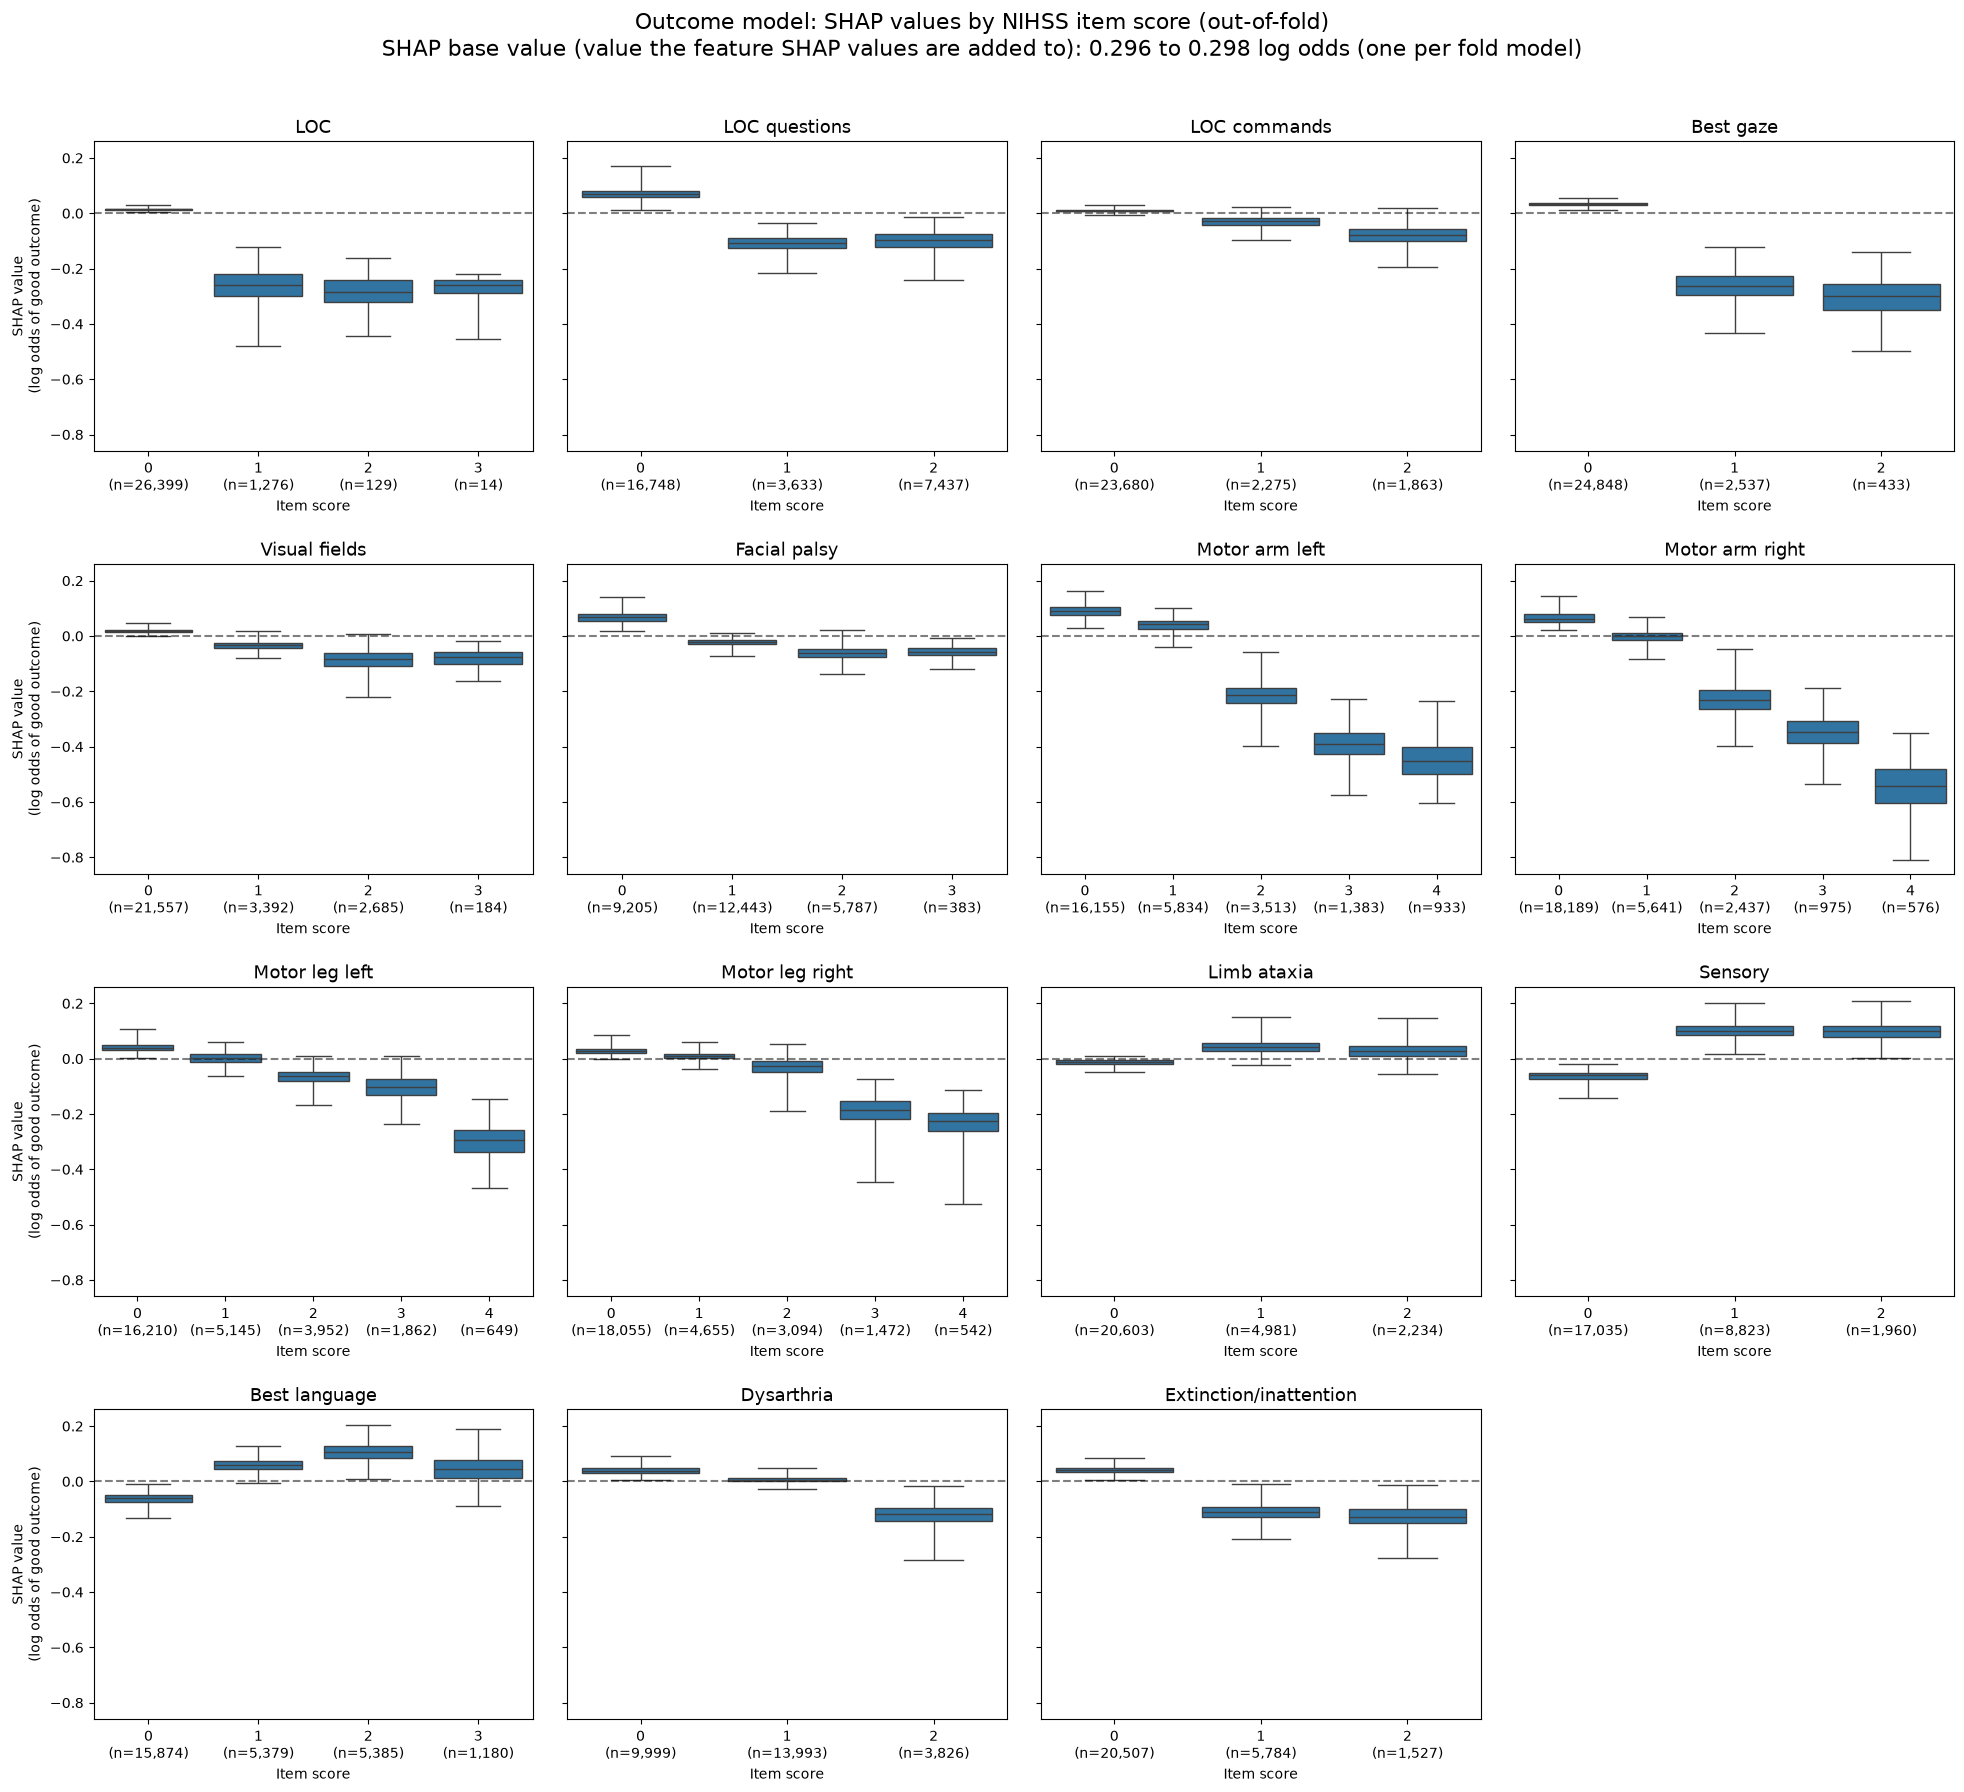

In [16]:
def plot_component_shap(shap_df, X, title, ylabel, filename, reference=None):
    """Box plots of SHAP values by item score for each NIHSS item (shared y-axis; whiskers show the full range)."""
    fig, axes = plt.subplots(4, 4, figsize=(20, 18), sharey=True)
    for ax, c in zip(axes.flat, NIHSS_COMPONENTS):
        plot_df = pd.DataFrame({"score": X[c].astype(int).to_numpy(), "shap": shap_df[c].to_numpy()})
        counts = plot_df["score"].value_counts().sort_index()
        order = counts.index.tolist()
        sns.boxplot(data=plot_df, x="score", y="shap", order=order, ax=ax, whis=(0, 100), color="tab:blue")
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels([f"{s}\n(n={counts[s]:,})" for s in order])
        ax.axhline(0, color="black", linestyle="--", alpha=0.5)
        if reference is not None:
            ax.axhline(reference, color="red", linestyle="dotted", alpha=0.7)
        ax.set_title(label(c), fontsize=13)
        ax.set_xlabel("Item score")
        ax.set_ylabel(ylabel)
    for ax in axes.flat[len(NIHSS_COMPONENTS):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=16, y=1.0)
    plt.tight_layout(pad=2)
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

plot_component_shap(
    outcome_shap, X_outcome,
    f"Outcome model: SHAP values by NIHSS item score (out-of-fold)\n"
    f"SHAP base value (value the feature SHAP values are added to): {outcome_base_text}",
    "SHAP value\n(log odds of good outcome)", output_path("outcome_shap_by_nihss_item.png"))

**Results.** For most items, SHAP is close to zero at score 0 and becomes more negative as the score rises, i.e. worse predicted outcome. The largest shifts are for gaze, LOC and arm weakness; sensory, language and limb ataxia deficits shift upwards (better predicted outcome for the same total NIHSS). The table from the next cell quantifies these shifts.

Table for each NIHSS item: mean |SHAP|, mean SHAP in patients with and without the deficit and their difference, together with the adjusted odds ratio per point of item score from a logistic regression of good outcome on all adjustment features, stroke team, ethnicity and thrombolysis.

In [17]:
def deficit_shap_table(shap_df, X):
    """For each NIHSS item: mean |SHAP|, and mean SHAP in patients with and without a deficit."""
    rows = []
    for c in NIHSS_COMPONENTS:
        present = (X[c] > 0).to_numpy()
        values = shap_df[c].to_numpy()
        rows.append({
            "component": label(c),
            "patients with deficit": int(present.sum()),
            "mean |SHAP|": np.abs(values).mean(),
            "mean SHAP, deficit": values[present].mean(),
            "mean SHAP, no deficit": values[~present].mean(),
        })
    table = pd.DataFrame(rows).set_index("component")
    table["SHAP difference (deficit - none)"] = table["mean SHAP, deficit"] - table["mean SHAP, no deficit"]
    return table

# Adjusted logistic regression of good outcome: odds ratio per point of each NIHSS item score
logit_X = pd.get_dummies(data[ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES], columns=CATEGORICAL_FEATURES,
                         drop_first=True, dtype=float)
logit_X["thrombolysed"] = data["thrombolysis_given"].astype(float)
logit_df = logit_X.assign(y=y).dropna()
logit_df = logit_df.loc[:, logit_df.std() > 0]
logit_fit = sm.GLM(logit_df["y"], sm.add_constant(logit_df.drop(columns="y")),
                   family=sm.families.Binomial()).fit()
logit_ci = logit_fit.conf_int()
outcome_or = pd.DataFrame({
    "OR per point": np.exp(logit_fit.params[NIHSS_COMPONENTS]),
    "OR CI lower": np.exp(logit_ci.loc[NIHSS_COMPONENTS, 0]),
    "OR CI upper": np.exp(logit_ci.loc[NIHSS_COMPONENTS, 1]),
    "p": logit_fit.pvalues[NIHSS_COMPONENTS],
}).rename(index=label)
print(f"Logistic regression: {int(logit_fit.nobs):,} patients with complete data")

outcome_by_item = deficit_shap_table(outcome_shap, X_outcome).join(outcome_or)
outcome_by_item = outcome_by_item.sort_values("SHAP difference (deficit - none)")
outcome_by_item.to_csv(output_path("outcome_by_nihss_item.csv"))
outcome_by_item.round(3)

Logistic regression: 27,818 patients with complete data


,patients with deficit,mean |SHAP|,"mean SHAP, deficit","mean SHAP, no deficit",SHAP difference (deficit - none),OR per point,OR CI lower,OR CI upper,p
component,,,,,,,,,
Best gaze,2970,0.058,-0.268,0.033,-0.301,0.719,0.670,0.772,0.000
LOC,1419,0.027,-0.266,0.014,-0.281,0.701,0.634,0.774,0.000
Motor arm left,11663,0.122,-0.128,0.090,-0.218,0.783,0.755,0.812,0.000
Motor arm right,9629,0.089,-0.127,0.065,-0.192,0.771,0.742,0.802,0.000
LOC questions,11070,0.084,-0.103,0.071,-0.174,0.856,0.820,0.894,0.000
Extinction/inattention,7311,0.060,-0.113,0.041,-0.154,0.834,0.794,0.877,0.000
Facial palsy,18613,0.045,-0.034,0.068,-0.102,0.906,0.872,0.941,0.000
Motor leg left,11608,0.050,-0.054,0.041,-0.094,0.887,0.856,0.920,0.000
Visual fields,6261,0.026,-0.058,0.017,-0.075,0.886,0.848,0.925,0.000


**Results.**
* **Overall importance.** Age, stroke team and pre-stroke mRS have the largest mean |SHAP| values in the outcome model. Onset-to-thrombolysis time comes next (0.21), reflecting the larger effect of thrombolysis at this severity. Then come the NIHSS items:
  * arm weakness (left 0.12, right 0.09);
  * LOC questions, sensory and language (0.07–0.09);
  * extinction, gaze, left leg, facial palsy, right leg and dysarthria (0.04–0.06);
  * LOC, visual fields, limb ataxia and LOC commands (0.016–0.03).
* **Effect of a deficit** (mean SHAP with minus without the deficit; adjusted OR per point of item score from the logistic regression):
  * **Largest reductions in good outcome**: best gaze (SHAP −0.30; OR 0.72), LOC (−0.28; OR 0.70) and arm weakness (left −0.22, right −0.19; OR 0.77–0.78).
  * **Moderate**: LOC questions (−0.17; OR 0.86) and extinction/inattention (−0.15; OR 0.83).
  * **Smaller**: facial palsy, leg weakness, visual fields, LOC commands and dysarthria (−0.06 to −0.10; OR 0.87–0.91).
  * **Associated with *better* outcome**: limb ataxia (+0.05; OR 0.97, CI includes 1), best language (+0.14; OR 1.02, CI includes 1) and sensory (+0.16; OR 1.06).

Patients here all have a total NIHSS of 6–10. A patient whose points come from sensory, language or ataxia items has fewer points in the items that carry most risk: consciousness, gaze and arm weakness. As in mild stroke, the same total NIHSS can therefore carry quite different prognoses.

# 3. Benefit by NIHSS item, other characteristics and time

## 3.1 Mean benefit by NIHSS item score

Mean individual benefit (log odds ratio) in thrombolysed patients for each score of each NIHSS item, with error bars of ±1 standard error of the mean. Scores held by fewer than 10 thrombolysed patients are not shown. The grey dotted line is the average benefit in all thrombolysed patients.

These are unadjusted, one-item-at-a-time summaries. Items are correlated with each other, with total NIHSS and with time to treatment, so a pattern in one panel can partly reflect another feature. Section 4 adjusts for this.

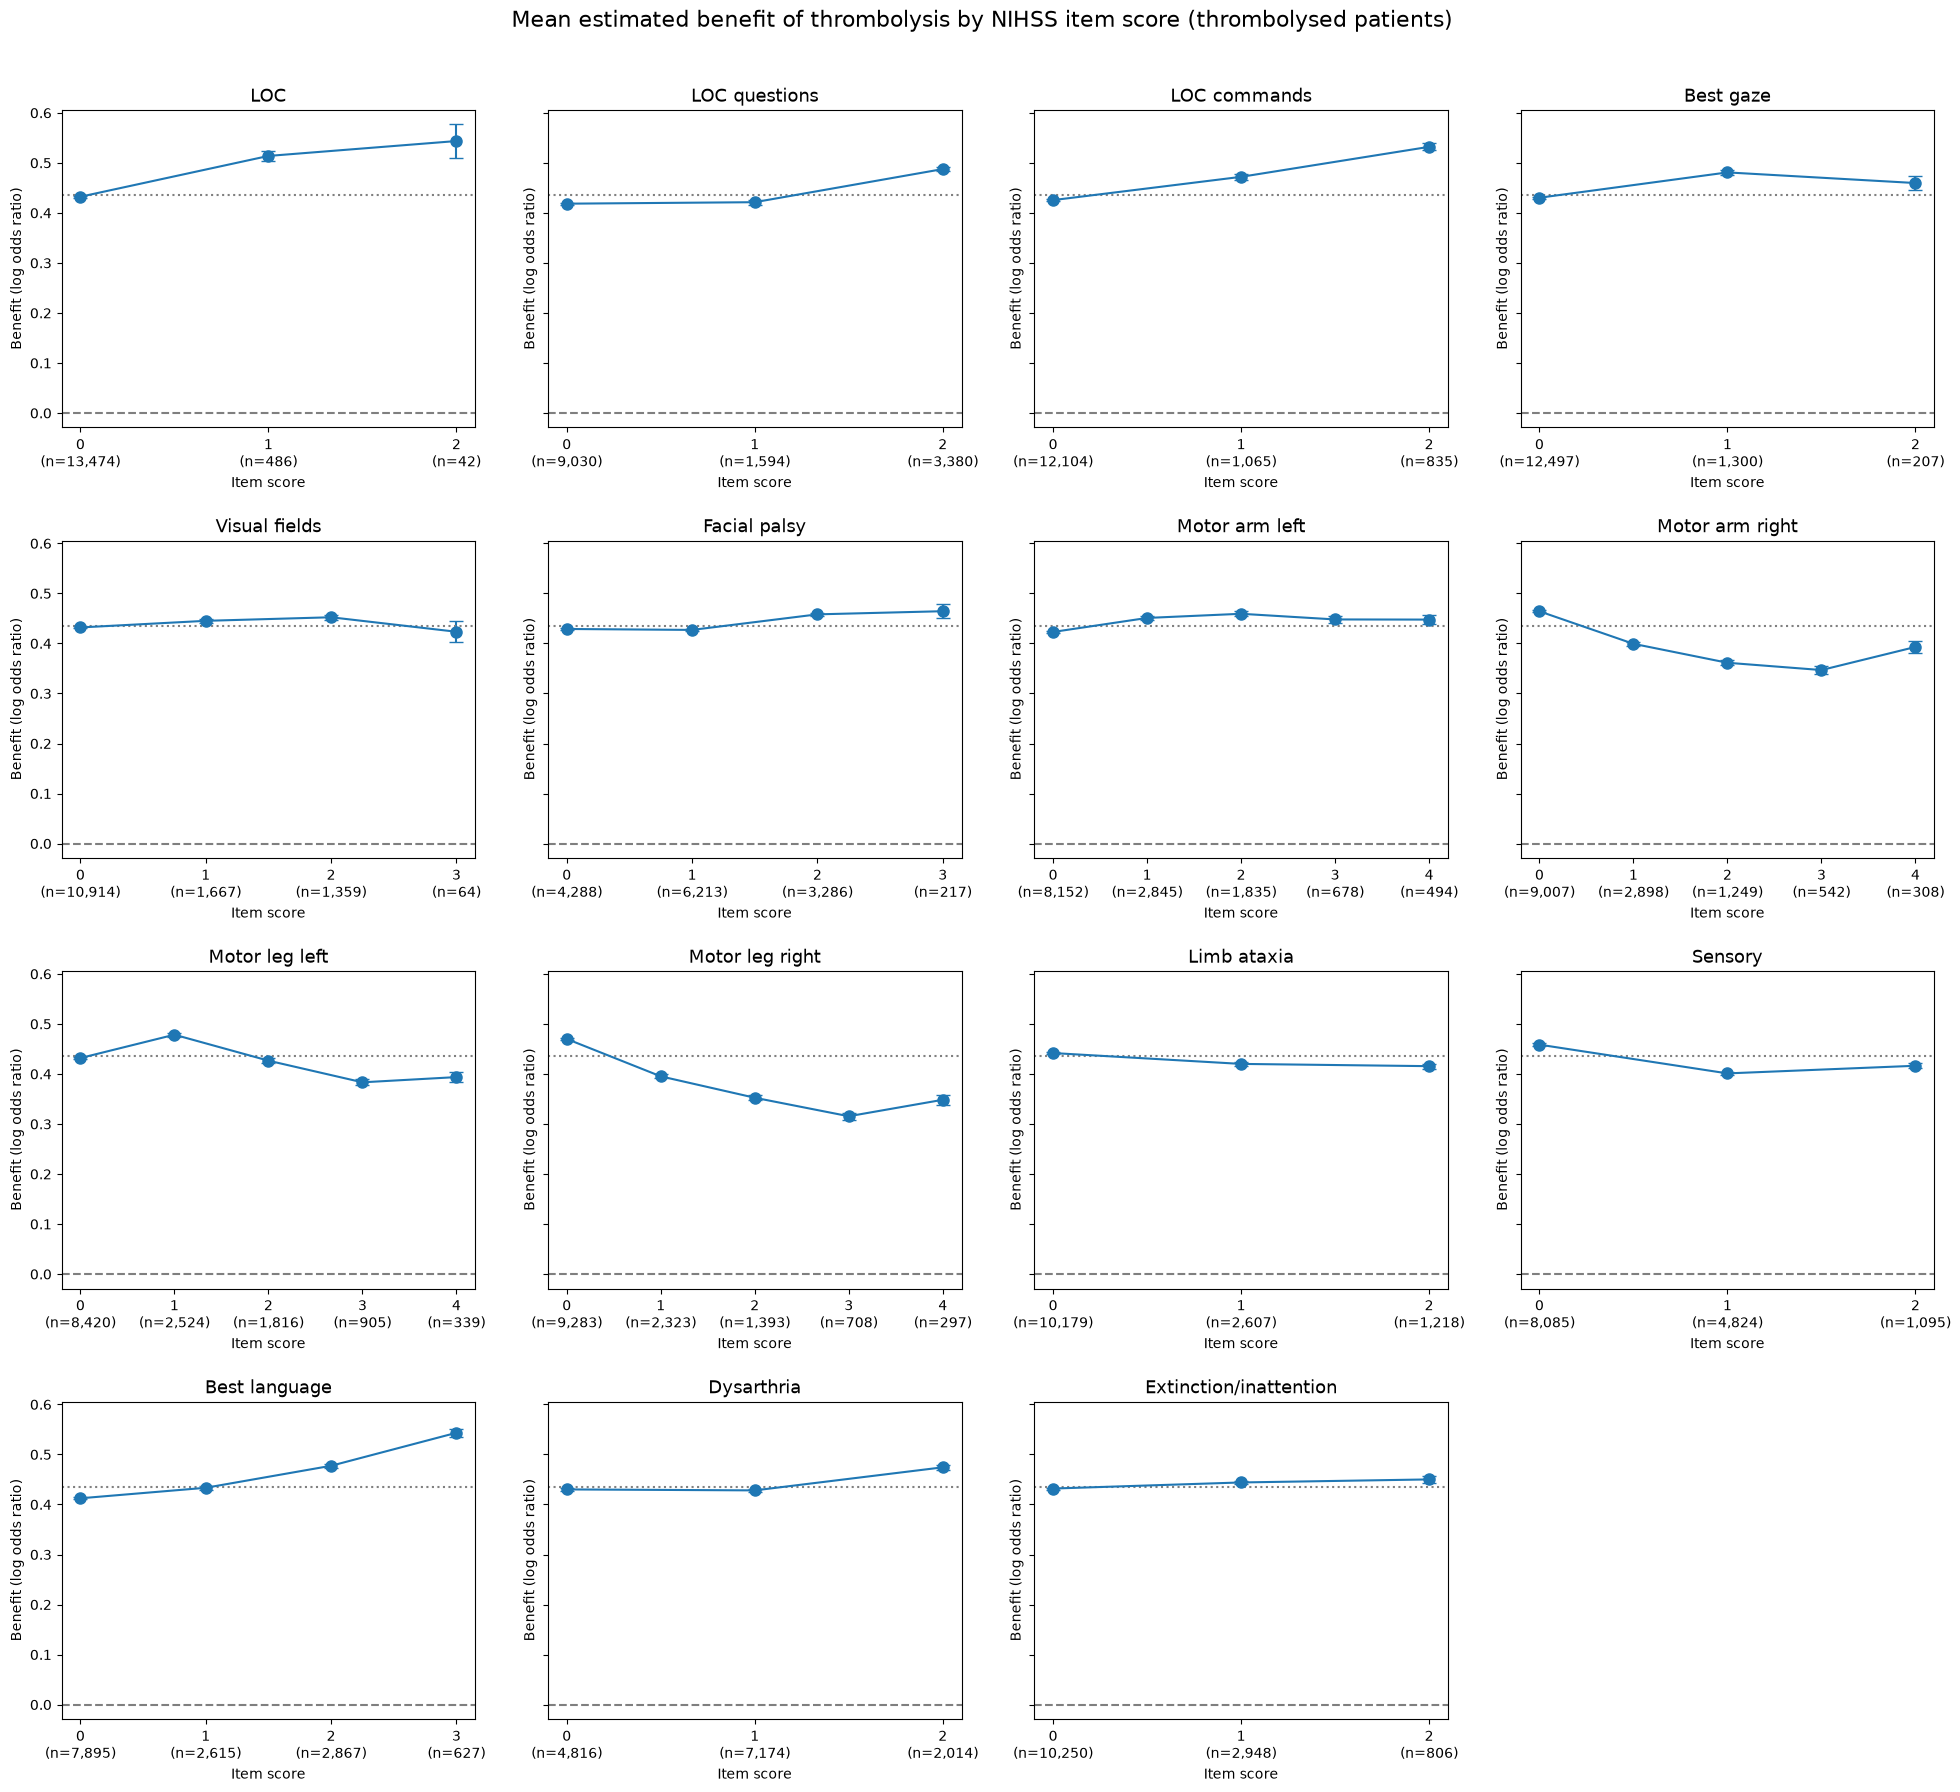

In [18]:
def plot_benefit_by_item_score(cf_, filename, min_n=10):
    """Mean benefit (log odds ratio, +/- 1 SE) by score of each NIHSS item."""
    fig, axes = plt.subplots(4, 4, figsize=(20, 18), sharey=True)
    for ax, c in zip(axes.flat, NIHSS_COMPONENTS):
        grouped = cf_.groupby(cf_[c].astype(int))["log_odds_diff"].agg(["mean", "sem", "count"])
        grouped = grouped[grouped["count"] >= min_n]
        x_values = np.arange(len(grouped))
        ax.errorbar(x_values, grouped["mean"], yerr=grouped["sem"], fmt="o-", markersize=8, capsize=5)
        ax.axhline(0, color="black", linestyle="--", alpha=0.5)
        ax.axhline(cf_["log_odds_diff"].mean(), color="grey", linestyle="dotted")
        ax.set_xticks(x_values)
        ax.set_xticklabels([f"{s}\n(n={n:,})" for s, n in zip(grouped.index, grouped["count"])])
        ax.set_title(label(c), fontsize=13)
        ax.set_xlabel("Item score")
        ax.set_ylabel("Benefit (log odds ratio)")
    for ax in axes.flat[len(NIHSS_COMPONENTS):]:
        ax.axis("off")
    fig.suptitle("Mean estimated benefit of thrombolysis by NIHSS item score (thrombolysed patients)",
                 fontsize=16, y=1.0)
    plt.tight_layout(pad=2)
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

plot_benefit_by_item_score(cf, output_path("treatment_effects_by_nihss_item.png"))

**Results.** Benefit rises above the average (grey dotted line, 0.44) with the score for LOC, LOC commands, LOC questions (score 2) and best language (about 0.54 at score 3). It falls below the average with the score for right arm weakness (to about 0.35) and right leg weakness (to about 0.31). Other items stay close to the average.

## 3.2 Benefit with and without each deficit

For each NIHSS item, the mean benefit in thrombolysed patients who have the deficit (score ≥ 1) and in those who do not, on the probability (percentage points) and log odds scales, with the mean total NIHSS of each group for context. Rows are sorted by the benefit in patients with the deficit. Section 5.1 gives bootstrap confidence intervals for these groups and for the differences.

In [19]:
def benefit_by_deficit(cf_):
    """Mean benefit in thrombolysed patients with and without a deficit on each NIHSS item."""
    rows = []
    for c in NIHSS_COMPONENTS:
        present = cf_[c] > 0
        with_deficit, without = cf_[present], cf_[~present]
        rows.append({
            "component": label(c),
            "thrombolysed with deficit": len(with_deficit),
            "mean total NIHSS, deficit": with_deficit["stroke_severity"].mean(),
            "mean total NIHSS, no deficit": without["stroke_severity"].mean(),
            "benefit pp, deficit": 100 * with_deficit["treatment_diff_prob"].mean(),
            "benefit pp, no deficit": 100 * without["treatment_diff_prob"].mean(),
            "log OR, deficit": with_deficit["log_odds_diff"].mean(),
            "log OR, no deficit": without["log_odds_diff"].mean(),
        })
    table = pd.DataFrame(rows).set_index("component")
    table["difference pp (deficit - none)"] = table["benefit pp, deficit"] - table["benefit pp, no deficit"]
    return table.sort_values("benefit pp, deficit", ascending=False)

benefit_deficit = benefit_by_deficit(cf)
benefit_deficit.to_csv(output_path("benefit_by_nihss_item_deficit.csv"))
benefit_deficit.round(2)

,thrombolysed with deficit,"mean total NIHSS, deficit","mean total NIHSS, no deficit","benefit pp, deficit","benefit pp, no deficit","log OR, deficit","log OR, no deficit",difference pp (deficit - none)
component,,,,,,,,
LOC,530,8.17,7.61,11.46,9.35,0.52,0.43,2.11
LOC commands,1900,7.87,7.59,10.98,9.19,0.50,0.43,1.79
Best gaze,1507,8.24,7.56,10.82,9.27,0.48,0.43,1.55
LOC questions,4974,7.83,7.52,10.27,8.97,0.47,0.42,1.29
Best language,6109,7.77,7.52,10.06,8.95,0.47,0.41,1.12
Extinction/inattention,3754,8.12,7.45,9.90,9.26,0.45,0.43,0.64
Visual fields,3090,8.07,7.51,9.90,9.30,0.45,0.43,0.60
Motor arm left,5852,7.72,7.57,9.83,9.15,0.45,0.42,0.68
Motor leg left,5584,7.76,7.55,9.57,9.34,0.44,0.43,0.24


**Results.** Mean benefit with the deficit is highest for LOC (11.5 points), LOC commands (11.0), best gaze (10.8), LOC questions (10.3) and best language (10.1). It is lowest for right leg (7.9) and right arm weakness (8.3), sensory (8.5) and limb ataxia (8.8), compared with 9.7–10.2 points without these deficits. Mean total NIHSS differs little between the groups (7.5–8.2).

The same table as a plot: for each NIHSS item, mean benefit in thrombolysed patients without the deficit (grey) and with it (black), joined by an arrow. An upward arrow means more benefit with the deficit, a downward arrow less. Items are sorted by the benefit with the deficit (greatest on the left), and the number of thrombolysed patients with each deficit is shown under its name. The dotted line is the average benefit in all thrombolysed patients. These are unadjusted means; Section 5.1 gives bootstrap CIs for the differences.

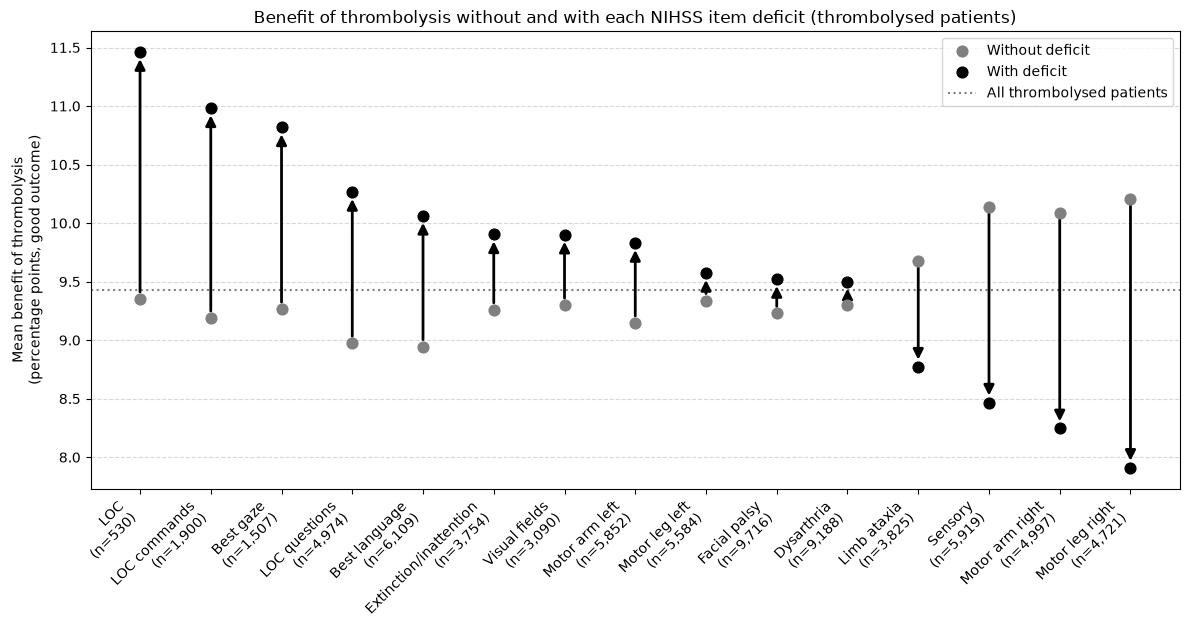

In [20]:
# Benefit without (grey) and with (black) each NIHSS item deficit, joined by an arrow from 'without' to 'with'.
# Items are sorted by the benefit with the deficit, greatest on the left.
plot_data = benefit_deficit.sort_values("benefit pp, deficit", ascending=False)
x = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(12, 6.5))
for xi, (_, r) in zip(x, plot_data.iterrows()):
    ax.annotate("", xy=(xi, r["benefit pp, deficit"]), xytext=(xi, r["benefit pp, no deficit"]),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=2, shrinkA=5, shrinkB=5, mutation_scale=15))
ax.scatter(x, plot_data["benefit pp, no deficit"], color="grey", s=60, zorder=3, label="Without deficit")
ax.scatter(x, plot_data["benefit pp, deficit"], color="black", s=60, zorder=3, label="With deficit")
ax.axhline(100 * cf["treatment_diff_prob"].mean(), color="grey", linestyle="dotted", label="All thrombolysed patients")
ax.set_xticks(x)
ax.set_xticklabels([f"{name}\n(n={n:,})" for name, n in zip(plot_data.index, plot_data["thrombolysed with deficit"])],
                   rotation=45, ha="right")
ax.set_ylabel("Mean benefit of thrombolysis\n(percentage points, good outcome)")
ax.set_title("Benefit of thrombolysis without and with each NIHSS item deficit (thrombolysed patients)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(output_path("benefit_by_nihss_item_deficit_arrows.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Upward arrows for LOC, LOC commands, best gaze, LOC questions and best language (to 10.1–11.5 points), small upward arrows for extinction, visual fields and left arm weakness, and almost no change for left leg weakness, facial palsy and dysarthria. Clear downward arrows for limb ataxia, sensory, right arm and right leg weakness (from about 10 to 7.9–8.8 points).

## 3.3 Isolated deficits and number of items affected

Deficits often occur together (for example arm and leg weakness, or facial palsy and dysarthria), so the groups in 3.2 overlap. Two simpler views:

* **Isolated deficits**: thrombolysed patients whose *only* abnormal item is the one shown. For these patients total NIHSS equals the item score. Items with fewer than 20 such patients are not shown. *With total NIHSS 6–10 there are no isolated deficits, because no single item scores more than 4, so this table is empty here.*
* **Number of items affected**: mean benefit by how many NIHSS items are abnormal (1 to 5).

In [21]:
affected = cf[NIHSS_COMPONENTS] > 0
isolated_rows = []
for c in NIHSS_COMPONENTS:
    isolated = cf[affected[c] & (cf["n_items_affected"] == 1)]
    isolated_rows.append({
        "component": label(c),
        "thrombolysed with isolated deficit": len(isolated),
        "mean item score": isolated[c].mean(),
        "benefit pp": 100 * isolated["treatment_diff_prob"].mean(),
        "log OR": isolated["log_odds_diff"].mean(),
        "log OR SE": isolated["log_odds_diff"].sem(),
    })
isolated_deficits = (pd.DataFrame(isolated_rows).set_index("component")
                     .query("`thrombolysed with isolated deficit` >= 20")
                     .sort_values("benefit pp", ascending=False))
isolated_deficits.to_csv(output_path("benefit_isolated_deficits.csv"))
display(isolated_deficits.round(3))

by_n_items = cf.groupby("n_items_affected").agg(
    thrombolysed=("log_odds_diff", "size"),
    mean_total_nihss=("stroke_severity", "mean"),
    benefit_pp=("treatment_diff_prob", lambda v: 100 * v.mean()),
    log_or=("log_odds_diff", "mean"),
    log_or_se=("log_odds_diff", "sem"),
)
display(by_n_items.round(3))

,thrombolysed with isolated deficit,mean item score,benefit pp,log OR,log OR SE
component,,,,,


,thrombolysed,mean_total_nihss,benefit_pp,log_or,log_or_se
n_items_affected,,,,,
2,118,6.737,8.969,0.395,0.017
3,1147,6.704,9.565,0.446,0.006
4,3435,7.088,9.558,0.439,0.003
5,4205,7.419,9.337,0.434,0.003
6,3119,8.027,9.134,0.426,0.003
7,1432,8.823,9.736,0.441,0.005
8,456,9.364,10.075,0.449,0.010
9,82,9.768,10.039,0.457,0.022
10,10,10.000,11.966,0.522,0.071


**Results** (Sections 3.1–3.3; unadjusted summaries).
* **With vs without each deficit.** Most deficits show close to the average benefit of 9.4 points.
  * **Highest**: LOC (11.5 points), LOC commands (11.0), gaze (10.8), LOC questions (10.3) and language (10.1).
  * **Lowest**: right leg weakness (7.9), right arm weakness (8.3), sensory (8.5) and limb ataxia (8.8), compared with 9.7–10.2 without these deficits.
  * Total NIHSS differs little between these groups (7.5–8.2).
* **By item score** (figure in 3.1):
  * benefit rises with the score for LOC, LOC commands, LOC questions (score 2) and language (to 0.54 log OR at score 3);
  * it falls with the score for right arm weakness (to about 0.35 at score 3) and right leg weakness (to about 0.31 at score 3);
  * it is flat for the other items.
* **Isolated deficits.** None: every patient with NIHSS 6–10 has at least two abnormal items, so this table is empty.
* **Number of items affected.** Benefit hardly changes with the number of abnormal items: 9.0–9.7 points for 2–7 items and 10–12 points for the few patients with 8–10. In mild stroke, by contrast, it rose steeply.

## 3.4 Mean benefit by other characteristics

As in 3.1, for the features other than the NIHSS items. Onset-to-thrombolysis time is grouped into 30-minute bins; age is recorded in 5-year bands.

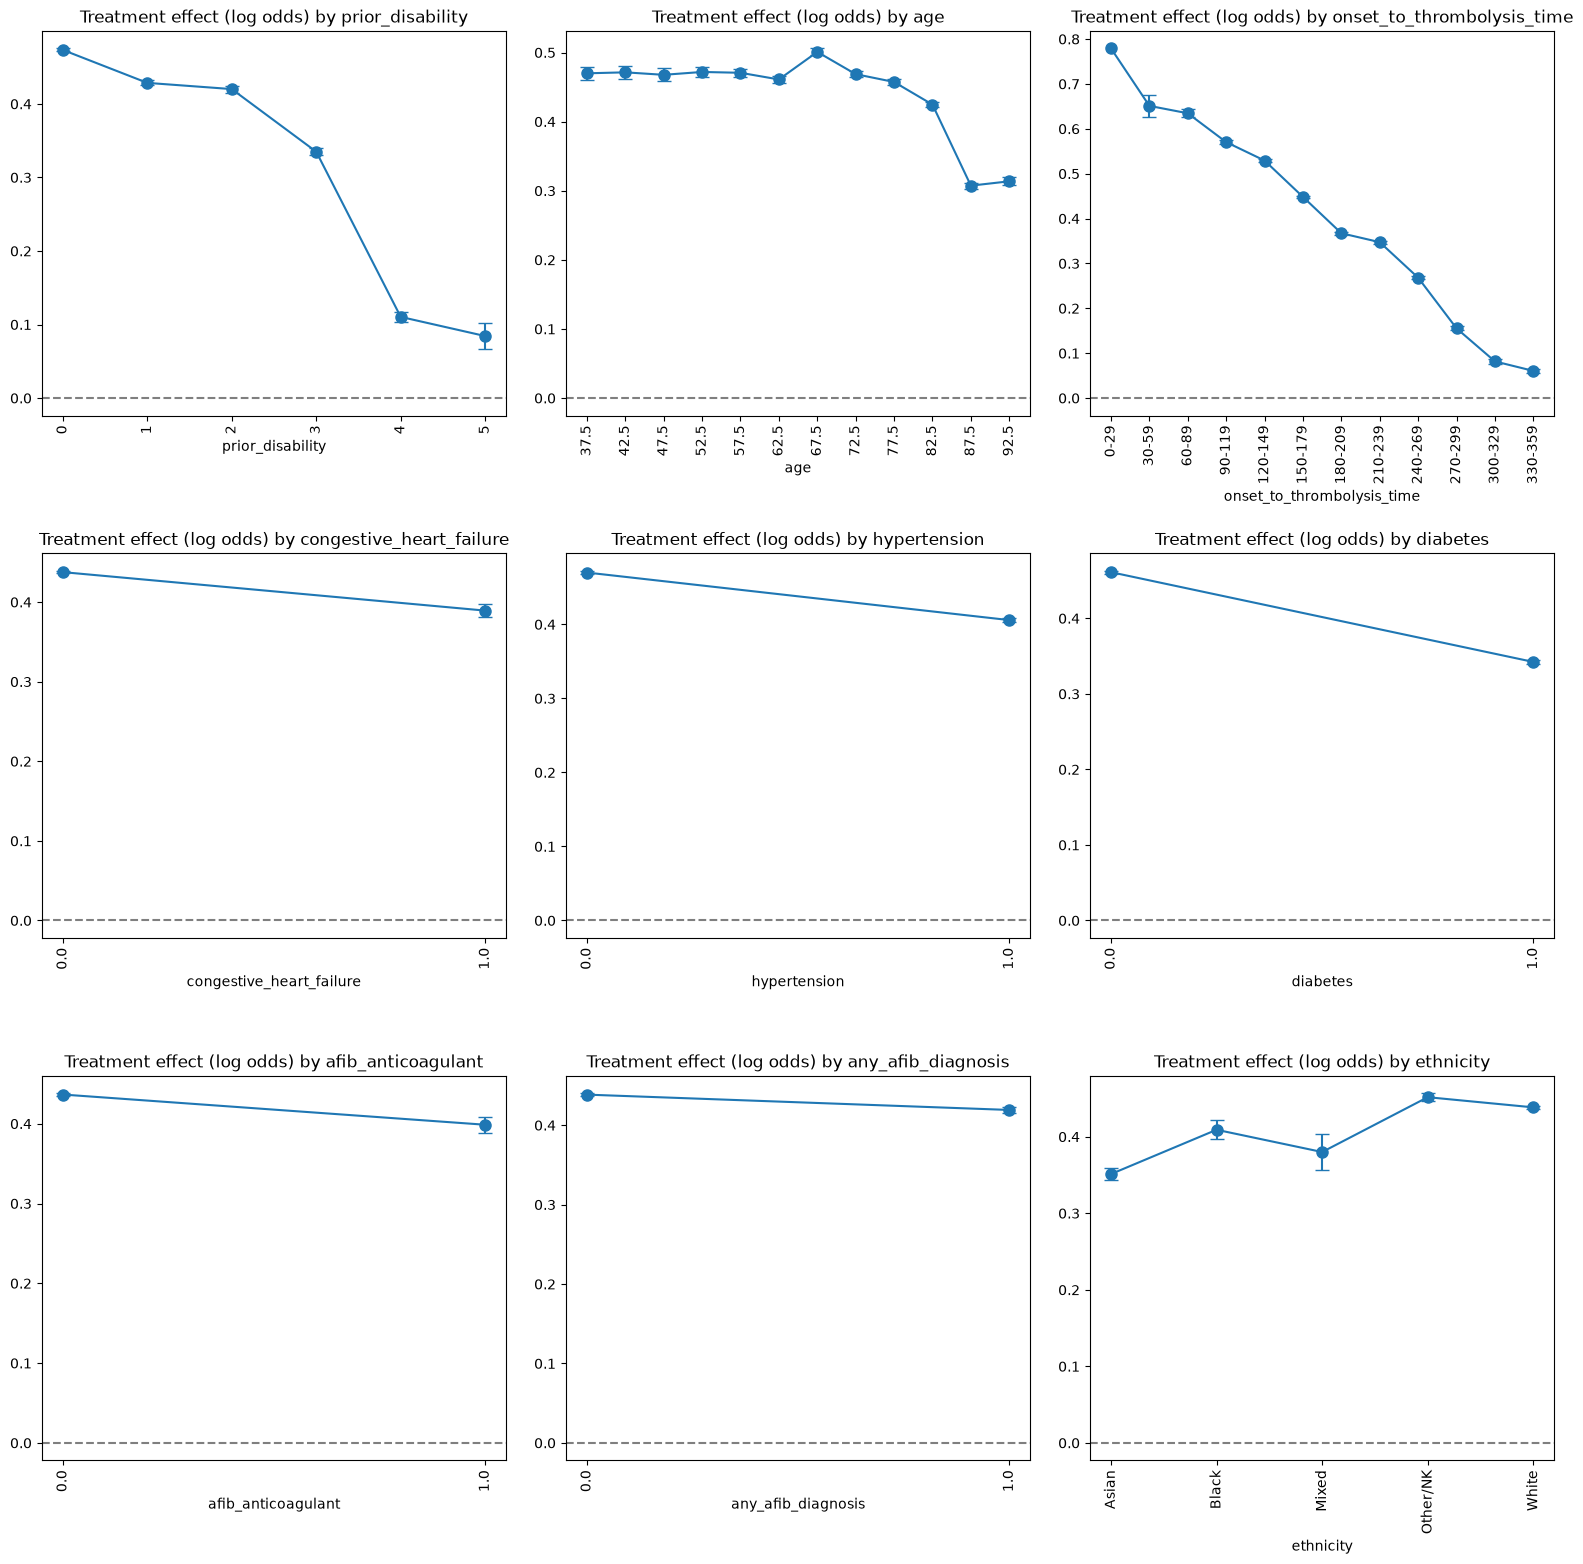

In [22]:
def time_bin_labels(starts, width=30):
    """Labels such as '120-149' for binned times."""
    return [f"{start}-{start + width - 1}" for start in starts]

fig, axes = plt.subplots(3, 3, figsize=(16, 16))

for ax, feature in zip(axes.flat, OTHER_EFFECT_FEATURES):
    plot_df = cf[[feature, "log_odds_diff"]].dropna()
    if feature == TIME_THROMBOLYSIS:
        plot_df[feature] = (plot_df[feature] // 30 * 30).astype(int)

    grouped = plot_df.groupby(feature, observed=True)["log_odds_diff"].agg(["mean", "sem"])
    x_values = np.arange(len(grouped))

    ax.errorbar(x_values, grouped["mean"], yerr=grouped["sem"], fmt="o-", markersize=8, capsize=5)
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"Treatment effect (log odds) by {feature}")
    ax.set_xlabel(feature)
    ax.set_xticks(x_values)
    ax.tick_params(axis="x", rotation=90)

    if feature == TIME_THROMBOLYSIS:
        ax.set_xticklabels(time_bin_labels(grouped.index))
    else:
        ax.set_xticklabels([str(v) for v in grouped.index])

plt.tight_layout(pad=2)
plt.savefig(output_path("treatment_effects_other_features.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**
* **Time to thrombolysis**: benefit falls steadily, from about 0.78 log OR at 0–29 minutes (few patients) and 0.64–0.65 at 30–89 minutes, to 0.45 at 150–179 minutes, 0.27 at 240–269 minutes and 0.06–0.08 after 5 hours.
* **Pre-stroke mRS**: a strong gradient.
  * 0.42–0.47 at mRS 0–2;
  * 0.33 at mRS 3;
  * only 0.09–0.11 at mRS 4–5.
* **Age**: about 0.46–0.50 up to 80 years, 0.42 at 80–84, and about 0.31 over 85.
* **Diabetes**: 0.34 with vs 0.46 without. **Hypertension**: 0.40 with vs 0.47 without. **Heart failure** and **anticoagulant use**: slightly lower.
* **Ethnicity**: 0.35–0.45, lowest in Asian patients.

## 3.5 Benefit by onset-to-thrombolysis time

An ordinary least squares (OLS) regression of individual predicted benefit (log odds ratio) on onset-to-thrombolysis time gives:

* **Benefit at time zero** (the intercept), with 95% CI. This is an extrapolation, because few patients are treated within an hour.
* **Time at which predicted benefit reaches zero**: x = −intercept / slope. Its 95% CI uses the delta method:
Var(x) = Var(a)/b² + a² Var(b)/b⁴ − 2a Cov(a, b)/b³, where a is the intercept and b the slope.
When the zero point lies beyond the observed times this is also an extrapolation.

Note: the 'observations' are model predictions, not independent outcomes, so OLS standard errors and p-values are too small. Section 5.1 gives a bootstrap CI for the time at zero benefit. Treat the regression as a description of how the S-learner's estimated benefit changes with time.

In [23]:
def fit_time_regression(df, time_col=TIME_THROMBOLYSIS, benefit_col="log_odds_diff"):
    """OLS of benefit on time; return the fit and a dict of key quantities with 95% CIs."""
    ols = sm.OLS(df[benefit_col], sm.add_constant(df[[time_col]])).fit()
    intercept, slope = ols.params["const"], ols.params[time_col]
    cov = ols.cov_params()
    intercept_ci = ols.conf_int().loc["const"]

    result = {
        "n": int(ols.nobs),
        "intercept": intercept,
        "intercept CI lower": intercept_ci.iloc[0],
        "intercept CI upper": intercept_ci.iloc[1],
        "slope per hour": slope * 60,
        "R-squared": ols.rsquared,
        "time at zero benefit": np.nan,
        "time at zero CI lower": np.nan,
        "time at zero CI upper": np.nan,
    }
    if not np.isclose(slope, 0):
        x_at_zero = -intercept / slope
        variance = (
            cov.loc["const", "const"] / slope**2
            + intercept**2 * cov.loc[time_col, time_col] / slope**4
            - 2 * intercept * cov.loc["const", time_col] / slope**3
        )
        half_width = 1.96 * np.sqrt(max(variance, 0))
        result.update({
            "time at zero benefit": x_at_zero,
            "time at zero CI lower": x_at_zero - half_width,
            "time at zero CI upper": x_at_zero + half_width,
        })
    return ols, result

ols_time, time_result = fit_time_regression(cf)
print(ols_time.summary())
print(f"\nPredicted benefit at time zero (intercept): {time_result['intercept']:.4f}, "
      f"95% CI: [{time_result['intercept CI lower']:.4f}, {time_result['intercept CI upper']:.4f}]")
print(f"Time at which predicted benefit is zero: {time_result['time at zero benefit']:.0f} mins, "
      f"95% CI: [{time_result['time at zero CI lower']:.0f}, {time_result['time at zero CI upper']:.0f}] mins")

                            OLS Regression Results                            
Dep. Variable:          log_odds_diff   R-squared:                       0.356
Model:                            OLS   Adj. R-squared:                  0.356
Method:                 Least Squares   F-statistic:                     7754.
Date:                Sun, 22 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:58:03   Log-Likelihood:                 5969.1
No. Observations:               14004   AIC:                        -1.193e+04
Df Residuals:                   14002   BIC:                        -1.192e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

**Results.** Benefit falls by 0.13 log odds ratio per hour (−0.0022 per minute). The fitted benefit at time zero is 0.81 (95% CI 0.80 to 0.82), and the line reaches zero at 372 minutes (95% CI 367 to 376), beyond the observed treatment times. Time explains 36% of the variation in individual benefit (R² 0.36). The OLS standard errors are too small, because the observations are model predictions (see Section 5.1).

Scatter plot of each thrombolysed patient's estimated benefit (log odds ratio) against onset-to-thrombolysis time, with the fitted regression line and its 95% confidence band.

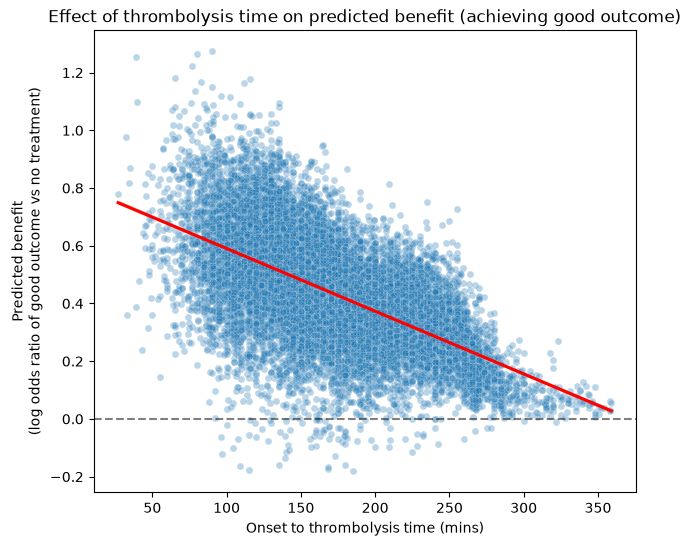

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=cf, x=TIME_THROMBOLYSIS, y="log_odds_diff", s=25, alpha=0.3, ax=ax)
sns.regplot(data=cf, x=TIME_THROMBOLYSIS, y="log_odds_diff", scatter=False, ci=95,
            line_kws={"color": "red"}, ax=ax)
ax.axhline(0, color="black", linestyle="--", alpha=0.5)
ax.set_title("Effect of thrombolysis time on predicted benefit (achieving good outcome)")
ax.set_xlabel("Onset to thrombolysis time (mins)")
ax.set_ylabel(f"Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
fig.savefig(output_path("thrombolysis_time_effect.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Predicted benefit falls by about 0.13 log odds ratio per hour (0.0022 per minute). The extrapolated benefit at time zero is 0.81 (95% CI 0.80 to 0.82; OR about 2.2). The fitted line reaches zero at 372 minutes (95% CI 367 to 376), beyond the treatment times observed. The bootstrap CI in Section 5.1 is wide: 307 to 436 minutes. Time explains 36% of the variation in individual estimates (R² 0.36).

## 3.6 Benefit by onset-to-thrombolysis time, with and without each deficit

The same regression fitted separately to thrombolysed patients with and without a deficit on each NIHSS item (groups with fewer than 30 patients are skipped). In the figure, coloured lines are patients with the deficit and grey lines patients without it; bands are 95% confidence bands for the fitted line, drawn over each group's observed time range.

n  intercept  slope per hour  \
component              group                                          
LOC                    deficit       530      1.004          -0.165   
                       no deficit  13474      0.802          -0.130   
LOC questions          deficit      4974      0.841          -0.130   
                       no deficit   9030      0.793          -0.132   
LOC commands           deficit      1900      0.873          -0.128   
                       no deficit  12104      0.800          -0.132   
Best gaze              deficit      1507      0.928          -0.156   
                       no deficit  12497      0.794          -0.128   
Visual fields          deficit      3090      0.817          -0.128   
                       no deficit  10914      0.806          -0.131   
Facial palsy           deficit      9716      0.824          -0.137   
                       no deficit   4288      0.772          -0.116   
Motor arm left         deficit      5852      0.859          -0.143   
                       no deficit   8152      0.770          -0.121   
Motor arm right        deficit      4997      0.717          -0.117   
                       no deficit   9007      0.861          -0.139   
Motor leg left         deficit      5584      0.843          -0.141   
                       no deficit   8420      0.784          -0.123   
Motor leg right        deficit      4721      0.705          -0.117   
                       no deficit   9283      0.858          -0.136   
Limb ataxia            deficit      3825      0.789          -0.128   
                       no deficit  10179      0.815          -0.131   
Sensory                deficit      5919      0.721          -0.111   
                       no deficit   8085      0.874          -0.145   
Best language          deficit      6109      0.831          -0.128   
                       no deficit   7895      0.792          -0.133   
Dysarthria             deficit      9188      0.815          -0.133   
                       no deficit   4816      0.796          -0.125   
Extinction/inattention deficit      3754      0.822          -0.132   
                       no deficit  10250      0.803          -0.130   

                                   R-squared  time at zero benefit  \
component              group                                         
LOC                    deficit         0.459               365.459   
                       no deficit      0.357               371.349   
LOC questions          deficit         0.317               389.434   
                       no deficit      0.397               360.222   
LOC commands           deficit         0.333               407.656   
                       no deficit      0.372               364.916   
Best gaze              deficit         0.451               356.508   
                       no deficit      0.349               373.716   
Visual fields          deficit         0.363               382.025   
                       no deficit      0.356               368.782   
Facial palsy           deficit         0.382               361.300   
                       no deficit      0.298               398.161   
Motor arm left         deficit         0.416               360.271   
                       no deficit      0.316               381.961   
Motor arm right        deficit         0.334               367.170   
                       no deficit      0.396               372.692   
Motor leg left         deficit         0.405               357.926   
                       no deficit      0.326               382.169   
Motor leg right        deficit         0.334               360.085   
                       no deficit      0.398               377.808   
Limb ataxia            deficit         0.388               368.822   
                       no deficit      0.346               373.204   
Sensory                deficit         0.333               388.599   
                

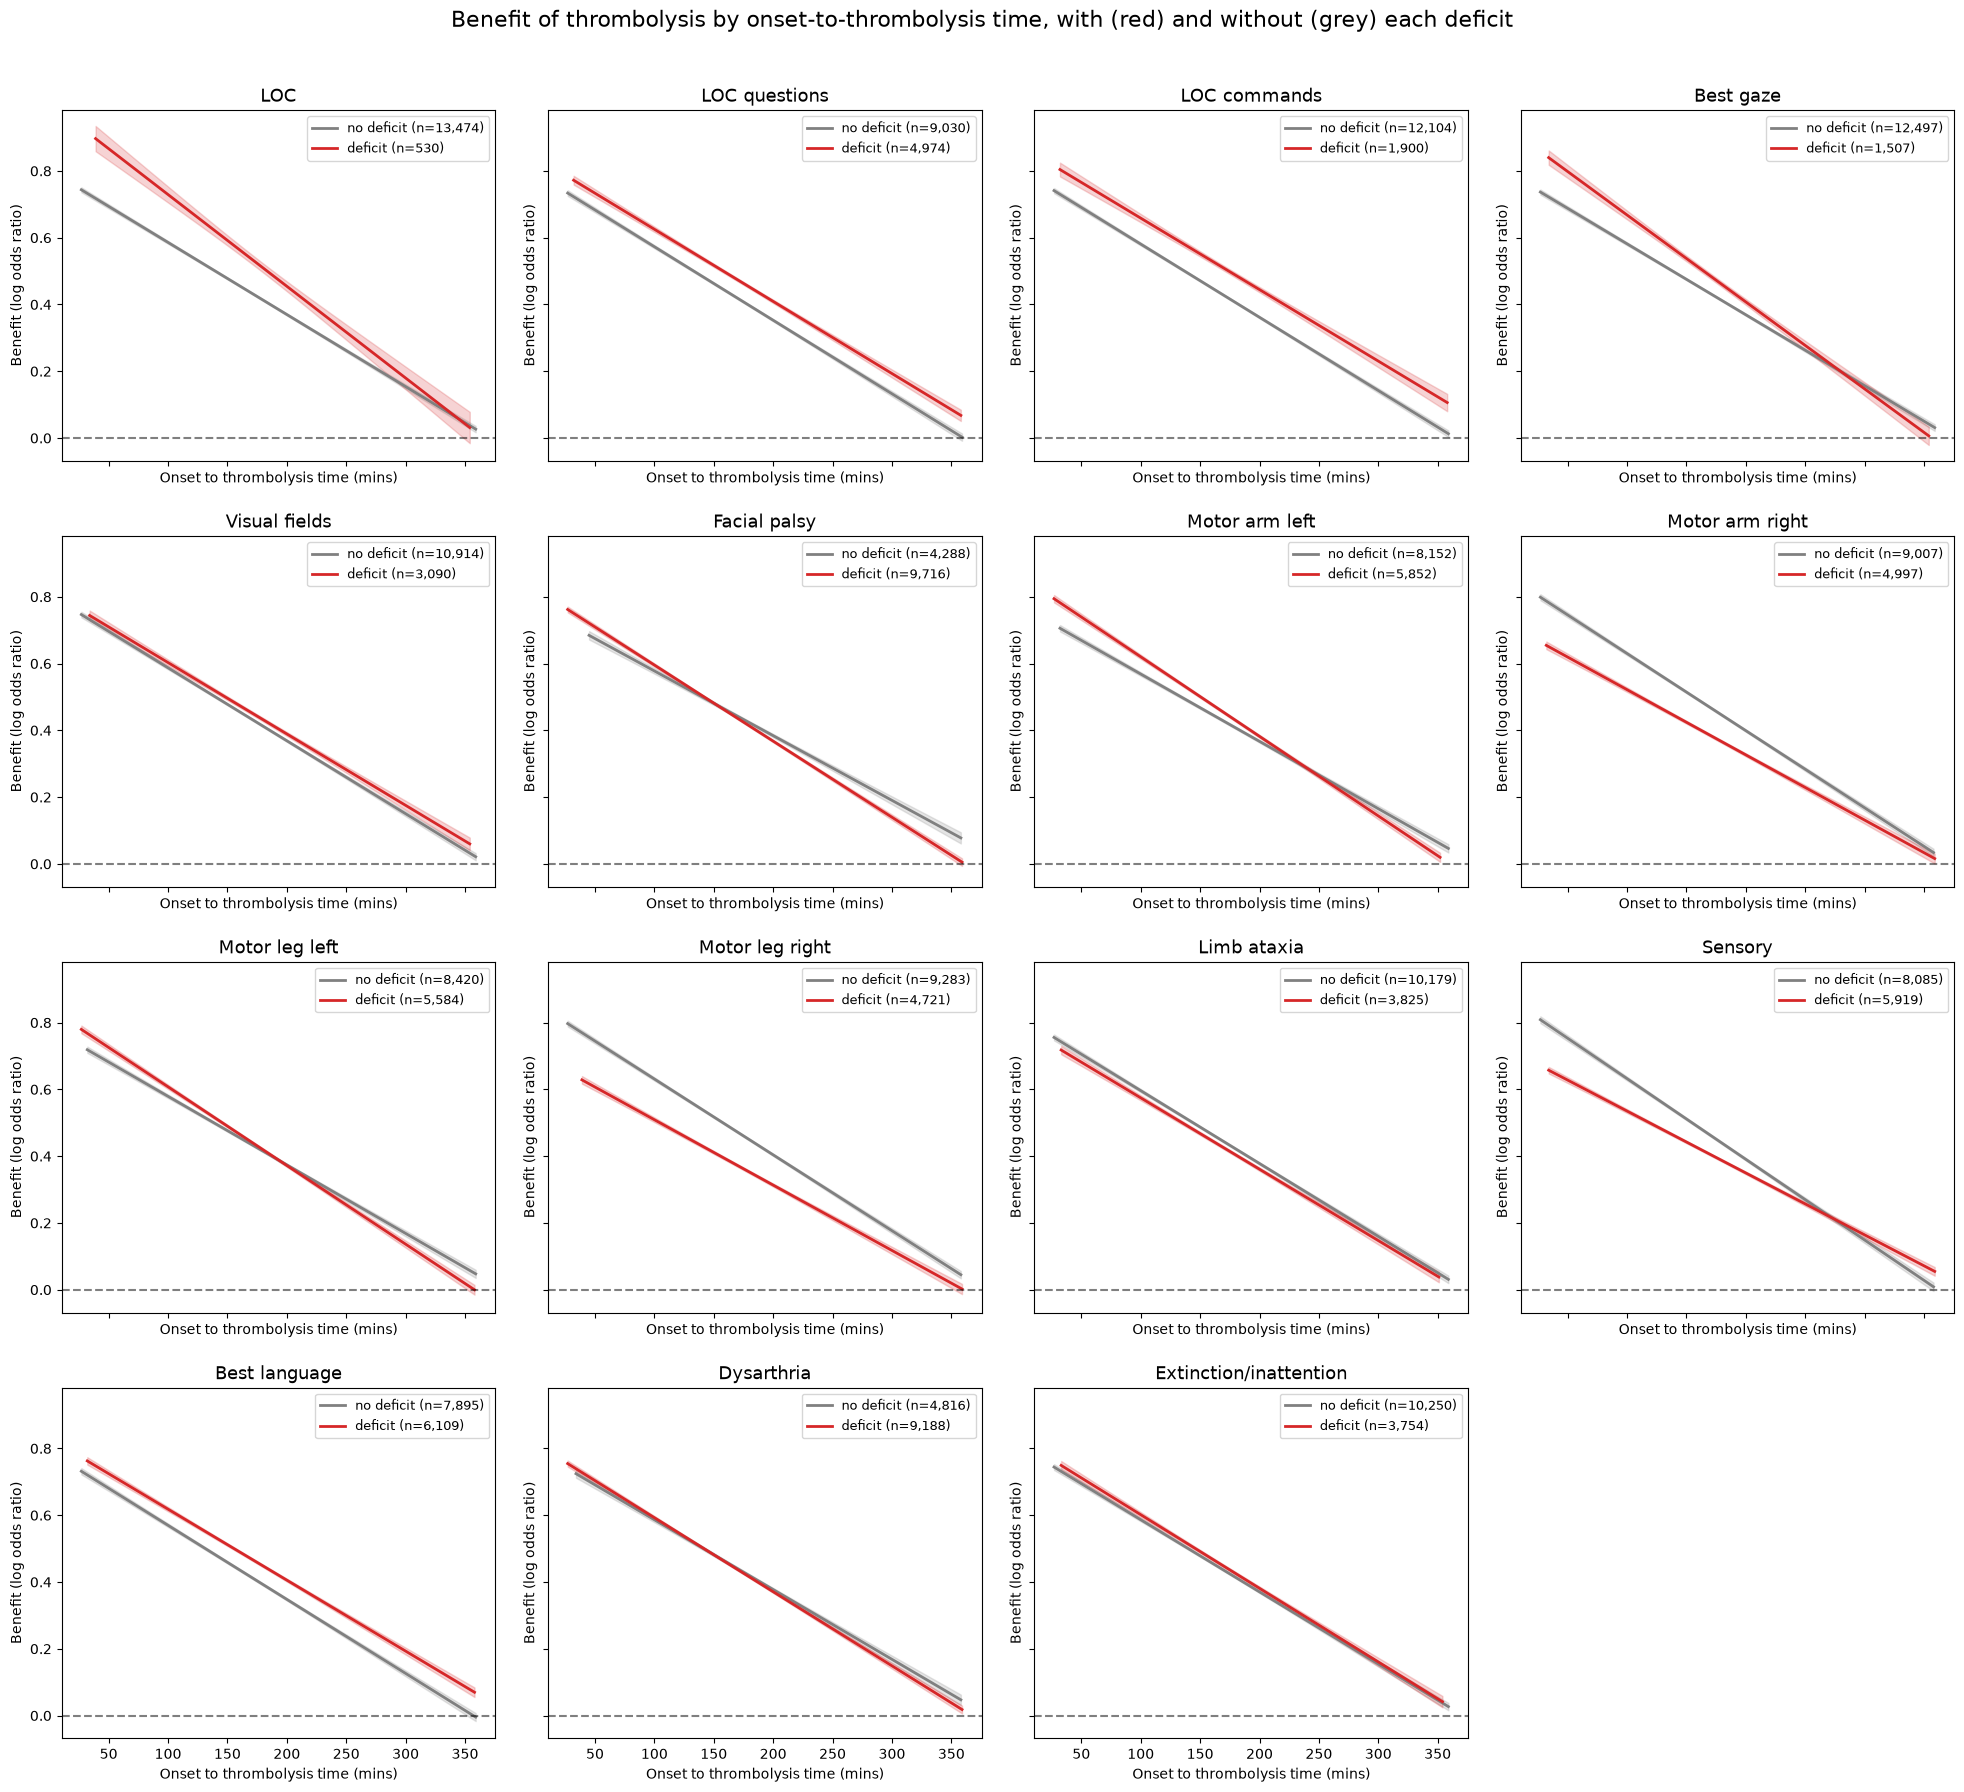

In [25]:
MIN_GROUP_N = 30

def deficit_split(cf_, component):
    """Thrombolysed patients with and without a deficit on one NIHSS item."""
    return {"deficit": cf_[cf_[component] > 0], "no deficit": cf_[cf_[component] == 0]}

deficit_fits, deficit_time_rows = {}, []
for c in NIHSS_COMPONENTS:
    for status, group in deficit_split(cf, c).items():
        if len(group) < MIN_GROUP_N:
            continue
        ols, result = fit_time_regression(group)
        deficit_fits[(c, status)] = ols
        deficit_time_rows.append({"component": label(c), "group": status, **result})

time_by_deficit = pd.DataFrame(deficit_time_rows).set_index(["component", "group"])
time_by_deficit.to_csv(output_path("time_effect_by_nihss_item.csv"))
display(time_by_deficit[["n", "intercept", "slope per hour", "R-squared", "time at zero benefit",
                         "time at zero CI lower", "time at zero CI upper"]].round(3))

fig, axes = plt.subplots(4, 4, figsize=(20, 18), sharex=True, sharey=True)
for ax, c in zip(axes.flat, NIHSS_COMPONENTS):
    for status, colour in [("no deficit", "grey"), ("deficit", "tab:red")]:
        if (c, status) not in deficit_fits:
            continue
        group = deficit_split(cf, c)[status]
        x_grid = np.linspace(group[TIME_THROMBOLYSIS].min(), group[TIME_THROMBOLYSIS].max(), 200)
        prediction = deficit_fits[(c, status)].get_prediction(
            pd.DataFrame({"const": 1.0, TIME_THROMBOLYSIS: x_grid})).summary_frame()
        ax.plot(x_grid, prediction["mean"], color=colour, linewidth=2, label=f"{status} (n={len(group):,})")
        ax.fill_between(x_grid, prediction["mean_ci_lower"], prediction["mean_ci_upper"], color=colour, alpha=0.2)
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(label(c), fontsize=13)
    ax.set_xlabel("Onset to thrombolysis time (mins)")
    ax.set_ylabel("Benefit (log odds ratio)")
    ax.legend(fontsize=9)
for ax in axes.flat[len(NIHSS_COMPONENTS):]:
    ax.axis("off")
fig.suptitle("Benefit of thrombolysis by onset-to-thrombolysis time, with (red) and without (grey) each deficit",
             fontsize=16, y=1.0)
plt.tight_layout(pad=2)
plt.savefig(output_path("thrombolysis_time_effect_by_nihss_item.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**
* The slopes are very similar with and without each deficit: −0.11 to −0.17 log OR per hour.
* **Higher lines** (more benefit at any time): LOC (time zero 1.00 vs 0.80), gaze (0.93 vs 0.79), LOC commands (0.87 vs 0.80) and left arm weakness (0.86 vs 0.77).
* **Lower lines**: right arm and leg weakness (0.71–0.72 vs 0.86), and sensory deficits (0.72 vs 0.87).
* **Benefit-reaches-zero times** are all extrapolations beyond 6 hours (356–408 minutes), and should not be interpreted.
* These OLS CIs are too narrow (see Section 3.5).

# 4. Meta-model of benefit

## 4.1 Method

An XGBoost regression model is fitted to the individual estimated benefit (log odds ratio) of thrombolysed patients. It uses the same features as the S-learner, including the 15 NIHSS items, onset-to-thrombolysis time and stroke team. SHAP values for this meta-model show which characteristics are associated with larger or smaller estimated benefit (treatment-effect heterogeneity), each adjusted for the others. This is the main analysis of *which NIHSS deficits modify the benefit of thrombolysis*.

* In-sample R² is optimistic, because the model is evaluated on its own training data, so a 5-fold out-of-fold R² is also reported.
* The meta-model describes the S-learner's estimates. It cannot find heterogeneity that the S-learner did not estimate, and it inherits any bias in it.

In [26]:
meta_X = cf[X_FIELDS]
meta_y = cf["log_odds_diff"]

def make_meta_model():
    return XGBRegressor(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="rmse")

meta_model = make_meta_model().fit(meta_X, meta_y)
cf["predicted_log_odds_diff"] = meta_model.predict(meta_X)
cf["oof_predicted_log_odds_diff"] = cross_val_predict(
    make_meta_model(), meta_X, meta_y,
    cv=KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
)

r2_in_sample = r2_score(meta_y, cf["predicted_log_odds_diff"])
r2_out_of_fold = r2_score(meta_y, cf["oof_predicted_log_odds_diff"])
print(f"Meta-model R-squared: in-sample {r2_in_sample:.4f}, out-of-fold {r2_out_of_fold:.4f}")

Meta-model R-squared: in-sample 0.9678, out-of-fold 0.8036


**Results.** The meta-model reproduces the S-learner's estimated benefit closely: R² is 0.97 in-sample and 0.80 out-of-fold. Most of the variation in estimated benefit is therefore systematic, i.e. explained by patient features and stroke team. The plot below compares the meta-model's predictions with the S-learner's estimates.

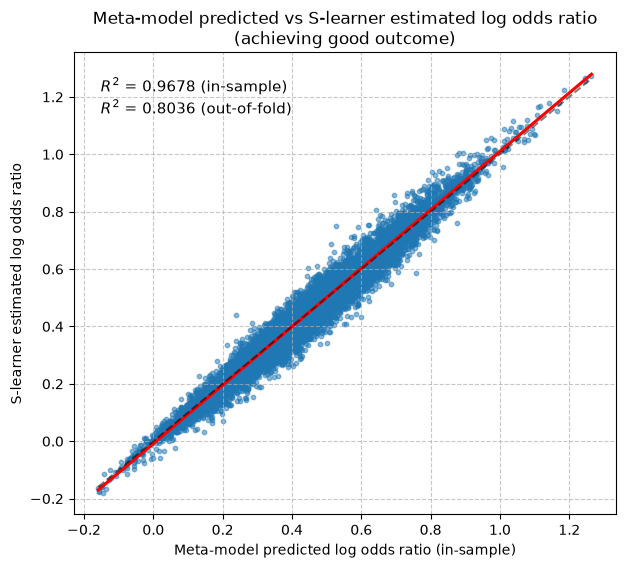

In [27]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.regplot(x="predicted_log_odds_diff", y="log_odds_diff", data=cf, ci=95, ax=ax,
            scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
limits = [cf["predicted_log_odds_diff"].min(), cf["predicted_log_odds_diff"].max()]
ax.plot(limits, limits, color="black", linestyle="--", alpha=0.5)  # y = x
ax.set_title(f"Meta-model predicted vs S-learner estimated log odds ratio\n(achieving good outcome)")
ax.set_xlabel("Meta-model predicted log odds ratio (in-sample)")
ax.set_ylabel("S-learner estimated log odds ratio")
ax.grid(linestyle="--", alpha=0.7)
ax.text(0.05, 0.95, f"$R^2$ = {r2_in_sample:.4f} (in-sample)\n$R^2$ = {r2_out_of_fold:.4f} (out-of-fold)",
        transform=ax.transAxes, fontsize=11, verticalalignment="top")
plt.show()

**Results.** The meta-model's predictions lie close to the S-learner's estimates around the line of equality (R² 0.97 in-sample, 0.80 out-of-fold), so the SHAP values below describe the S-learner's estimated benefit well.

## 4.2 SHAP values for the meta-model

Positive SHAP values mean the feature value is associated with *greater* estimated benefit from thrombolysis. The SHAP base value is the value to which the feature SHAP values are added to give each patient's predicted benefit (log odds ratio). The bar chart ranks features by mean |SHAP|, with NIHSS items in red.

SHAP base value (value the feature SHAP values are added to): 0.435 log odds ratio


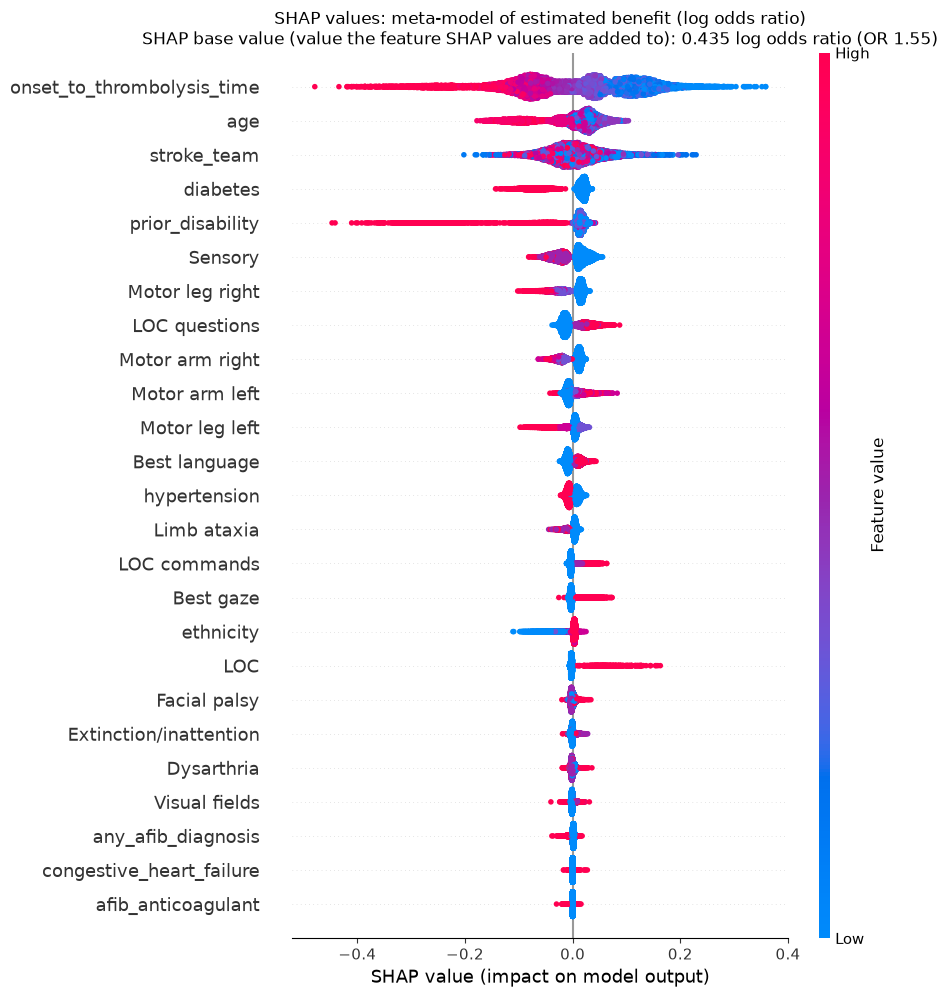

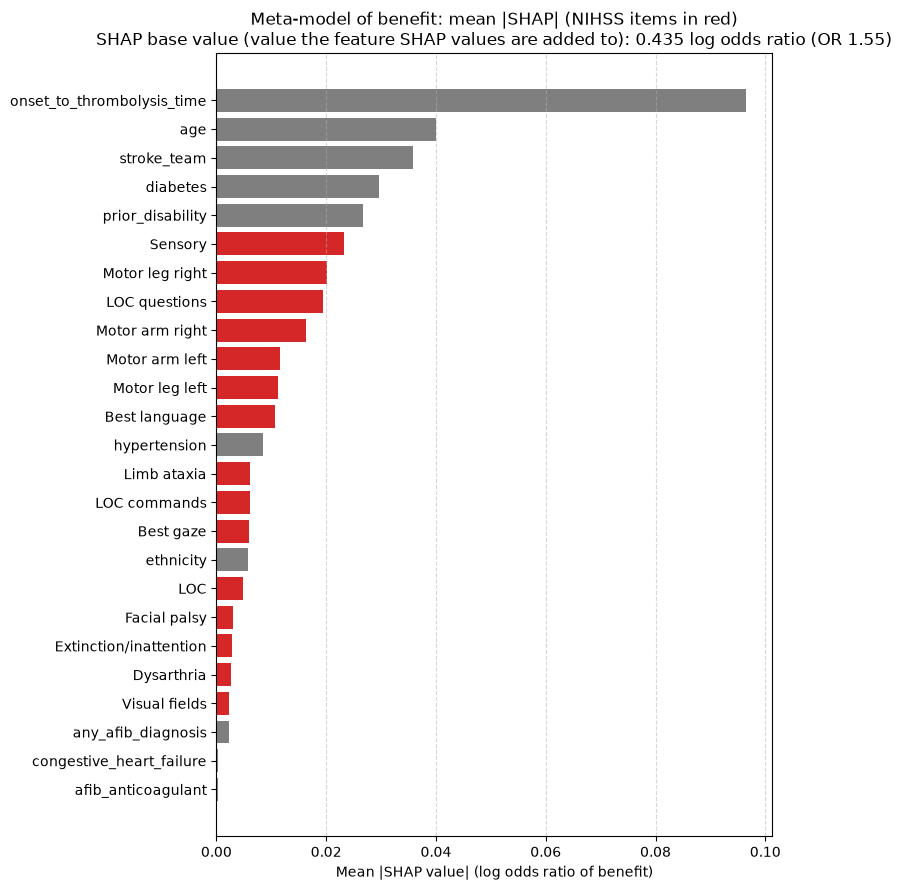

In [28]:
meta_explainer = shap.Explainer(meta_model)
meta_shap_values = meta_explainer(meta_X)
base_value = float(np.ravel(meta_explainer.expected_value)[0])
print(f"SHAP base value (value the feature SHAP values are added to): {base_value:.3f} log odds ratio")
meta_shap_df = pd.DataFrame(meta_shap_values.values, columns=meta_X.columns, index=meta_X.index)

meta_explanation = shap.Explanation(
    values=meta_shap_values.values,
    base_values=meta_shap_values.base_values,
    data=shap_display_data(meta_X).to_numpy(),
    feature_names=[label(c) for c in meta_X.columns],
)
shap.plots.beeswarm(meta_explanation, max_display=99, show=False)
plt.title(f"SHAP values: meta-model of estimated benefit (log odds ratio)\n"
          f"SHAP base value (value the feature SHAP values are added to): {base_value:.3f} log odds ratio (OR {np.exp(base_value):.2f})")
plt.savefig(output_path("treatment_effect_shap_beeswarm.png"), dpi=300, bbox_inches="tight")
plt.show()

meta_importance = plot_mean_abs_shap(
    meta_shap_df, f"Meta-model of benefit: mean |SHAP| (NIHSS items in red)\n"
    f"SHAP base value (value the feature SHAP values are added to): {base_value:.3f} log odds ratio (OR {np.exp(base_value):.2f})",
    "Mean |SHAP value| (log odds ratio of benefit)", output_path("treatment_effect_shap_importance.png"))

**Results.** The SHAP base value (value the feature SHAP values are added to) is 0.44 log odds ratio.
* **Time to thrombolysis** is by far the main driver of variation in benefit (mean |SHAP| about 0.10).
* **Patient factors** come next: age (0.04), stroke team (0.035), diabetes (0.03) and pre-stroke mRS (0.03). Unlike in mild stroke, these outrank every NIHSS item.
* **NIHSS items** have small effects: sensory (0.023), right leg weakness (0.02), LOC questions (0.02), right arm weakness (0.016), left arm and leg weakness and language (about 0.011). The other items are under 0.01.

## 4.3 Meta-model SHAP values by NIHSS item score

One panel per NIHSS item; all panels use the same y-axis scale, and box whiskers show the full range.

* Black dashed line: SHAP = 0 (no change from the SHAP base value).
* Red dotted line: SHAP = −base value. An item score whose SHAP falls to this line would, on its own, bring the predicted benefit down to zero (if other features did not compensate).

The table gives, for each item, the mean SHAP in thrombolysed patients with and without the deficit and the difference: the adjusted change in benefit associated with the deficit.

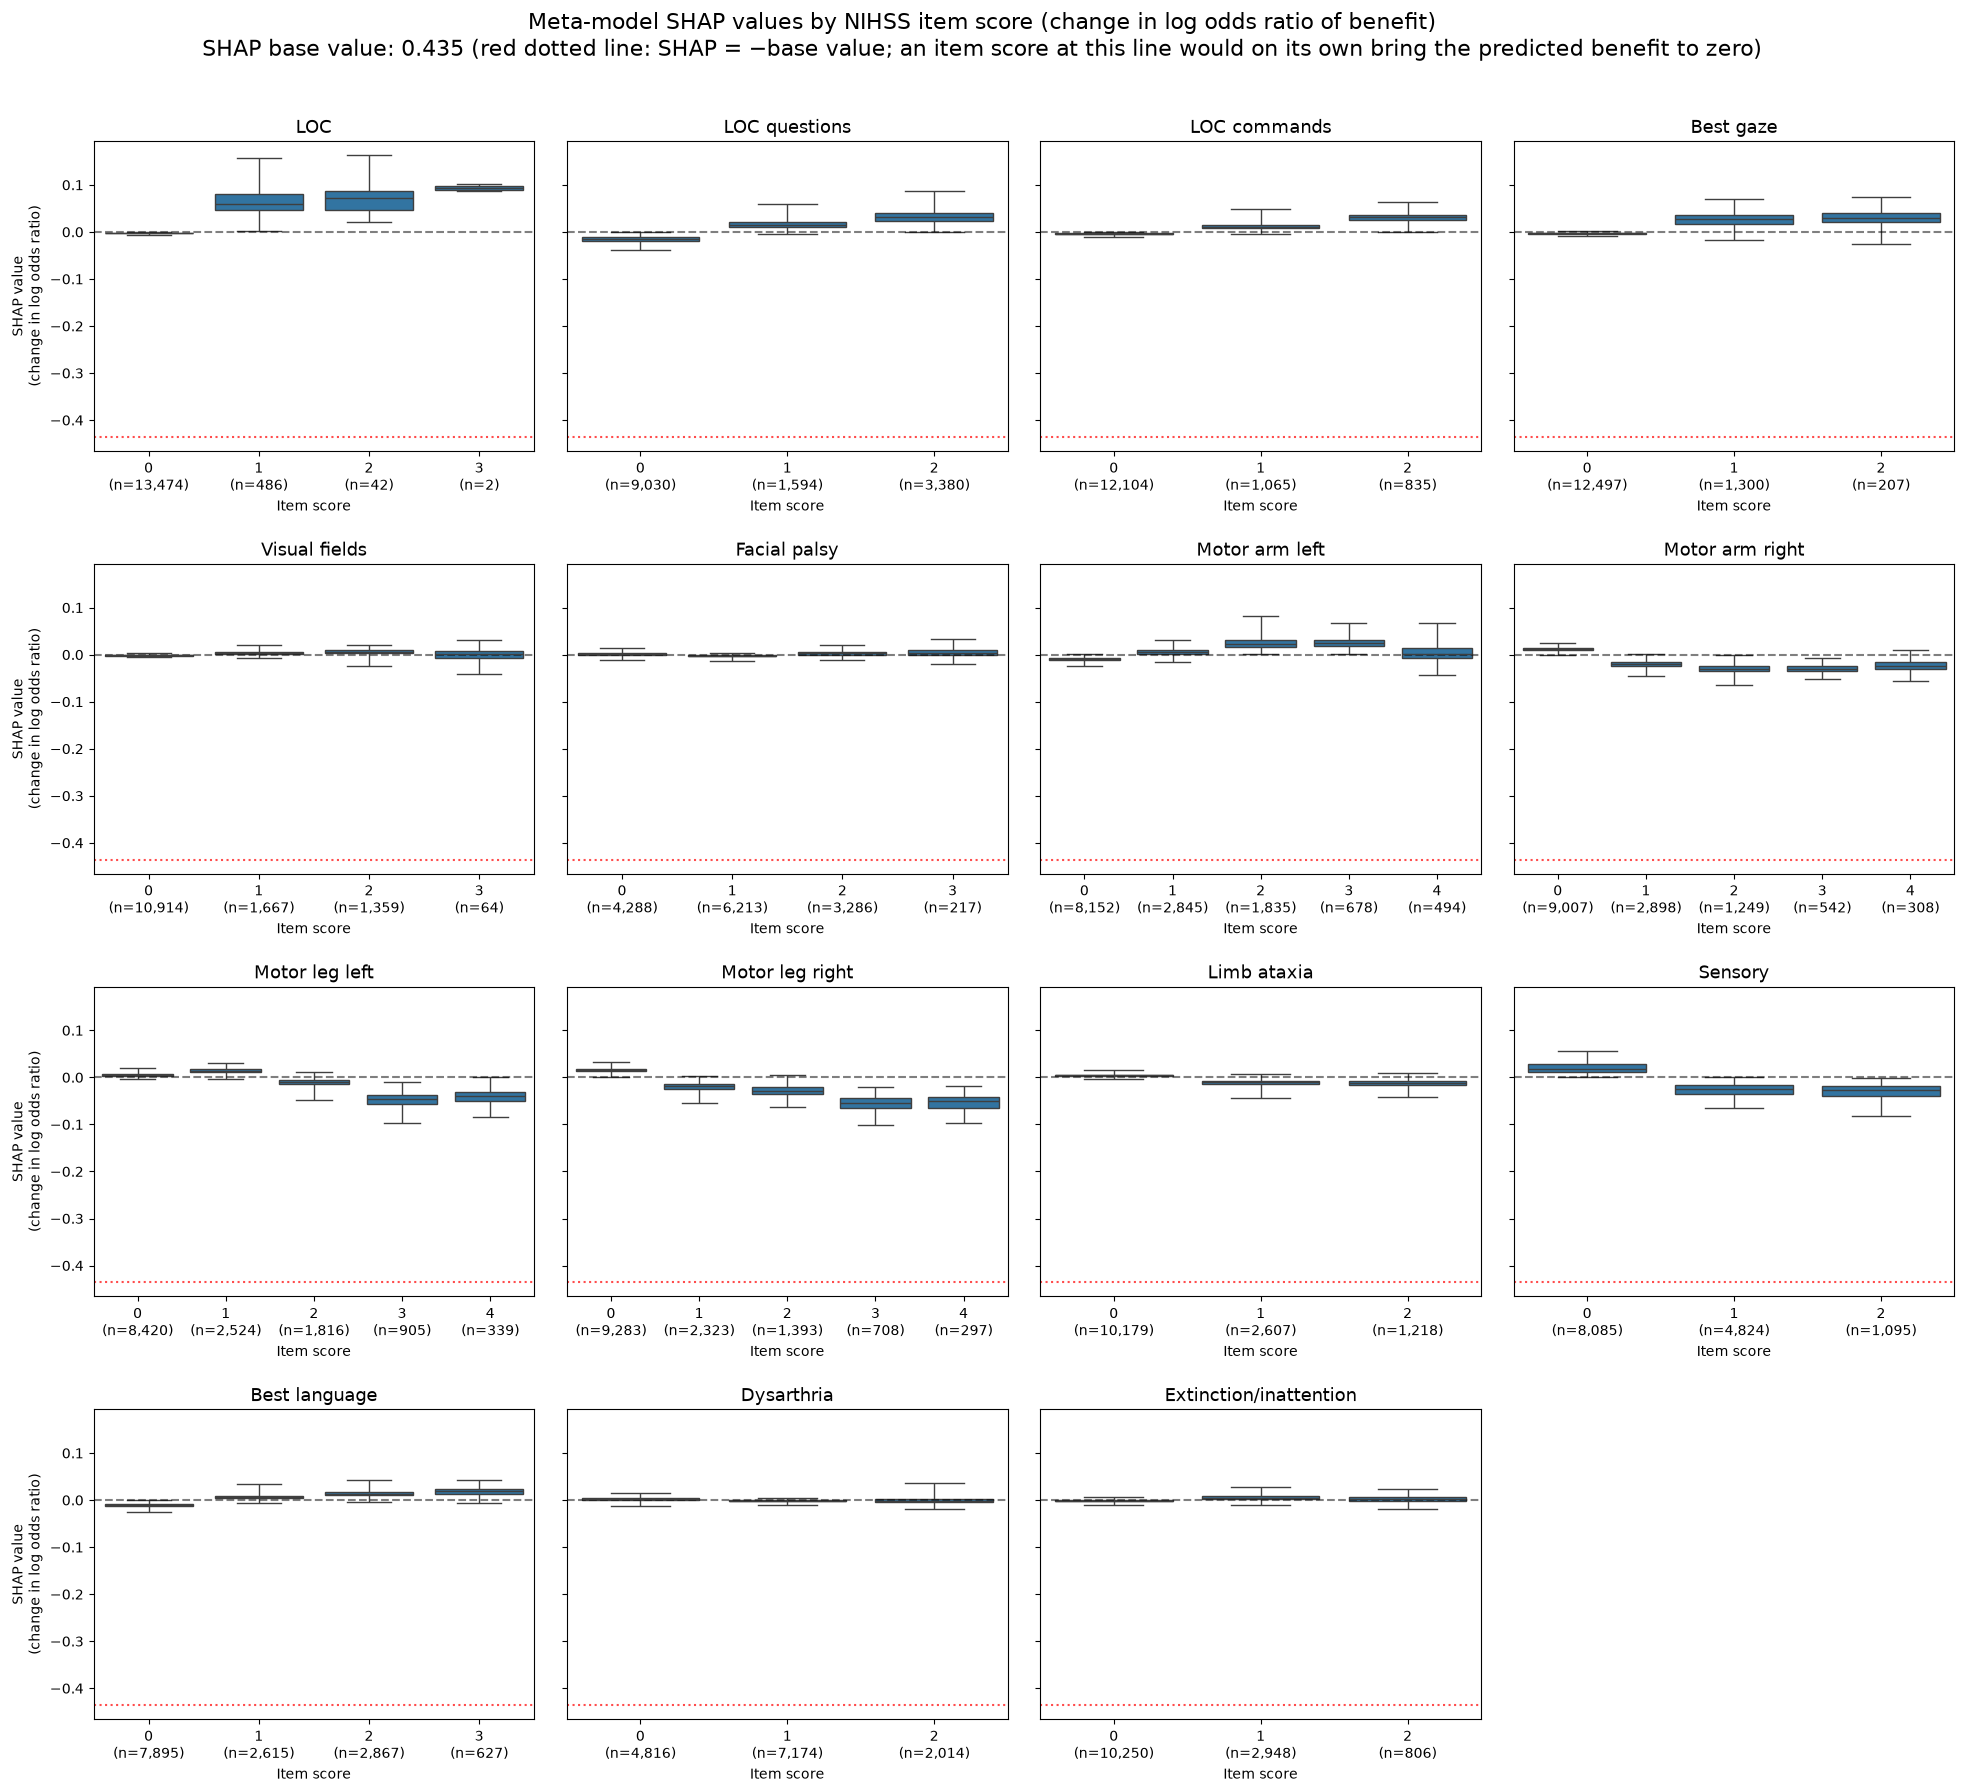

,patients with deficit,mean |SHAP|,"mean SHAP, deficit","mean SHAP, no deficit",SHAP difference (deficit - none)
component,,,,,
LOC,530,0.005,0.066,-0.002,0.068
LOC questions,4974,0.019,0.028,-0.015,0.042
Best gaze,1507,0.006,0.028,-0.003,0.031
LOC commands,1900,0.006,0.020,-0.004,0.024
Motor arm left,5852,0.012,0.014,-0.009,0.023
Best language,6109,0.011,0.012,-0.010,0.021
Extinction/inattention,3754,0.003,0.005,-0.002,0.007
Visual fields,3090,0.002,0.005,-0.001,0.006
Facial palsy,9716,0.003,-0.000,0.001,-0.001


In [29]:
plot_component_shap(
    meta_shap_df, meta_X,
    f"Meta-model SHAP values by NIHSS item score (change in log odds ratio of benefit)\n"
    f"SHAP base value: {base_value:.3f} (red dotted line: SHAP = −base value; an item score at this line would on its own bring the predicted benefit to zero)",
    "SHAP value\n(change in log odds ratio)", output_path("treatment_effect_shap_by_nihss_item.png"),
    reference=-base_value)

benefit_modifiers = deficit_shap_table(meta_shap_df, meta_X).sort_values("SHAP difference (deficit - none)",
                                                                          ascending=False)
benefit_modifiers.to_csv(output_path("benefit_modification_by_nihss_item.csv"))
benefit_modifiers.round(3)

**Results.** Adjusted for the other features, a deficit changes the estimated benefit as follows (mean SHAP with minus without, log odds ratio):
* **More benefit**: LOC +0.07, LOC questions +0.04, best gaze +0.03, LOC commands +0.02, left arm weakness +0.02 and language +0.02.
* **No change**: extinction/inattention, visual fields, facial palsy and dysarthria (−0.004 to +0.007).
* **Less benefit**: sensory −0.05, right leg weakness −0.045, right arm weakness −0.04, limb ataxia −0.015 and left leg weakness −0.01.

Compared with the mean estimated benefit in thrombolysed patients (log OR 0.44, Section 2.5), these are all small changes (under ±15%). The deficit pattern resembles that for NIHSS 1–5: consciousness and gaze deficits are associated with more benefit, and sensory and ataxia deficits with less. Right-sided weakness also marks smaller benefit here.

## 4.4 Meta-model SHAP values for other features

As in 4.3, for the other features (stroke team is in the model but not plotted). Thrombolysis time is grouped into 30-minute bins.

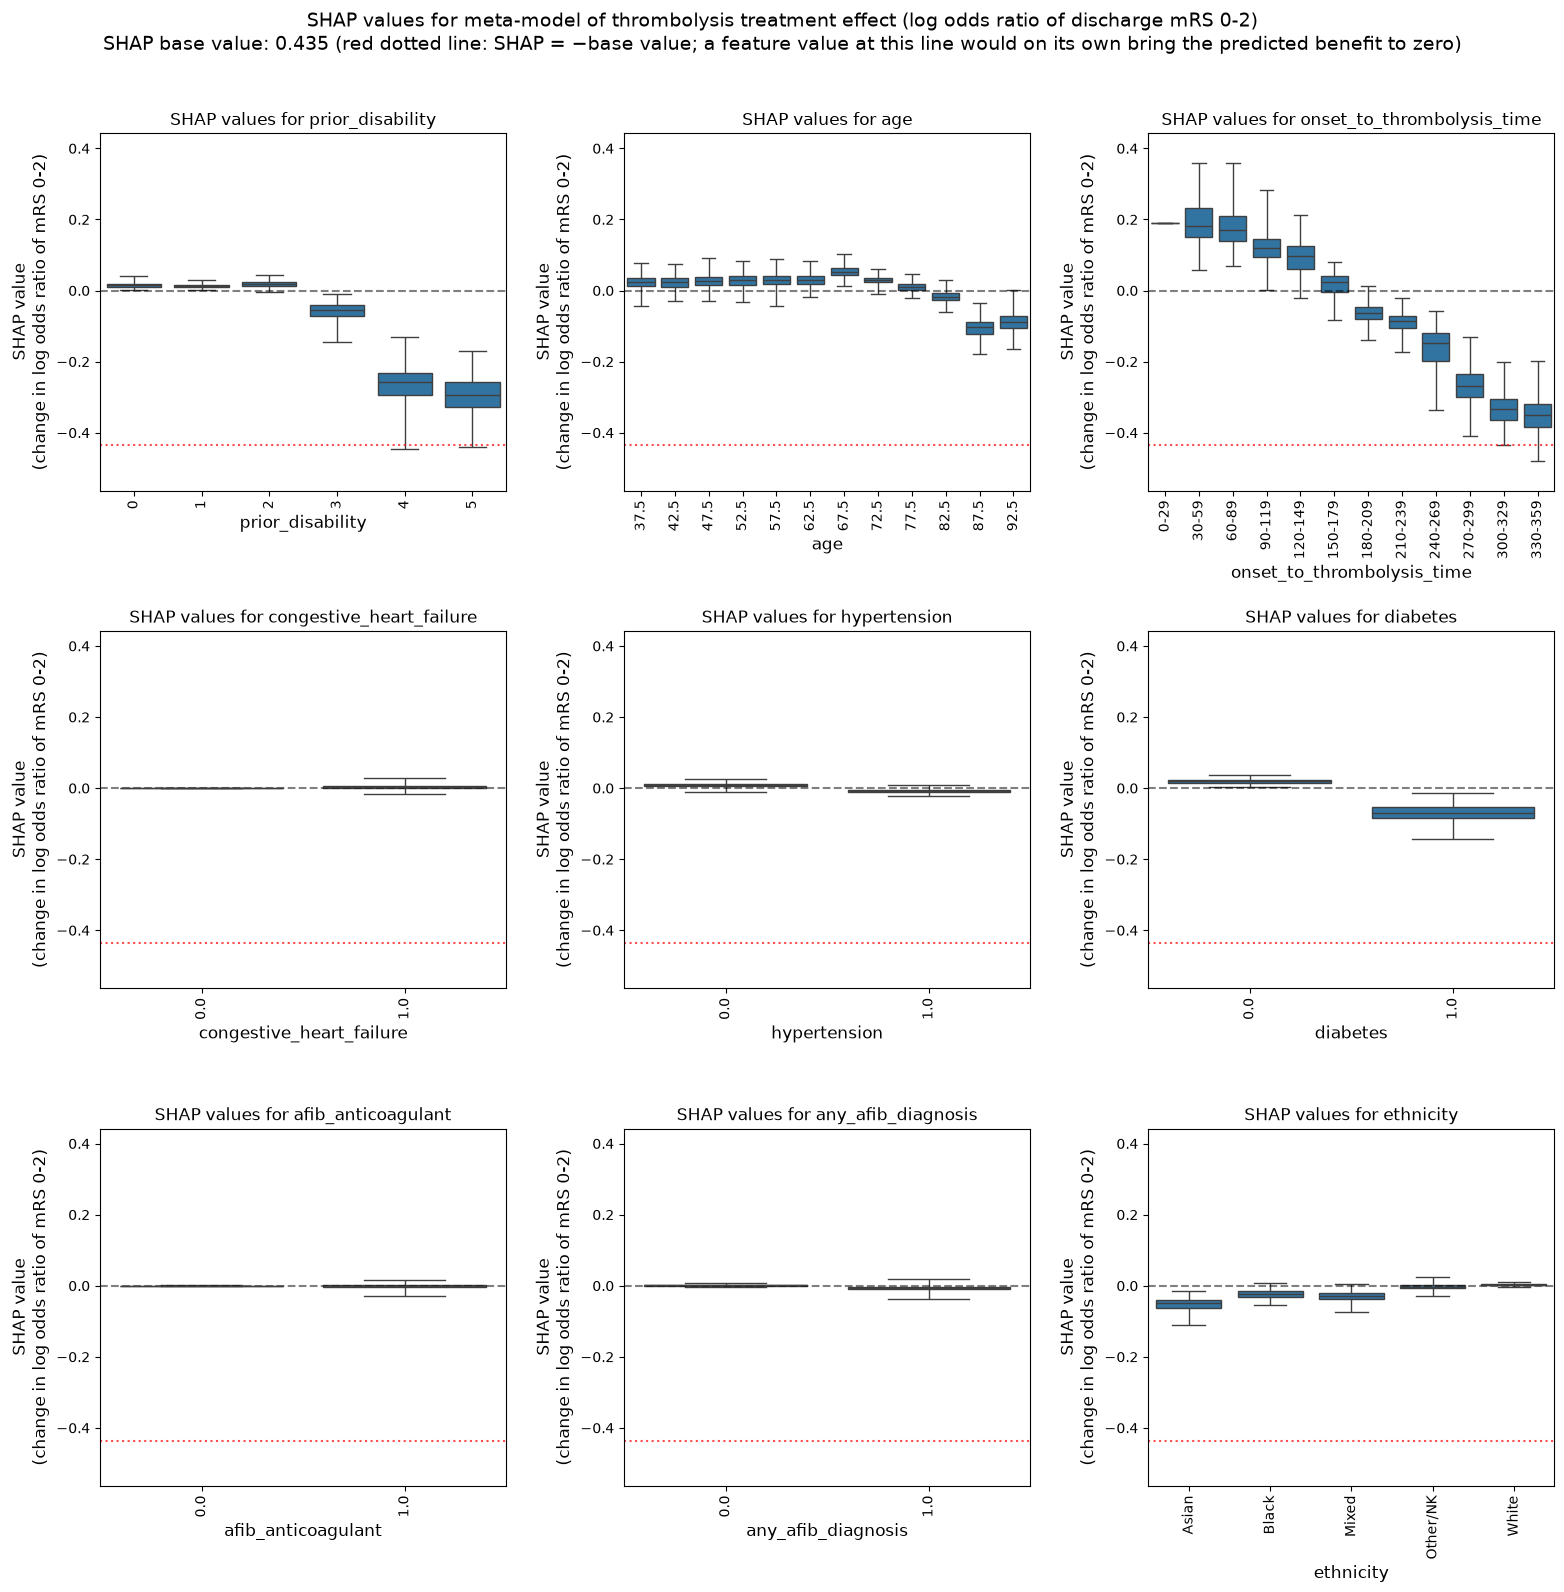

In [30]:
shap_min, shap_max = meta_shap_df.min().min(), meta_shap_df.max().max()
padding = 0.1 * (shap_max - shap_min)
y_limits = (min(shap_min, -base_value) - padding, shap_max + padding)

fig, axes = plt.subplots(3, 3, figsize=(16, 16))

for ax, feature in zip(axes.flat, OTHER_EFFECT_FEATURES):
    plot_df = pd.DataFrame({
        "feature_value": meta_X[feature].to_numpy(),
        "shap_value": meta_shap_df[feature].to_numpy(),
    }).dropna()
    if feature == TIME_THROMBOLYSIS:
        plot_df["feature_value"] = (pd.to_numeric(plot_df["feature_value"]) // 30 * 30).astype(int)
    order = sorted(plot_df["feature_value"].unique())

    sns.boxplot(data=plot_df, x="feature_value", y="shap_value", order=order, ax=ax, whis=(0, 100))
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.axhline(-base_value, color="red", linestyle="dotted", alpha=0.7)
    ax.set_ylim(y_limits)
    ax.set_title(f"SHAP values for {feature}")
    ax.set_xlabel(feature, fontsize=12)
    ax.set_ylabel(f"SHAP value\n(change in log odds ratio of mRS 0-{MRS_TARGET})", fontsize=12)
    ax.tick_params(axis="x", rotation=90, labelsize=10)

    if feature == TIME_THROMBOLYSIS:
        ax.set_xticklabels(time_bin_labels(order))

fig.suptitle(
    f"SHAP values for meta-model of thrombolysis treatment effect (log odds ratio of discharge mRS 0-{MRS_TARGET})\n"
    f"SHAP base value: {base_value:.3f} (red dotted line: SHAP = −base value; a feature value at this line would on its own bring the predicted benefit to zero)",
    fontsize=14, y=1.00,
)
plt.tight_layout(pad=2)
plt.savefig(output_path("shap_box_plots_other_features.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.**
* **Pre-stroke mRS** has a large effect: mRS 4–5 subtracts about 0.25–0.3 from the log odds ratio. That is most of the way to the red line (−0.44), at which the predicted benefit would be zero.
* **Time to thrombolysis.**
  * Treatment within about 2 hours adds +0.1 to +0.2.
  * After 3 hours it subtracts.
  * After 4.5 hours it subtracts about 0.3–0.35.
* **Age over 85** subtracts about 0.1.
* **Diabetes** subtracts about 0.05.
* **Other comorbidities and ethnicity** are close to zero.

# 5. Uncertainty, discrimination and calibration

## 5.1 Uncertainty from refitting the model

The confidence intervals in Sections 2 and 3 reflect variation between patients' predicted effects only. Here the whole pipeline is repeated on `N_BOOT` (30) bootstrap samples of patients, with the tuned hyperparameters held fixed. Each repeat consists of:
* five-fold cross-validation, with copies of the same patient kept in one fold;
* out-of-fold counterfactual predictions for thrombolysed patients;
* the mean effect overall, and in thrombolysed patients with and without a deficit on each NIHSS item;
* the time at which predicted benefit reaches zero.

The 95% CI is the point estimate ± 1.96 × the bootstrap standard deviation. The same is done for the **difference** in mean benefit between patients with and without each deficit, which is the most direct test of whether a deficit marks out patients who benefit more or less. Results are also printed as LaTeX rows.

In [31]:
# Uncertainty in the S-learner effect from refitting the model.
# The whole pipeline is repeated on N_BOOT bootstrap samples of patients, with the tuned hyperparameters held fixed:
# five-fold cross-validation (copies of the same patient are kept in one fold), out-of-fold counterfactual
# predictions for thrombolysed patients, the mean effect overall and with/without each NIHSS item deficit, and the
# time at which predicted benefit reaches zero. The 95% CI is the point estimate +/- 1.96 x the bootstrap SD.
N_BOOT = 30
EFFECT_GROUPS = ["All"] + [g for c in NIHSS_COMPONENTS for g in (deficit_group(c), no_deficit_group(c))]

def effect_subgroups(cf_):
    """All thrombolysed patients, and those with and without a deficit on each NIHSS item."""
    groups = {"All": cf_}
    for c in NIHSS_COMPONENTS:
        groups[deficit_group(c)] = cf_[cf_[c] > 0]
        groups[no_deficit_group(c)] = cf_[cf_[c] == 0]
    return groups

def effect_estimates(cf_):
    """Mean effect (probability difference and log odds ratio) and time at zero benefit, by group."""
    rows = []
    for name, g in effect_subgroups(cf_).items():
        rows.append({
            "group": name, "n": len(g),
            "prob_diff": g["treatment_diff_prob"].mean(),
            "log_odds_diff": g["log_odds_diff"].mean(),
            "time_at_zero": (fit_time_regression(g)[1]["time at zero benefit"]
                             if len(g) >= MIN_GROUP_N else np.nan),
        })
    return pd.DataFrame(rows).set_index("group").reindex(EFFECT_GROUPS)

def deficit_contrasts(estimates):
    """Difference in mean benefit between patients with and without each deficit."""
    rows = []
    for c in NIHSS_COMPONENTS:
        with_deficit, without = estimates.loc[deficit_group(c)], estimates.loc[no_deficit_group(c)]
        rows.append({"component": label(c),
                     "prob_diff": with_deficit["prob_diff"] - without["prob_diff"],
                     "log_odds_diff": with_deficit["log_odds_diff"] - without["log_odds_diff"]})
    return pd.DataFrame(rows).set_index("component")

point_estimates = effect_estimates(cf)

boot_rng = np.random.default_rng(RANDOM_STATE)
X_all = data[X_FIELDS]
patient_fold = boot_rng.integers(0, N_SPLITS, len(data))  # fold for each original patient
boot_rows = []
for b in range(N_BOOT):
    idx = boot_rng.integers(0, len(data), len(data))
    Xb = X_all.iloc[idx].reset_index(drop=True)
    yb = y.iloc[idx].reset_index(drop=True)
    fold_b = patient_fold[idx]
    folds_b = [(Xb[fold_b != k], Xb[fold_b == k], yb[fold_b != k], yb[fold_b == k]) for k in range(N_SPLITS)]
    models_b, _ = train_and_evaluate(folds_b, xgb_factory(**best_params))
    estimates_b = effect_estimates(predict_thrombolysis_counterfactuals(models_b, folds_b))
    estimates_b["bootstrap"] = b
    boot_rows.append(estimates_b.reset_index())
    print(f"Bootstrap {b + 1}/{N_BOOT} done")

bootstrap_effects = pd.concat(boot_rows, ignore_index=True)
bootstrap_effects.to_csv(output_path("bootstrap_effects.csv"), index=False)

boot_sd = bootstrap_effects.groupby("group")[["prob_diff", "log_odds_diff", "time_at_zero"]].std(ddof=1)
bootstrap_summary = point_estimates.copy()
for col in ["prob_diff", "log_odds_diff", "time_at_zero"]:
    se = boot_sd[col].reindex(bootstrap_summary.index)
    bootstrap_summary[f"{col}_ci_lower"] = bootstrap_summary[col] - 1.96 * se
    bootstrap_summary[f"{col}_ci_upper"] = bootstrap_summary[col] + 1.96 * se
bootstrap_summary["odds_ratio"] = np.exp(bootstrap_summary["log_odds_diff"])
bootstrap_summary["odds_ratio_ci_lower"] = np.exp(bootstrap_summary["log_odds_diff_ci_lower"])
bootstrap_summary["odds_ratio_ci_upper"] = np.exp(bootstrap_summary["log_odds_diff_ci_upper"])
bootstrap_summary.to_csv(output_path("bootstrap_summary.csv"))

# Differences between patients with and without each deficit, with bootstrap CIs
contrast_point = deficit_contrasts(point_estimates)
contrast_boot = pd.concat([deficit_contrasts(g.set_index("group")) for _, g in bootstrap_effects.groupby("bootstrap")])
contrast_sd = contrast_boot.groupby(level=0).std(ddof=1).reindex(contrast_point.index)
deficit_contrast_summary = contrast_point.copy()
for col in ["prob_diff", "log_odds_diff"]:
    deficit_contrast_summary[f"{col}_ci_lower"] = contrast_point[col] - 1.96 * contrast_sd[col]
    deficit_contrast_summary[f"{col}_ci_upper"] = contrast_point[col] + 1.96 * contrast_sd[col]
deficit_contrast_summary.to_csv(output_path("bootstrap_deficit_contrasts.csv"))

display(bootstrap_summary.loc[["All"] + DEFICIT_GROUPS].round(3))
display((100 * deficit_contrast_summary[["prob_diff", "prob_diff_ci_lower", "prob_diff_ci_upper"]])
        .rename(columns=lambda c: c.replace("prob_diff", "difference pp")).round(1))

print("% ---- S-learner effects with bootstrap 95% CIs: group & n & pp & log OR & OR ----")
for group, r in bootstrap_summary.loc[["All"] + DEFICIT_GROUPS].iterrows():
    print(f"{group} & {int(r['n']):,} & "
          f"{100 * r['prob_diff']:.1f} ({100 * r['prob_diff_ci_lower']:.1f}--{100 * r['prob_diff_ci_upper']:.1f}) & "
          f"{r['log_odds_diff']:.2f} ({r['log_odds_diff_ci_lower']:.2f}--{r['log_odds_diff_ci_upper']:.2f}) & "
          f"{r['odds_ratio']:.2f} ({r['odds_ratio_ci_lower']:.2f}--{r['odds_ratio_ci_upper']:.2f}) \\\\")

Bootstrap 1/30 done
Bootstrap 2/30 done
Bootstrap 3/30 done
Bootstrap 4/30 done
Bootstrap 5/30 done
Bootstrap 6/30 done
Bootstrap 7/30 done
Bootstrap 8/30 done
Bootstrap 9/30 done
Bootstrap 10/30 done
Bootstrap 11/30 done
Bootstrap 12/30 done
Bootstrap 13/30 done
Bootstrap 14/30 done
Bootstrap 15/30 done
Bootstrap 16/30 done
Bootstrap 17/30 done
Bootstrap 18/30 done
Bootstrap 19/30 done
Bootstrap 20/30 done
Bootstrap 21/30 done
Bootstrap 22/30 done
Bootstrap 23/30 done
Bootstrap 24/30 done
Bootstrap 25/30 done
Bootstrap 26/30 done
Bootstrap 27/30 done
Bootstrap 28/30 done
Bootstrap 29/30 done
Bootstrap 30/30 done


,n,prob_diff,log_odds_diff,time_at_zero,prob_diff_ci_lower,prob_diff_ci_upper,log_odds_diff_ci_lower,log_odds_diff_ci_upper,time_at_zero_ci_lower,time_at_zero_ci_upper,odds_ratio,odds_ratio_ci_lower,odds_ratio_ci_upper
group,,,,,,,,,,,,,
All,14004,0.094,0.435,371.780,0.083,0.106,0.379,0.492,307.279,436.281,1.546,1.462,1.635
LOC: deficit,530,0.115,0.516,365.459,0.094,0.136,0.421,0.611,279.108,451.809,1.675,1.523,1.843
LOC questions: deficit,4974,0.103,0.466,389.434,0.084,0.121,0.382,0.551,300.809,478.059,1.594,1.465,1.735
LOC commands: deficit,1900,0.110,0.498,407.656,0.088,0.132,0.399,0.598,279.948,535.363,1.646,1.491,1.818
Best gaze: deficit,1507,0.108,0.478,356.508,0.091,0.125,0.402,0.554,293.486,419.531,1.613,1.494,1.741
Visual fields: deficit,3090,0.099,0.448,382.025,0.085,0.113,0.382,0.513,286.414,477.636,1.565,1.466,1.671
Facial palsy: deficit,9716,0.095,0.438,361.300,0.083,0.107,0.381,0.496,306.131,416.468,1.550,1.463,1.642
Motor arm left: deficit,5852,0.098,0.453,360.271,0.086,0.110,0.397,0.509,303.170,417.371,1.573,1.487,1.664
Motor arm right: deficit,4997,0.082,0.384,367.170,0.066,0.099,0.303,0.464,281.382,452.958,1.468,1.354,1.590


,difference pp,difference pp_ci_lower,difference pp_ci_upper
component,,,
LOC,2.1,0.3,3.9
LOC questions,1.3,-0.5,3.1
LOC commands,1.8,-0.1,3.7
Best gaze,1.6,-0.4,3.5
Visual fields,0.6,-0.7,1.9
Facial palsy,0.3,-1.0,1.6
Motor arm left,0.7,-1.1,2.5
Motor arm right,-1.8,-3.2,-0.5
Motor leg left,0.2,-1.4,1.9


% ---- S-learner effects with bootstrap 95% CIs: group & n & pp & log OR & OR ----
All & 14,004 & 9.4 (8.3--10.6) & 0.44 (0.38--0.49) & 1.55 (1.46--1.63) \\
LOC: deficit & 530 & 11.5 (9.4--13.6) & 0.52 (0.42--0.61) & 1.68 (1.52--1.84) \\
LOC questions: deficit & 4,974 & 10.3 (8.4--12.1) & 0.47 (0.38--0.55) & 1.59 (1.47--1.73) \\
LOC commands: deficit & 1,900 & 11.0 (8.8--13.2) & 0.50 (0.40--0.60) & 1.65 (1.49--1.82) \\
Best gaze: deficit & 1,507 & 10.8 (9.1--12.5) & 0.48 (0.40--0.55) & 1.61 (1.49--1.74) \\
Visual fields: deficit & 3,090 & 9.9 (8.5--11.3) & 0.45 (0.38--0.51) & 1.56 (1.47--1.67) \\
Facial palsy: deficit & 9,716 & 9.5 (8.3--10.7) & 0.44 (0.38--0.50) & 1.55 (1.46--1.64) \\
Motor arm left: deficit & 5,852 & 9.8 (8.6--11.0) & 0.45 (0.40--0.51) & 1.57 (1.49--1.66) \\
Motor arm right: deficit & 4,997 & 8.2 (6.6--9.9) & 0.38 (0.30--0.46) & 1.47 (1.35--1.59) \\
Motor leg left: deficit & 5,584 & 9.6 (8.4--10.7) & 0.44 (0.39--0.49) & 1.55 (1.47--1.64) \\
Motor leg right: deficit &

**Results.** All 30 bootstrap repeats completed. Overall benefit is 9.4 points (bootstrap 95% CI 8.3 to 10.6; OR 1.55, 1.46 to 1.63). The first table gives the benefit with each deficit, and the second the difference from patients without the deficit: LOC (+2.1 points, 0.3 to 3.9) shows clearly more benefit, and right leg (−2.3), right arm (−1.8), sensory (−1.7) and limb ataxia (−0.9) clearly less. The forest plot below shows these results.

Forest plot: mean benefit (percentage points, bootstrap 95% CI) in thrombolysed patients with each deficit (left), and the difference from patients without that deficit (right). The grey dotted line is the average benefit in all thrombolysed patients.

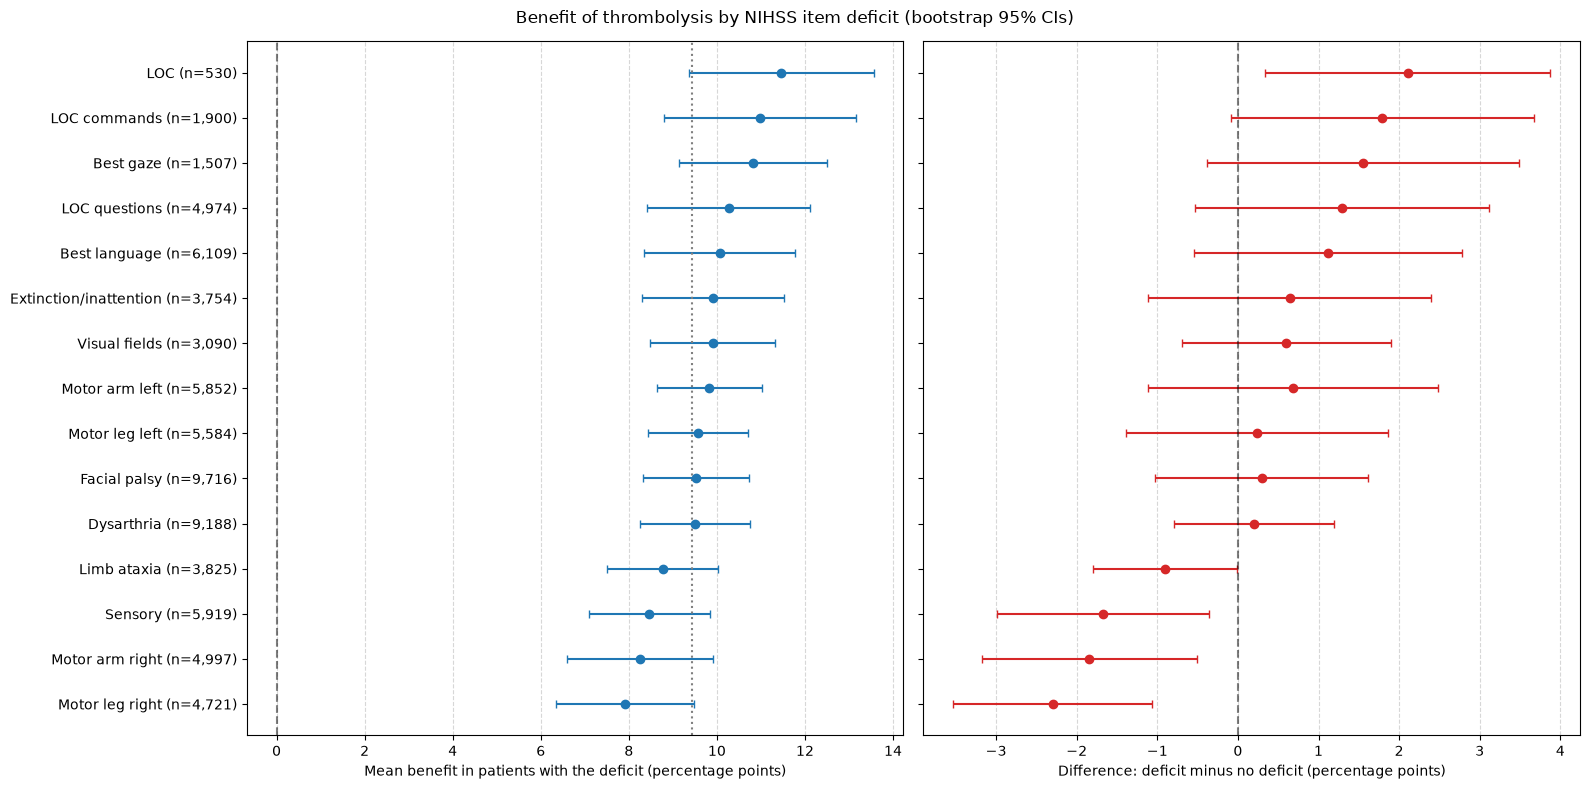

In [32]:
forest = bootstrap_summary.loc[DEFICIT_GROUPS].copy()
forest.index = [g.replace(": deficit", "") for g in forest.index]
forest = forest.join(deficit_contrast_summary, rsuffix="_contrast").sort_values("prob_diff")
y_pos = np.arange(len(forest))

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
axes[0].errorbar(100 * forest["prob_diff"], y_pos,
                 xerr=[100 * (forest["prob_diff"] - forest["prob_diff_ci_lower"]),
                       100 * (forest["prob_diff_ci_upper"] - forest["prob_diff"])], fmt="o", capsize=3)
axes[0].axvline(100 * bootstrap_summary.loc["All", "prob_diff"], color="grey", linestyle="dotted")
axes[0].set_xlabel("Mean benefit in patients with the deficit (percentage points)")
axes[1].errorbar(100 * forest["prob_diff_contrast"], y_pos,
                 xerr=[100 * (forest["prob_diff_contrast"] - forest["prob_diff_ci_lower_contrast"]),
                       100 * (forest["prob_diff_ci_upper_contrast"] - forest["prob_diff_contrast"])],
                 fmt="o", capsize=3, color="tab:red")
axes[1].set_xlabel("Difference: deficit minus no deficit (percentage points)")
for ax in axes:
    ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([f"{name} (n={int(n):,})" for name, n in zip(forest.index, forest["n"])])
fig.suptitle("Benefit of thrombolysis by NIHSS item deficit (bootstrap 95% CIs)")
fig.tight_layout()
fig.savefig(output_path("benefit_by_nihss_item_forest.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Effects in thrombolysed patients, with bootstrap 95% CIs that include model uncertainty:

| Group | n | Benefit, points (95% CI) | log OR (95% CI) | Difference vs no deficit, points (95% CI) |
|---|---|---|---|---|
| All thrombolysed | 14,004 | 9.4 (8.3 to 10.6) | 0.44 (0.38 to 0.49) | – |
| LOC | 530 | 11.5 (9.4 to 13.6) | 0.52 (0.42 to 0.61) | **2.1 (0.3 to 3.9)** |
| LOC commands | 1,900 | 11.0 (8.8 to 13.2) | 0.50 (0.40 to 0.60) | 1.8 (−0.1 to 3.7) |
| Best gaze | 1,507 | 10.8 (9.1 to 12.5) | 0.48 (0.40 to 0.55) | 1.6 (−0.4 to 3.5) |
| LOC questions | 4,974 | 10.3 (8.4 to 12.1) | 0.47 (0.38 to 0.55) | 1.3 (−0.5 to 3.1) |
| Best language | 6,109 | 10.1 (8.3 to 11.8) | 0.47 (0.38 to 0.55) | 1.1 (−0.5 to 2.8) |
| Visual fields | 3,090 | 9.9 (8.5 to 11.3) | 0.45 (0.38 to 0.51) | 0.6 (−0.7 to 1.9) |
| Extinction/inattention | 3,754 | 9.9 (8.3 to 11.5) | 0.45 (0.37 to 0.52) | 0.6 (−1.1 to 2.4) |
| Motor arm left | 5,852 | 9.8 (8.6 to 11.0) | 0.45 (0.40 to 0.51) | 0.7 (−1.1 to 2.5) |
| Motor leg left | 5,584 | 9.6 (8.4 to 10.7) | 0.44 (0.39 to 0.50) | 0.2 (−1.4 to 1.9) |
| Facial palsy | 9,716 | 9.5 (8.3 to 10.7) | 0.44 (0.38 to 0.50) | 0.3 (−1.0 to 1.6) |
| Dysarthria | 9,188 | 9.5 (8.2 to 10.8) | 0.44 (0.38 to 0.50) | 0.2 (−0.8 to 1.2) |
| Limb ataxia | 3,825 | 8.8 (7.5 to 10.0) | 0.42 (0.36 to 0.48) | **−0.9 (−1.8 to −0.0)** |
| Sensory | 5,919 | 8.5 (7.1 to 9.8) | 0.40 (0.34 to 0.47) | **−1.7 (−3.0 to −0.4)** |
| Motor arm right | 4,997 | 8.2 (6.6 to 9.9) | 0.38 (0.30 to 0.46) | **−1.8 (−3.2 to −0.5)** |
| Motor leg right | 4,721 | 7.9 (6.3 to 9.5) | 0.37 (0.29 to 0.44) | **−2.3 (−3.5 to −1.1)** |

* **Overall**: the time at which benefit reaches zero is 372 minutes, with a wide bootstrap CI (307 to 436), because it lies beyond the observed treatment times.
* **With each deficit**: benefit is clearly above zero in every group (at least 6.3 points at the lower limit).
* **Differences from patients without the deficit**:
  * **Clearly smaller benefit**: right-sided weakness (−1.8 and −2.3 points), sensory (−1.7) and limb ataxia (−0.9).
  * **Clearly greater benefit**: LOC (+2.1).
  * LOC commands, gaze, LOC questions and language point towards greater benefit (+1.1 to +1.8), but their CIs include zero.
* These CIs are not adjusted for making 15 comparisons.

## 5.2 Discrimination and calibration

These checks use the primary model's out-of-fold predictions for all patients, with the treatment actually received:
* ROC AUC, with a bootstrap 95% CI;
* calibration by decile of predicted probability;
* the calibration intercept (calibration-in-the-large; 0 is ideal) and slope (1 is ideal), each with a bootstrap 95% CI.

Calibration matters here because treatment effects are differences between predicted probabilities.

,estimate,ci_lower,ci_upper
ROC AUC,0.705,0.701,0.711
Calibration intercept,-0.002,-0.031,0.019
Calibration slope,1.009,0.979,1.037


,n,predicted,observed
decile,,,
1,2782,0.260,0.254
2,2782,0.369,0.361
3,2782,0.442,0.449
4,2781,0.505,0.520
5,2782,0.562,0.563
6,2782,0.614,0.608
7,2781,0.663,0.672
8,2782,0.713,0.698
9,2782,0.766,0.757


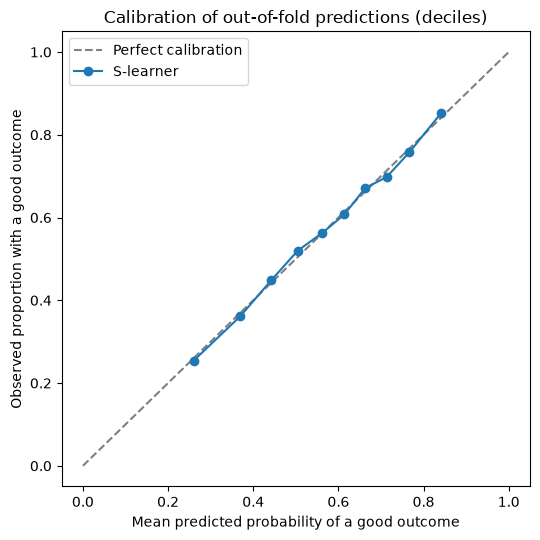

In [33]:
# Discrimination and calibration of the primary model's out-of-fold predictions (all patients, actual treatment):
# ROC AUC, calibration intercept and slope (each with a bootstrap 95% CI), and calibration by decile.
oof_y = pd.concat([test_y for (_, _, _, test_y) in folds]).to_numpy()
oof_p = np.concatenate([model.predict_proba(test_X)[:, 1] for model, (_, test_X, _, _) in zip(models, folds)])

def calibration_intercept_slope(y_true, prob):
    """Calibration intercept (calibration-in-the-large, slope fixed at 1) and slope (logistic
    recalibration of the outcome on the logit of the predicted probability)."""
    logit = to_log_odds(prob)
    slope = LogisticRegression(C=1e12, max_iter=1000).fit(logit.reshape(-1, 1), y_true).coef_[0, 0]
    a = 0.0  # intercept with the slope fixed at 1: Newton iterations for the offset model
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + logit)))
        a += (y_true - p).sum() / (p * (1 - p)).sum()
    return a, slope

def bootstrap_performance(y_true, prob, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Point estimates and percentile 95% CIs for ROC AUC and calibration intercept and slope."""
    rng = np.random.default_rng(seed)
    point = [roc_auc_score(y_true, prob), *calibration_intercept_slope(y_true, prob)]
    draws = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        draws.append([roc_auc_score(y_true[i], prob[i]), *calibration_intercept_slope(y_true[i], prob[i])])
    draws = np.array(draws)
    return pd.DataFrame({
        "estimate": point,
        "ci_lower": np.percentile(draws, 2.5, axis=0),
        "ci_upper": np.percentile(draws, 97.5, axis=0),
    }, index=["ROC AUC", "Calibration intercept", "Calibration slope"])

def calibration_by_decile(y_true, prob):
    """Mean predicted probability and observed proportion in each decile of predicted probability."""
    decile = pd.qcut(prob, 10, labels=False, duplicates="drop")
    return (pd.DataFrame({"decile": decile + 1, "predicted": prob, "observed": y_true})
            .groupby("decile").agg(n=("observed", "size"), predicted=("predicted", "mean"),
                                   observed=("observed", "mean")))

s_learner_performance = bootstrap_performance(oof_y, oof_p)
s_learner_calibration = calibration_by_decile(oof_y, oof_p)
s_learner_performance.to_csv(output_path("performance_bootstrap.csv"))
s_learner_calibration.to_csv(output_path("calibration_deciles.csv"))
display(s_learner_performance.round(3))
display(s_learner_calibration.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.plot(s_learner_calibration["predicted"], s_learner_calibration["observed"], "o-", label="S-learner")
ax.set_xlabel("Mean predicted probability of a good outcome")
ax.set_ylabel("Observed proportion with a good outcome")
ax.set_title("Calibration of out-of-fold predictions (deciles)")
ax.legend()
fig.tight_layout()
fig.savefig(output_path("calibration.png"), dpi=300)
plt.show()

**Results.**
* **Discrimination.** ROC AUC is 0.705 (95% CI 0.701 to 0.711), which is moderate.
* **Calibration.** It is very good:
  * calibration intercept −0.002 (−0.031 to 0.019);
  * calibration slope 1.01 (0.98 to 1.04);
  * observed and predicted rates agree within about 1.5 percentage points in every decile, from 25% in the lowest decile to 85% in the highest.

# 6. Sensitivity analysis

The S-learner estimates rest on assumptions and analytic choices. This section tests how far the main results (average benefit, benefit by time and by NIHSS item deficit) depend on them.

| Concern | Analysis |
|---|---|
| **Positivity / overlap**: are there comparable untreated patients for thrombolysed patients? | S1: propensity model for thrombolysis; check its distribution, overall and by NIHSS item deficit; re-estimate after trimming extreme propensities (in S2). |
| **Analytic choices**: hyperparameters, class weighting, fold allocation, outcome definition, covariate set (including total NIHSS in place of the items), population, model flexibility, model class | S2: re-run the pipeline under alternative specifications and compare. |
| **Unmeasured confounding**, e.g. whether the deficit is disabling, imaging findings, antiplatelet strategy | S3: E-values, overall, by time to thrombolysis and by NIHSS item deficit. |
| **Unmeasured confounding**, on the scale of explained variance, with measured covariates as benchmarks | S4: sensemakr robustness values, benchmark bounds and contour plots, overall and in patients with each deficit. |
| **Dependence on measured confounders** | S5: leave out all NIHSS items, age, pre-stroke mRS, or each NIHSS item in turn. |
| **Other designs** | S6: further options (not run here). |

Runtime: S2 fits 5 models for each of 15 scenarios and S5 for each of 18 analyses, so they take several minutes. Model uncertainty (bootstrap confidence intervals) is assessed in Section 5.1.

## S1. Overlap (positivity)

An XGBoost classifier predicts the probability of receiving thrombolysis (the propensity) from the adjustment features (including the NIHSS items), using out-of-fold predictions. The S-learner must extrapolate when it predicts a patient's counterfactual outcome if either of these holds:
* the propensity distributions of thrombolysed and untreated patients are very different;
* many patients have propensities near 0 or 1.

The proportion of patients outside `PROPENSITY_TRIM` (0.05–0.95) is shown overall and for patients with each NIHSS item deficit, by treatment. These patients are excluded in the propensity-trimmed scenario in S2.

Propensity model AUC (out-of-fold): 0.742


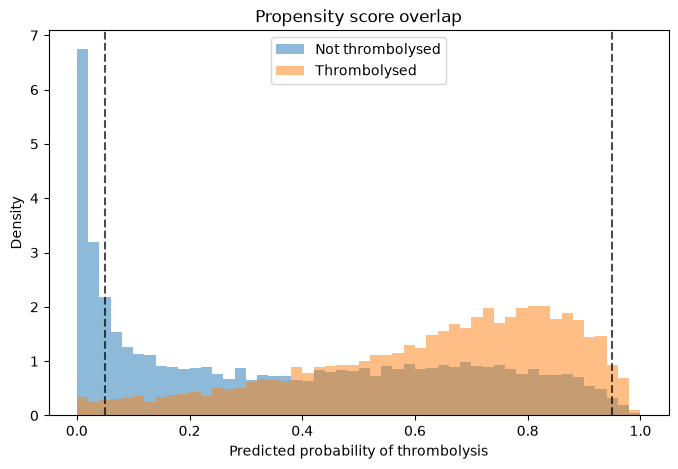

,n not thrombolysed,"proportion outside trim, not thrombolysed","mean propensity, not thrombolysed",n thrombolysed,"proportion outside trim, thrombolysed","mean propensity, thrombolysed"
group,,,,,,
All patients,13814,0.230,0.371,14004,0.039,0.630
LOC: deficit,889,0.279,0.290,530,0.042,0.520
LOC questions: deficit,6096,0.263,0.322,4974,0.037,0.597
LOC commands: deficit,2238,0.273,0.323,1900,0.042,0.611
Best gaze: deficit,1463,0.226,0.373,1507,0.056,0.627
Visual fields: deficit,3171,0.220,0.368,3090,0.044,0.614
Facial palsy: deficit,8897,0.228,0.384,9716,0.041,0.644
Motor arm left: deficit,5811,0.234,0.367,5852,0.041,0.630
Motor arm right: deficit,4632,0.218,0.382,4997,0.039,0.641


In [34]:
PROPENSITY_TRIM = (0.05, 0.95)
propensity_features = ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES

data["propensity_thrombolysis"] = cross_val_predict(
    XGBClassifier(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="logloss"),
    data[propensity_features], data["thrombolysis_given"],
    cv=StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
)[:, 1]

print(f"Propensity model AUC (out-of-fold): "
      f"{roc_auc_score(data['thrombolysis_given'], data['propensity_thrombolysis']):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for name, value in [("Not thrombolysed", 0), ("Thrombolysed", 1)]:
    ax.hist(data.loc[data["thrombolysis_given"] == value, "propensity_thrombolysis"],
            bins=50, range=(0, 1), density=True, alpha=0.5, label=name)
for limit in PROPENSITY_TRIM:
    ax.axvline(limit, color="black", linestyle="--", alpha=0.7)
ax.set_xlabel("Predicted probability of thrombolysis")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap")
ax.legend()
fig.savefig(output_path("sensitivity_propensity_overlap.png"), dpi=300, bbox_inches="tight")
plt.show()

outside_trim = ~data["propensity_thrombolysis"].between(*PROPENSITY_TRIM)
overlap_rows = []
for name, mask in [("All patients", pd.Series(True, index=data.index)),
                   *[(deficit_group(c), data[c] > 0) for c in NIHSS_COMPONENTS]]:
    row = {"group": name}
    for value, treatment in [(0, "not thrombolysed"), (1, "thrombolysed")]:
        selected = mask & (data["thrombolysis_given"] == value)
        row[f"n {treatment}"] = int(selected.sum())
        row[f"proportion outside trim, {treatment}"] = outside_trim[selected].mean()
        row[f"mean propensity, {treatment}"] = data.loc[selected, "propensity_thrombolysis"].mean()
    overlap_rows.append(row)
overlap_by_item = pd.DataFrame(overlap_rows).set_index("group")
overlap_by_item.to_csv(output_path("sensitivity_overlap_by_nihss_item.csv"))
overlap_by_item.round(3)

**Results.** The propensity model has an out-of-fold AUC of 0.74. Treatment is less predictable than in mild stroke (0.79–0.80), because severity, the dominant driver of treatment in mild stroke, varies little here.
* **Overall**, 23.0% of untreated and 3.9% of thrombolysed patients fall outside 0.05–0.95.
* **Thrombolysed patients with each deficit**: 3.1–5.6% fall outside the range.
* **Untreated patients with each deficit**: 18–28% fall outside.

Overlap is therefore good for thrombolysed patients in every deficit group.

## S2. Robustness to analytic choices

`run_thrombolysis_analysis` repeats the whole pipeline (outcome, 5-fold S-learner, counterfactual predictions) with one setting changed at a time. For each scenario it reports:
* the mean benefit (log odds and probability);
* the regression of benefit on time (slope per hour, and the time at which benefit reaches zero);
* the mean benefit in patients with each NIHSS item deficit.

| Scenario | What it tests |
|---|---|
| Base case | Reproduces the main analysis: tuned hyperparameters, no class weighting (check) |
| Original specification (default, weighted) | Default XGBoost settings with class weighting (`scale_pos_weight` = negatives / positives × `POS_WEIGHT_FACTOR`). Tests hyperparameter choice and class weighting together. |
| Default XGBoost, no class weighting | Default settings alone. Separates the effect of class weighting from the effect of tuning. |
| CV seed 1, CV seed 2 | Variability due to the random allocation of patients to folds |
| Outcome: mRS 0–2 only | Dropping the 'no worse than pre-stroke' rule |
| Outcome: mRS 0–1 or no worse | A stricter (excellent) outcome, commonly used in mild-stroke trials |
| Outcome: mRS 0–3 or no worse | A more lenient definition of good outcome |
| Total NIHSS instead of items | The model of the total-NIHSS notebook: total NIHSS replaces the 15 items. Shows what the item detail changes. |
| Without stroke team | Team captures local practice and case mix; removing it shows how much estimates rely on within-team comparisons |
| Pre-stroke mRS 0–2 only | Restricts to previously independent patients, where the 'no worse than pre-stroke' rule rarely applies |
| Arrival within 3 hours | Earlier arrivals only |
| Propensity-trimmed (0.05–0.95) | Restricts to patients with overlap (see S1) |
| Regularised XGBoost | A fixed, heavily regularised specification (depth 3, 300 trees, learning rate 0.05, min child weight 10), unweighted: a further check on model flexibility |
| Logistic regression S-learner | A parametric model: main effects plus a thrombolysis indicator and a linear time-to-thrombolysis term among treated patients. It tests model class, and gives a constant log odds ratio at a given time. |

Hyperparameters are not re-tuned for each scenario: scenarios that use the base model use the tuned settings.

In [35]:
def encode_thrombolysis(X):
    """For linear models: thrombolysis indicator, and time set to 0 when not given (so time only acts among treated)."""
    X = X.copy()
    given = X[TIME_THROMBOLYSIS] < NO_TREATMENT
    X["thrombolysis_indicator"] = given.astype(float)
    X[TIME_THROMBOLYSIS] = X[TIME_THROMBOLYSIS].where(given, 0.0)
    return X

def logistic_factory():
    """Logistic regression S-learner (main effects; numeric scaled, categorical one-hot encoded)."""
    def make_model(train_y):
        preprocess = ColumnTransformer([
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
             make_column_selector(dtype_exclude=["category", "object"])),
            ("categorical", make_pipeline(FunctionTransformer(lambda X: X.astype(str)),
                                          OneHotEncoder(handle_unknown="ignore")),
             make_column_selector(dtype_include=["category", "object"])),
        ])
        return make_pipeline(FunctionTransformer(encode_thrombolysis), preprocess,
                             LogisticRegression(max_iter=2000))
    return make_model

def run_thrombolysis_analysis(df, mrs_target=MRS_TARGET, include_no_worse=True,
                              features=None, model_factory=None, random_state=RANDOM_STATE):
    """Re-run the S-learner pipeline with alternative settings; return counterfactuals and performance.

    NIHSS items and total NIHSS are added to the counterfactual table (from the patient data) when the
    model does not use them, so that results can always be summarised by NIHSS item deficit."""
    features = features if features is not None else X_FIELDS
    model_factory = model_factory if model_factory is not None else xgb_factory(**best_params)
    outcome = good_outcome(df, mrs_target=mrs_target, include_no_worse=include_no_worse)
    scenario_folds = split_folds(df[features], outcome, random_state=random_state)
    scenario_models, scenario_performance = train_and_evaluate(scenario_folds, model_factory)
    scenario_cf = predict_thrombolysis_counterfactuals(scenario_models, scenario_folds)
    return add_patient_columns(scenario_cf, NIHSS_COMPONENTS + ["stroke_severity"]), scenario_performance

SCENARIOS = {
    "Base case": {},
    "Original specification (default, weighted)": {"model_factory": xgb_factory(POS_WEIGHT_FACTOR)},
    "Default XGBoost, no class weighting": {"model_factory": xgb_factory(pos_weight_factor=None)},
    "CV seed 1": {"random_state": 1},
    "CV seed 2": {"random_state": 2},
    "Outcome: mRS 0-2 only": {"include_no_worse": False},
    "Outcome: mRS 0-1 or no worse": {"mrs_target": 1},
    "Outcome: mRS 0-3 or no worse": {"mrs_target": 3},
    "Total NIHSS instead of items": {
        "features": [f for f in X_FIELDS if f not in NIHSS_COMPONENTS] + ["stroke_severity"]
    },
    "Without stroke team": {"features": [f for f in X_FIELDS if f != "stroke_team"]},
    "Pre-stroke mRS 0-2 only": {"population": lambda df: df[df["prior_disability"] <= 2]},
    "Arrival within 3 hours": {"population": lambda df: df[df["onset_to_arrival_time"] < 180]},
    "Propensity-trimmed (0.05-0.95)": {
        "population": lambda df: df[df["propensity_thrombolysis"].between(*PROPENSITY_TRIM)]
    },
    "Regularised XGBoost": {"model_factory": xgb_factory(
        None, max_depth=3, n_estimators=300, learning_rate=0.05, min_child_weight=10
    )},
    "Logistic regression S-learner": {"model_factory": logistic_factory()},
}

overall_rows, component_rows = [], []

for scenario, settings in SCENARIOS.items():
    settings = dict(settings)
    population = settings.pop("population", None)
    scenario_data = population(data) if population is not None else data

    scenario_cf, scenario_performance = run_thrombolysis_analysis(scenario_data, **settings)

    log_odds = summarise_effect(scenario_cf["log_odds_diff"])
    prob = summarise_effect(scenario_cf["treatment_diff_prob"])
    _, time_fit = fit_time_regression(scenario_cf)
    overall_rows.append({
        "scenario": scenario,
        "patients": len(scenario_data),
        "thrombolysed": int(log_odds["n"]),
        "mean AUC": scenario_performance["AUC"].mean(),
        "observed positive rate": scenario_performance["actual_positive_rate"].mean(),
        "mean predicted probability": scenario_performance["mean_predicted_probability"].mean(),
        "log OR mean": log_odds["mean"],
        "log OR CI lower": log_odds["95% CI lower"],
        "log OR CI upper": log_odds["95% CI upper"],
        "prob diff mean": prob["mean"],
        "prob diff CI lower": prob["95% CI lower"],
        "prob diff CI upper": prob["95% CI upper"],
        "proportion negative effect": log_odds["proportion < 0"],
        "log OR slope per hour": time_fit["slope per hour"],
        "time at zero benefit": time_fit["time at zero benefit"],
        "time at zero CI lower": time_fit["time at zero CI lower"],
        "time at zero CI upper": time_fit["time at zero CI upper"],
    })

    for c in NIHSS_COMPONENTS:
        with_deficit = scenario_cf[scenario_cf[c] > 0]
        component_rows.append({
            "scenario": scenario, "component": label(c),
            "log OR": with_deficit["log_odds_diff"].mean(),
            "prob diff": with_deficit["treatment_diff_prob"].mean(),
            "difference pp (deficit - none)": 100 * (with_deficit["treatment_diff_prob"].mean()
                                                     - scenario_cf.loc[scenario_cf[c] == 0, "treatment_diff_prob"].mean()),
            "n": len(with_deficit),
        })
    print(f"Completed: {scenario}")

sensitivity_overall = pd.DataFrame(overall_rows).set_index("scenario")
sensitivity_by_component = pd.DataFrame(component_rows)
sensitivity_overall.to_csv(output_path("sensitivity_overall.csv"))
sensitivity_by_component.to_csv(output_path("sensitivity_by_nihss_item.csv"), index=False)

Completed: Base case
Completed: Original specification (default, weighted)
Completed: Default XGBoost, no class weighting
Completed: CV seed 1
Completed: CV seed 2
Completed: Outcome: mRS 0-2 only
Completed: Outcome: mRS 0-1 or no worse
Completed: Outcome: mRS 0-3 or no worse
Completed: Total NIHSS instead of items
Completed: Without stroke team
Completed: Pre-stroke mRS 0-2 only
Completed: Arrival within 3 hours
Completed: Propensity-trimmed (0.05-0.95)
Completed: Regularised XGBoost
Completed: Logistic regression S-learner


**Results.** All 15 scenarios completed, and their results are saved (`sensitivity_overall.csv`, `sensitivity_by_nihss_item.csv`). The tables and figures below summarise them.

### Model performance and overall benefit by scenario

The first table gives each scenario's sample, out-of-fold AUC and calibration in the large. The second gives the mean benefit with 95% CI (between-patient variation only), the proportion of negative individual estimates, and the time regression. The figure compares scenarios.

In [36]:
sensitivity_overall[["patients", "thrombolysed", "mean AUC", "observed positive rate", "mean predicted probability"]].round(3)

,patients,thrombolysed,mean AUC,observed positive rate,mean predicted probability
scenario,,,,,
Base case,27818,14004,0.705,0.573,0.574
"Original specification (default, weighted)",27818,14004,0.663,0.573,0.554
"Default XGBoost, no class weighting",27818,14004,0.666,0.573,0.576
CV seed 1,27818,14004,0.705,0.573,0.574
CV seed 2,27818,14004,0.706,0.573,0.574
Outcome: mRS 0-2 only,27818,14004,0.803,0.461,0.461
Outcome: mRS 0-1 or no worse,27818,14004,0.714,0.414,0.414
Outcome: mRS 0-3 or no worse,27818,14004,0.741,0.740,0.741
Total NIHSS instead of items,27818,14004,0.695,0.573,0.573


**Results.** Out-of-fold AUC is 0.70–0.71 in the tuned scenarios with the primary outcome, and lower without stroke team (0.69), for the logistic model (0.67) and with default settings (0.66–0.67). The AUC differs with the outcome definition (0.71–0.80) because the outcome changes. Mean predicted probability matches the observed rate in every scenario except the class-weighted one (0.55 vs 0.57).

For each scenario: mean benefit (log odds ratio and probability difference, with between-patient 95% CIs), proportion of negative individual estimates, and the regression of benefit on time (slope per hour and time at which benefit reaches zero).

In [37]:
sensitivity_overall[[
    "log OR mean", "log OR CI lower", "log OR CI upper",
    "prob diff mean", "prob diff CI lower", "prob diff CI upper",
    "proportion negative effect", "log OR slope per hour",
    "time at zero benefit", "time at zero CI lower", "time at zero CI upper",
]].round(3)

,log OR mean,log OR CI lower,log OR CI upper,prob diff mean,prob diff CI lower,prob diff CI upper,proportion negative effect,log OR slope per hour,time at zero benefit,time at zero CI lower,time at zero CI upper
scenario,,,,,,,,,,,
Base case,0.435,0.432,0.439,0.094,0.094,0.095,0.006,-0.130,371.780,367.160,376.400
"Original specification (default, weighted)",0.575,0.564,0.587,0.105,0.102,0.107,0.191,-0.207,338.216,327.666,348.765
"Default XGBoost, no class weighting",0.565,0.553,0.576,0.100,0.098,0.102,0.191,-0.194,346.298,334.551,358.045
CV seed 1,0.434,0.431,0.438,0.094,0.093,0.095,0.007,-0.131,370.610,365.951,375.269
CV seed 2,0.436,0.432,0.439,0.094,0.094,0.095,0.007,-0.128,375.711,370.852,380.570
Outcome: mRS 0-2 only,0.464,0.461,0.467,0.093,0.092,0.094,0.000,-0.127,390.083,385.235,394.931
Outcome: mRS 0-1 or no worse,0.424,0.421,0.428,0.091,0.090,0.091,0.004,-0.140,353.607,349.565,357.649
Outcome: mRS 0-3 or no worse,0.426,0.423,0.430,0.062,0.061,0.062,0.005,-0.128,371.144,365.794,376.495
Total NIHSS instead of items,0.476,0.473,0.479,0.104,0.103,0.105,0.004,-0.129,392.053,386.513,397.594


**Results.** Mean benefit is 0.42–0.46 log OR (9.1–9.9 points) in the tuned and restricted scenarios, 0.48 with total NIHSS instead of items, 0.44 with logistic regression and 0.42 with the fixed regularised model. Default settings give 0.57–0.58 with 19% negative estimates. The time slope is −0.12 to −0.14 per hour in all but the default scenarios.

Plot comparing scenarios on three measures: mean benefit (log odds ratio), mean benefit (probability difference) and time at which benefit reaches zero. The dotted line marks the base case.

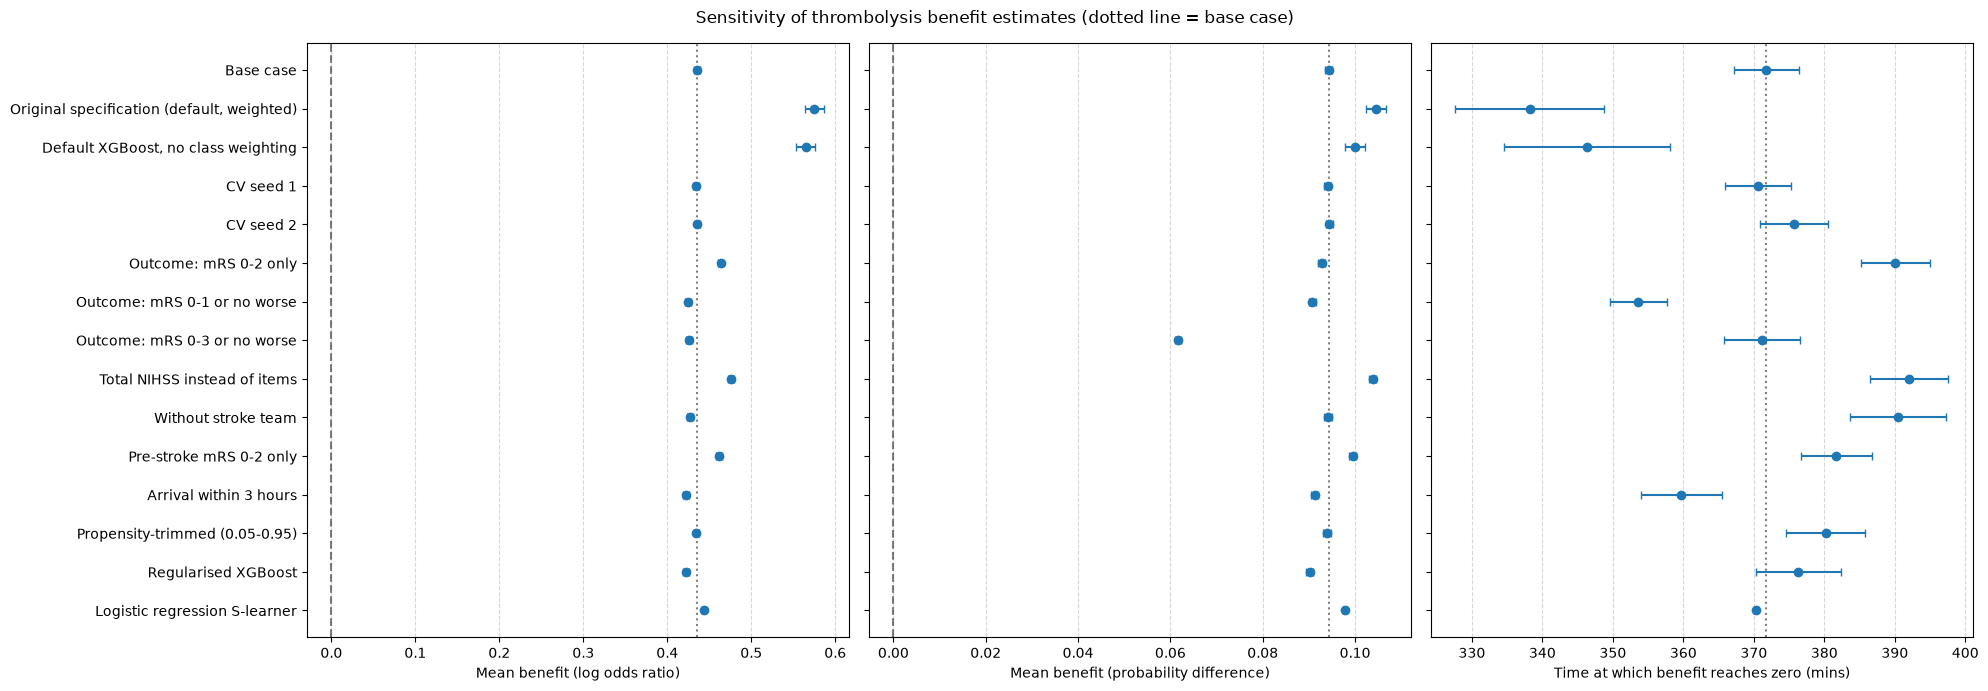

In [38]:
scenarios = list(SCENARIOS)
y_pos = np.arange(len(scenarios))[::-1]
res = sensitivity_overall.reindex(scenarios)

panels = [
    ("log OR", "Mean benefit (log odds ratio)"),
    ("prob diff", "Mean benefit (probability difference)"),
    ("time at zero", "Time at which benefit reaches zero (mins)"),
]
fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=True)
for ax, (prefix, xlabel) in zip(axes, panels):
    mean_col = f"{prefix} mean" if prefix != "time at zero" else "time at zero benefit"
    ax.errorbar(
        res[mean_col], y_pos,
        xerr=[res[mean_col] - res[f"{prefix} CI lower"], res[f"{prefix} CI upper"] - res[mean_col]],
        fmt="o", capsize=3,
    )
    ax.axvline(res.loc["Base case", mean_col], color="grey", linestyle=":")
    if prefix != "time at zero":
        ax.axvline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(scenarios)
fig.suptitle("Sensitivity of thrombolysis benefit estimates (dotted line = base case)")
fig.tight_layout()
fig.savefig(output_path("sensitivity_overall.png"), dpi=300, bbox_inches="tight")
plt.show()

**Results.** Almost all scenarios lie close to the base case on all three measures. The outliers are the two default-settings scenarios (larger log OR, earlier zero point) and the mRS 0–3 outcome (smaller absolute benefit).

### Benefit by NIHSS item deficit across scenarios

Mean benefit in thrombolysed patients with each deficit, for each scenario: log odds ratio (first heatmap) and the difference in percentage points from patients without the deficit (second heatmap). This checks whether the pattern of benefit by item is robust. Items (columns) are ordered by the base-case benefit.

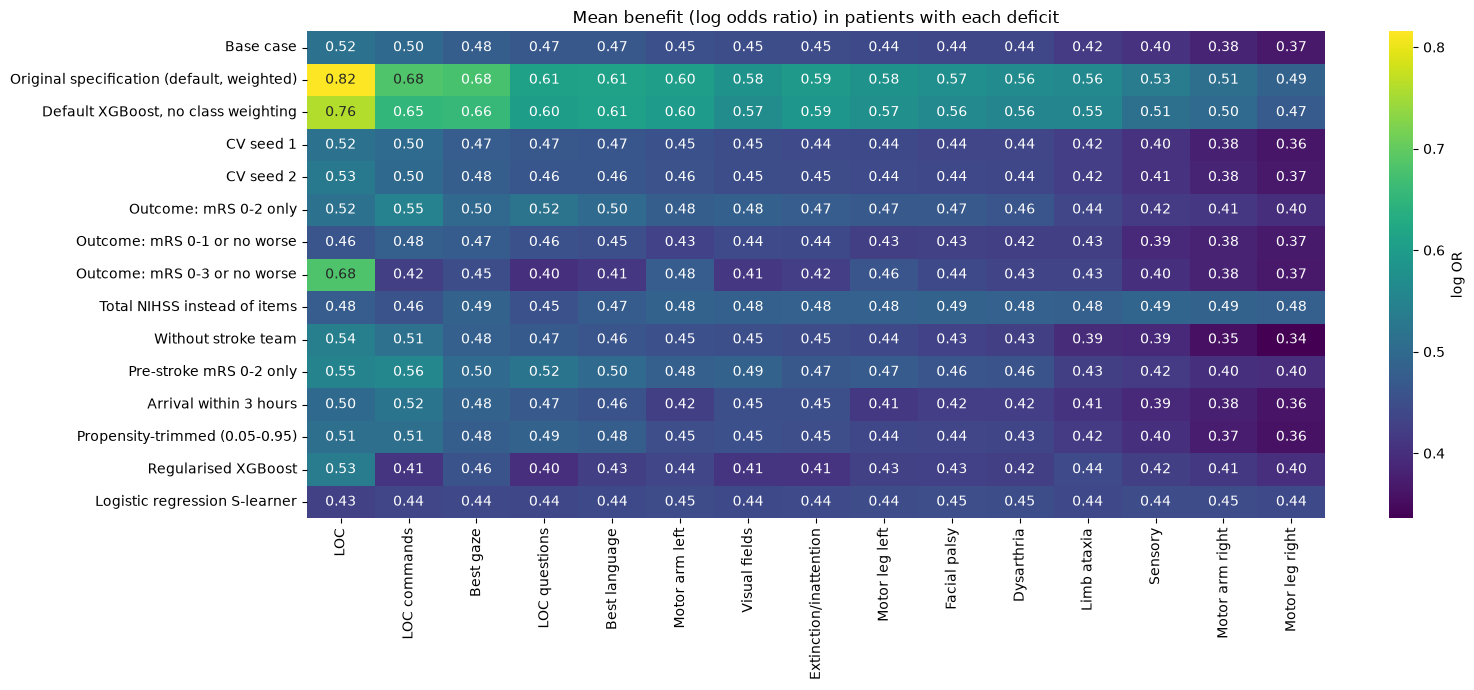

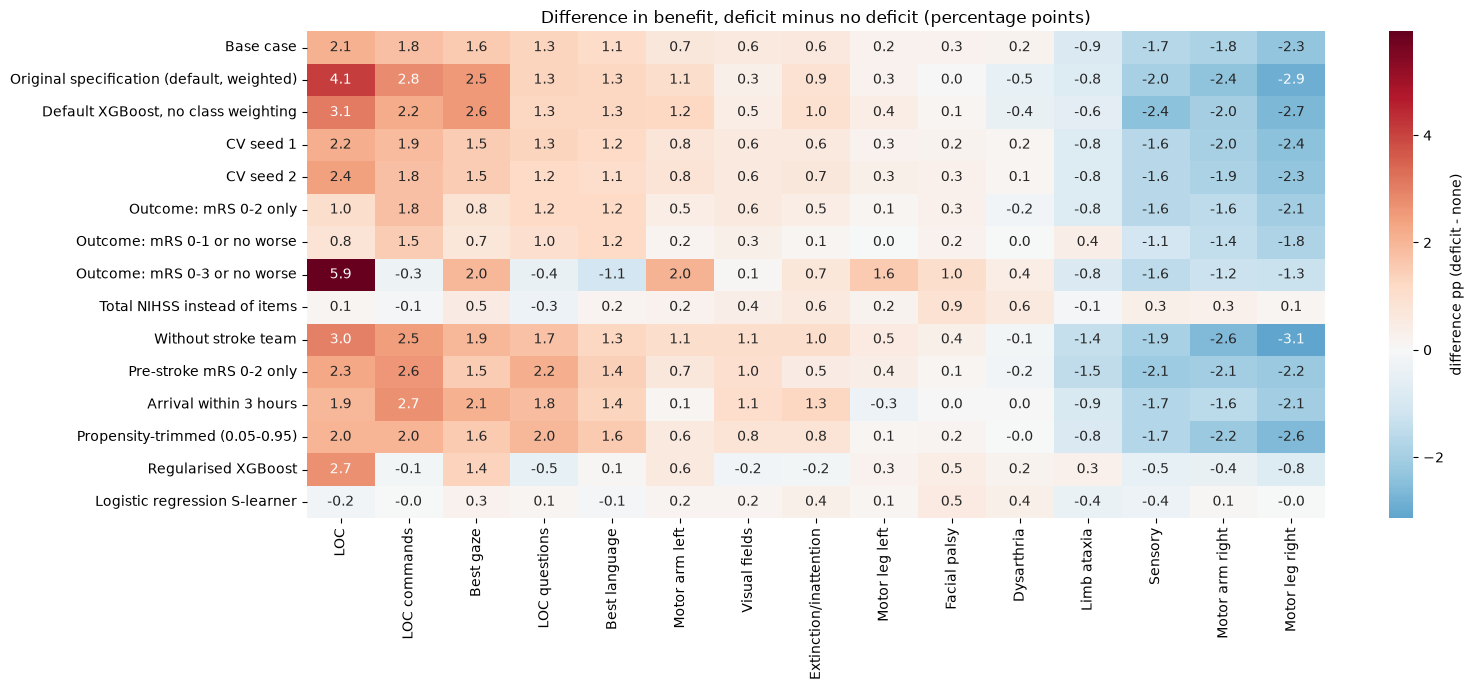

In [39]:
item_order = (sensitivity_by_component[sensitivity_by_component["scenario"] == "Base case"]
              .sort_values("log OR", ascending=False)["component"].tolist())
for value, title, fmt, centre in [
    ("log OR", "Mean benefit (log odds ratio) in patients with each deficit", ".2f", None),
    ("difference pp (deficit - none)", "Difference in benefit, deficit minus no deficit (percentage points)", ".1f", 0),
]:
    table = (sensitivity_by_component.pivot(index="scenario", columns="component", values=value)
             .reindex(index=scenarios, columns=item_order))
    fig, ax = plt.subplots(figsize=(16, 7))
    sns.heatmap(table, annot=True, fmt=fmt, cmap="RdBu_r" if centre is not None else "viridis",
                center=centre, ax=ax, cbar_kws={"label": value})
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(output_path(f"sensitivity_by_nihss_item_{'log_or' if centre is None else 'difference'}.png"),
                dpi=300, bbox_inches="tight")
    plt.show()

**Results.**
* **Average benefit.** It is very stable.
  * **Tuned and restricted scenarios**: mean log OR 0.42–0.46 (9.1 to 9.9 points) across fold seeds, without stroke team, previously independent patients, arrival within 3 hours and propensity trimming.
  * **Regularised XGBoost**: 0.42 (9.0 points).
  * **Logistic regression S-learner**: 0.44 (9.8 points).
  * **Total NIHSS instead of items**: 0.48 (10.4 points).
* **Outcome definitions.** The log OR is 0.42–0.46. The absolute benefit is 9.3 points (mRS 0–2 only), 9.1 (mRS 0–1 or no worse) and 6.2 (mRS 0–3 or no worse).
* **Time gradient.** It is −0.12 to −0.14 per hour in all tuned scenarios. Benefit reaches zero at 354–392 minutes, an extrapolation.
* **Default settings**, with or without class weighting, again give larger, noisier estimates: 0.57–0.58, with 19% of individual estimates negative and AUC 0.66–0.67.
* **By deficit** (heatmaps). Across the tuned and restricted XGBoost scenarios, the difference from patients without the deficit is consistently:
  * **negative** for right leg weakness (−1.3 to −3.1 points), right arm weakness (−1.2 to −2.6) and sensory deficits (−1.1 to −2.1);
  * **mostly negative** for limb ataxia (−1.5 to +0.4);
  * **positive** for LOC (+0.8 to +5.9), gaze (+0.7 to +2.1), LOC commands (−0.3 to +2.7), LOC questions (−0.4 to +2.2) and language (−1.1 to +1.6);
  * **within about ±1 point** for the other items.

  The regularised XGBoost shows a weaker version of the same pattern, apart from LOC (+2.7). The total-NIHSS and logistic models show differences within ±1 point, as expected.

## S3. Unmeasured confounding: E-values

The E-value (VanderWeele and Ding, 2017) is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with *both* thrombolysis and outcome, beyond the measured covariates, to fully explain away the estimate. A second E-value is given for the confidence limit closest to the null (1 if the CI includes the null).

* **Risk-ratio conversion.** Good outcome is common here (about 75%), so odds ratios are converted to approximate risk ratios with RR ≈ √OR. Even this conversion can overstate the RR when the outcome is very common, so these E-values are, if anything, generous.
* **Odds ratio used.** The 'odds ratio' is exp(mean individual log odds ratio). This approximates, but is not the same as, a marginal odds ratio.
* **Confidence limits.** The CIs here reflect between-patient variation only (Section 2.5), so the confidence-limit E-values are optimistic. The bootstrap CIs of Section 5.1, which include model uncertainty, are the better guide; E-values are recalculated from them below.
* **Groups.** E-values are given overall, by 60-minute bins of onset-to-thrombolysis time, and for patients with each NIHSS item deficit.
* **Likely direction of bias.** The most plausible unmeasured confounder in moderate stroke is whether the deficit is disabling. The NIHSS items capture *which* deficits are present but still not fully whether they are disabling for the individual. Clinicians tend to thrombolyse disabling deficits, which also carry a worse prognosis, so this would bias *against* benefit. Unrecorded factors such as frailty, or stroke mimics among untreated patients, could bias in either direction.

In [40]:
def e_value_from_odds_ratio(odds_ratio):
    """E-value for an odds ratio, using RR ~ sqrt(OR) for a common outcome."""
    rr = np.sqrt(np.asarray(odds_ratio, dtype=float))
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

def e_value_table(groups):
    """E-values from mean log odds ratios for each group of patients (a dict of name -> DataFrame)."""
    table = pd.DataFrame({name: summarise_effect(g["log_odds_diff"]) for name, g in groups.items()}).T
    out = np.exp(table[["mean", "95% CI lower", "95% CI upper"]].astype(float))
    out.columns = ["OR", "OR 95% CI lower", "OR 95% CI upper"]
    out["E-value (estimate)"] = e_value_from_odds_ratio(out["OR"])
    ci_includes_null = (out["OR 95% CI lower"] <= 1) & (out["OR 95% CI upper"] >= 1)
    nearest = np.where(out["OR"] >= 1, out["OR 95% CI lower"], out["OR 95% CI upper"])
    out["E-value (CI limit)"] = np.where(ci_includes_null, 1.0, e_value_from_odds_ratio(nearest))
    out["n"] = table["n"].astype(int)
    return out

time_bins = pd.cut(cf[TIME_THROMBOLYSIS], bins=range(0, 361, 60), right=False,
                   labels=[f"{t}-{t + 59}" for t in range(0, 360, 60)])

e_values = pd.concat({
    "All thrombolysed": e_value_table({"all": cf}),
    "By time to thrombolysis (mins)": e_value_table({str(k): g for k, g in cf.groupby(time_bins, observed=True)}),
    "By NIHSS item deficit": e_value_table({deficit_group(c): cf[cf[c] > 0] for c in NIHSS_COMPONENTS}),
})
e_values.to_csv(output_path("sensitivity_e_values.csv"))
e_values.round(2)

OR  \
All thrombolysed               all                              1.55   
By time to thrombolysis (mins) 0-59                             1.92   
                               60-119                           1.79   
                               120-179                          1.63   
                               180-239                          1.43   
                               240-299                          1.28   
                               300-359                          1.08   
By NIHSS item deficit          LOC: deficit                     1.68   
                               LOC questions: deficit           1.59   
                               LOC commands: deficit            1.65   
                               Best gaze: deficit               1.61   
                               Visual fields: deficit           1.56   
                               Facial palsy: deficit            1.55   
                               Motor arm left: deficit          1.57   
                               Motor arm right: deficit         1.47   
                               Motor leg left: deficit          1.55   
                               Motor leg right: deficit         1.44   
                               Limb ataxia: deficit             1.52   
                               Sensory: deficit                 1.50   
                               Best language: deficit           1.59   
                               Dysarthria: deficit              1.55   
                               Extinction/inattention: deficit  1.56   

                                                                OR 95% CI lower  \
All thrombolysed               all                                         1.54   
By time to thrombolysis (mins) 0-59                                        1.83   
                               60-119                                      1.78   
                               120-179                                     1.62   
                               180-239                                     1.43   
                               240-299                                     1.27   
                               300-359                                     1.07   
By NIHSS item deficit          LOC: deficit                                1.64   
                               LOC questions: deficit                      1.59   
                               LOC commands: deficit                       1.63   
                               Best gaze: deficit                          1.60   
                               Visual fields: deficit                      1.55   
                               Facial palsy: deficit                       1.54   
                               Motor arm left: deficit                     1.56   
                               Motor arm right: deficit                    1.46   
                               Motor leg left: deficit                     1.55   
                               Motor leg right: deficit                    1.44   
                               Limb ataxia: deficit                        1.51   
                               Sensory: deficit                            1.49   
                               Best language: deficit                      1.58   
                               Dysarthria: deficit                         1.54   
                               Extinction/inattention: deficit             1.55   

                                                                OR 95% CI upper  \
All thrombolysed               all                                         1.55   
By time to thrombolysis (mins) 0-59                                        2.02   
                               60-119                                      1.81   
                               120-179                                     1.64   
                               180-239                                     1.44   
 

**Results.**
* **Overall.** The E-value is 1.79. An unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.8 each, beyond the measured covariates, could explain away the average effect.
* **By time to thrombolysis.** E-values fall with delay: 2.01 at 1–2 hours, 1.87 at 2–3 hours, 1.68 at 3–4 hours, 1.51 at 4–5 hours and 1.24 at 5–6 hours. The 0–59 minute group (2.12) contains only 66 patients.
* **By deficit.** E-values are 1.69–1.91 in every deficit group: highest with LOC (1.91), lowest with right leg and right arm weakness (1.69–1.72).

The confidence-limit E-values in this table use CIs that reflect between-patient variation only; they are recalculated from the bootstrap CIs below. Only treatment after 5 hours could be explained away by weak confounding.

### E-values from the bootstrap confidence intervals

The confidence-limit E-values above use CIs that reflect variation between patients' predicted effects only, so they are optimistic. Here they are recalculated from the bootstrap 95% CIs of Section 5.1, which include uncertainty from refitting the model, overall and for patients with each NIHSS item deficit (the bootstrap was not run by time to thrombolysis).

* The E-value for the estimate is unchanged: it depends only on the point estimate.
* The confidence-limit E-value uses the bootstrap limit closest to the null, converted with RR ≈ √OR as above. It is 1 if the bootstrap CI includes OR = 1.
* The between-patient confidence-limit E-values from the table above are shown alongside for comparison.

If the bootstrap cell has not been run in the current session, its saved output (`bootstrap_summary.csv`) is used. The table is saved as `sensitivity_e_values_bootstrap.csv`, and the results are also printed as LaTeX rows.

In [41]:
# E-values recalculated from the bootstrap 95% CIs of Section 5.1, which include model uncertainty.
# The E-value for the estimate is unchanged; the confidence-limit E-value uses the bootstrap limit closest
# to the null, and is 1 if the bootstrap CI includes the null (OR = 1).
try:
    boot_for_e = bootstrap_summary.copy()
except NameError:  # bootstrap cell not run in this session: use its saved output
    boot_for_e = pd.read_csv(output_path("bootstrap_summary.csv"), index_col="group")
boot_for_e = boot_for_e.reindex(["All"] + DEFICIT_GROUPS)

e_values_bootstrap = pd.DataFrame({
    "n": boot_for_e["n"].astype(int),
    "OR": boot_for_e["odds_ratio"],
    "OR 95% CI lower": boot_for_e["odds_ratio_ci_lower"],
    "OR 95% CI upper": boot_for_e["odds_ratio_ci_upper"],
})
e_values_bootstrap["RR (approx., sqrt OR)"] = np.sqrt(e_values_bootstrap["OR"])
e_values_bootstrap["E-value (estimate)"] = e_value_from_odds_ratio(e_values_bootstrap["OR"])

ci_includes_null = (e_values_bootstrap["OR 95% CI lower"] <= 1) & (e_values_bootstrap["OR 95% CI upper"] >= 1)
nearest_limit = np.where(e_values_bootstrap["OR"] >= 1,
                         e_values_bootstrap["OR 95% CI lower"], e_values_bootstrap["OR 95% CI upper"])
e_values_bootstrap["E-value (bootstrap CI limit)"] = np.where(
    ci_includes_null, 1.0, e_value_from_odds_ratio(nearest_limit))

# For comparison: the confidence-limit E-value from the between-patient CI (S3 table above).
between_patient = {"All": e_values.loc[("All thrombolysed", "all"), "E-value (CI limit)"]}
between_patient.update(e_values.loc["By NIHSS item deficit", "E-value (CI limit)"].to_dict())
e_values_bootstrap["E-value (between-patient CI limit)"] = pd.Series(between_patient)

e_values_bootstrap.to_csv(output_path("sensitivity_e_values_bootstrap.csv"))
display(e_values_bootstrap.round(2))

print("% ---- E-values with bootstrap CIs: group & n & OR (95% CI) & E-value (estimate) & E-value (CI limit) ----")
for group, r in e_values_bootstrap.iterrows():
    print(f"{group} & {int(r['n']):,} & {r['OR']:.2f} ({r['OR 95% CI lower']:.2f}--{r['OR 95% CI upper']:.2f}) & "
          f"{r['E-value (estimate)']:.2f} & {r['E-value (bootstrap CI limit)']:.2f} \\\\")

,n,OR,OR 95% CI lower,OR 95% CI upper,"RR (approx., sqrt OR)",E-value (estimate),E-value (bootstrap CI limit),E-value (between-patient CI limit)
group,,,,,,,,
All,14004,1.55,1.46,1.63,1.24,1.79,1.71,1.79
LOC: deficit,530,1.68,1.52,1.84,1.29,1.91,1.77,1.88
LOC questions: deficit,4974,1.59,1.47,1.73,1.26,1.84,1.72,1.83
LOC commands: deficit,1900,1.65,1.49,1.82,1.28,1.89,1.74,1.87
Best gaze: deficit,1507,1.61,1.49,1.74,1.27,1.86,1.74,1.84
Visual fields: deficit,3090,1.56,1.47,1.67,1.25,1.81,1.72,1.80
Facial palsy: deficit,9716,1.55,1.46,1.64,1.25,1.80,1.71,1.79
Motor arm left: deficit,5852,1.57,1.49,1.66,1.25,1.82,1.74,1.81
Motor arm right: deficit,4997,1.47,1.35,1.59,1.21,1.72,1.60,1.71


% ---- E-values with bootstrap CIs: group & n & OR (95% CI) & E-value (estimate) & E-value (CI limit) ----
All & 14,004 & 1.55 (1.46--1.63) & 1.79 & 1.71 \\
LOC: deficit & 530 & 1.68 (1.52--1.84) & 1.91 & 1.77 \\
LOC questions: deficit & 4,974 & 1.59 (1.47--1.73) & 1.84 & 1.72 \\
LOC commands: deficit & 1,900 & 1.65 (1.49--1.82) & 1.89 & 1.74 \\
Best gaze: deficit & 1,507 & 1.61 (1.49--1.74) & 1.86 & 1.74 \\
Visual fields: deficit & 3,090 & 1.56 (1.47--1.67) & 1.81 & 1.72 \\
Facial palsy: deficit & 9,716 & 1.55 (1.46--1.64) & 1.80 & 1.71 \\
Motor arm left: deficit & 5,852 & 1.57 (1.49--1.66) & 1.82 & 1.74 \\
Motor arm right: deficit & 4,997 & 1.47 (1.35--1.59) & 1.72 & 1.60 \\
Motor leg left: deficit & 5,584 & 1.55 (1.47--1.64) & 1.80 & 1.72 \\
Motor leg right: deficit & 4,721 & 1.44 (1.34--1.56) & 1.69 & 1.58 \\
Limb ataxia: deficit & 3,825 & 1.52 (1.43--1.62) & 1.77 & 1.68 \\
Sensory: deficit & 5,919 & 1.50 (1.40--1.60) & 1.75 & 1.65 \\
Best language: deficit & 6,109 & 1.59 (1.47--1.

**Results.** With bootstrap CIs the confidence-limit E-values are 1.71 overall, and 1.58–1.77 across deficit groups.
* An unmeasured confounder would need associations of about 1.6–1.8 (risk ratio) with both thrombolysis and outcome to move any of these CIs to include no effect.
* These are the most robust estimates of the three severity ranges (NIHSS 1–5: 1.40 overall).

## S4. Unmeasured confounding: sensemakr

Cinelli and Hazlett's omitted variable bias framework describes the strength of an unmeasured confounder by its partial R², the share of the remaining (residual) variance of treatment and of outcome that it explains. It gives:

* **Robustness value RV_q** (q = 1): the minimum partial R² that a confounder would need with *both* thrombolysis and good outcome to reduce the estimate to zero.
* **RV_q,alpha**: the same, to make the 95% confidence interval include zero.
* **Partial R² of treatment with outcome**: an extreme-scenario bound. A confounder that explained all the remaining variation in outcome would still need at least this partial R² with thrombolysis to remove the effect.
* **Benchmark bounds**: the adjusted estimate (with 95% CI) if a confounder were 1, 2 or 3 times as strongly associated with thrombolysis and with outcome as an observed covariate.

Unlike E-values, robustness values are on the partial R² scale, so they are not compressed by the high rate of good outcome in moderate stroke.

The framework applies to linear regression, so it cannot be applied to the XGBoost S-learner itself. A linear probability model is fitted to all patients, and separately to the patients with each NIHSS item deficit: good outcome ~ thrombolysed + the S-learner's adjustment features (including the 15 NIHSS items) + stroke team + ethnicity (as indicator variables). Patients with a missing adjustment feature are excluded from this model, and groups too small for the number of covariates are skipped. The linear model is a simpler stand-in for the S-learner: it has no non-linear effects or interactions, its predictions are not constrained to lie between 0 and 1, and it does not use time to thrombolysis.

Benchmarks are pre-stroke mRS, age and the two NIHSS items most strongly associated with thrombolysis (largest |t| in a linear model of thrombolysis on the covariates in the whole cohort).

The first cell implements the formulas of the sensemakr package directly, because the Python package (PySensemakr 0.0.8) is not compatible with pandas 3; the implementation reproduces the package's published Darfur example (estimate, robustness values and benchmark bounds). The second cell fits the models and tabulates the results, and the third draws the sensitivity contours.

Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

In [42]:
from scipy import stats as _stats
import statsmodels.api as _sm

def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3). Returns a one-row DataFrame of sensitivity statistics and a
    DataFrame of bounds: the adjusted estimate if an unobserved confounder were kd times as
    strongly associated with treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = _sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)

def adjusted_estimate_grid(est, se, dof, r2dz_x, r2yz_dx):
    """Adjusted estimate (bias towards zero) over a grid of confounder partial R2 values."""
    bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
    return np.sign(est) * (abs(est) - bias)

# Markers and names for benchmark covariates; NIHSS item benchmarks are added in the next cell
BENCHMARK_MARKERS = {"prior_disability": "o", "age": "^"}
BENCHMARK_NAMES = {"prior_disability": "pre-stroke mRS", "age": "age"}

def plot_sensemakr_contours(sens_stats, sens_bounds, labels, filename, scale=100, unit="percentage points"):
    """One contour plot per patient group: adjusted estimate against the partial R2 of a
    hypothetical confounder with treatment (x) and with outcome (y). The red dashed line is
    where the estimate would fall to zero; markers show confounders 1x, 2x and 3x as strong
    as each benchmark covariate."""
    strategies = list(sens_stats.index)
    ncols = 4
    nrows = int(np.ceil(len(strategies) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
    for ax, strategy in zip(axes.flat, strategies):
        st = sens_stats.loc[strategy]
        b = sens_bounds[(sens_bounds["treatment_group"] == strategy)].dropna(subset=["r2dz_x"])
        lim = max(0.05, 1.2 * max(b["r2dz_x"].max(), b["r2yz_dx"].max(), st["rv_q"]))
        lim = min(lim, 0.95)
        grid = np.linspace(0, lim, 201)
        gx, gy = np.meshgrid(grid, grid)
        z = scale * adjusted_estimate_grid(st["estimate"], st["se"], st["dof"], gx, gy)
        cs = ax.contour(gx, gy, z, levels=8, colors="grey", linewidths=0.7)
        ax.clabel(cs, fontsize=7, fmt="%.0f")
        ax.contour(gx, gy, z, levels=[0], colors="red", linestyles="--", linewidths=1.3)
        for _, r in b.iterrows():
            ax.plot(r["r2dz_x"], r["r2yz_dx"], BENCHMARK_MARKERS.get(r["benchmark"], "x"),
                    color="black", ms=4 + r["kd"])
        ax.plot(0, 0, "*", color="tab:blue", ms=9)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(labels.get(strategy, strategy).replace("\n", " "), fontsize=10)
        ax.set_xlabel("Partial R² of confounder with treatment", fontsize=8)
        ax.set_ylabel("Partial R² of confounder with outcome", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(strategies):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], color="red", linestyle="--", label="Adjusted estimate = 0"),
               plt.Line2D([], [], marker="*", color="tab:blue", linestyle="", label="Unadjusted estimate")]
    used = sorted(set(sens_bounds["benchmark"]), key=list(BENCHMARK_MARKERS).index)
    handles += [plt.Line2D([], [], marker=BENCHMARK_MARKERS.get(b, "x"), color="black", linestyle="",
                           label=f"1x, 2x, 3x {BENCHMARK_NAMES.get(b, b)}") for b in used]
    fig.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.suptitle(f"Sensitivity contours: adjusted effect ({unit})", fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

def format_sensemakr_tables(sens_stats, sens_bounds, labels, scale=100, decimals=1):
    """Publication tables: robustness statistics, and adjusted estimates for each benchmark."""
    fmt = lambda x: f"{scale * x:.{decimals}f}"
    summary = pd.DataFrame({
        "n": sens_stats["n"].astype(int).to_numpy(),
        "estimate (95% CI)": [f"{fmt(r.estimate)} ({fmt(r.estimate - r.t_crit * r.se)}, {fmt(r.estimate + r.t_crit * r.se)})"
                              for r in sens_stats.itertuples()],
        "partial R2 of treatment (%)": (100 * sens_stats["r2yd_x"]).round(2).to_numpy(),
        "RV_q (%)": (100 * sens_stats["rv_q"]).round(1).to_numpy(),
        "RV_q,alpha (%)": (100 * sens_stats["rv_qa"]).round(1).to_numpy(),
    }, index=[labels.get(s, s).replace("\n", " ") for s in sens_stats.index])
    b = sens_bounds.copy()
    b["adjusted (95% CI)"] = [
        "" if pd.isna(r.adjusted_estimate) else
        f"{fmt(r.adjusted_estimate)} ({fmt(r.adjusted_ci_lower)}, {fmt(r.adjusted_ci_upper)})"
        for r in b.itertuples()]
    b["bound"] = b["kd"].astype(str) + "x " + b["benchmark"].map(lambda x: BENCHMARK_NAMES.get(x, x))
    bounds_table = b.pivot(index="treatment_group", columns="bound", values="adjusted (95% CI)")
    bounds_table = bounds_table.reindex(index=list(sens_stats.index),
                                        columns=list(dict.fromkeys(b["bound"])))
    bounds_table.index = [labels.get(s, s).replace("\n", " ") for s in bounds_table.index]
    return summary, bounds_table

**Results.** Sensitivity-analysis functions defined; the cell produces no output.

Fit the linear probability models (whole cohort, and patients with each NIHSS item deficit), choose the two NIHSS benchmark items most strongly associated with thrombolysis, and tabulate the robustness values and the benchmark-adjusted estimates.

In [43]:
# Linear probability model of thrombolysed vs untreated patients, in the whole cohort and in patients with each
# NIHSS item deficit: good outcome ~ thrombolysed + adjustment features + stroke team + ethnicity (indicator variables).
SENS_GROUPS = ["All"] + DEFICIT_GROUPS
SENS_LABELS = {g: g for g in SENS_GROUPS}
MIN_RESIDUAL_DOF = 100  # skip groups with too few patients for the number of covariates

sens_covariates = pd.get_dummies(data[ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES], columns=CATEGORICAL_FEATURES,
                                 drop_first=True, dtype=float)
sens_covariates["treated"] = data["thrombolysis_given"].astype(float)
sens_covariates["y"] = good_outcome(data)

# Benchmarks: pre-stroke mRS, age, and the two NIHSS items most strongly associated with thrombolysis
complete = sens_covariates.dropna()
complete_X = complete.drop(columns=["treated", "y"])
treatment_fit = sm.OLS(complete["treated"], sm.add_constant(complete_X.loc[:, complete_X.std() > 0])).fit()
top_items = treatment_fit.tvalues[NIHSS_COMPONENTS].abs().nlargest(2).index.tolist()
SENS_BENCHMARKS = ["prior_disability", "age", *top_items]
BENCHMARK_MARKERS.update(dict(zip(top_items, ["s", "D"])))
BENCHMARK_NAMES.update({c: label(c) for c in top_items})
print("Benchmarks:", [BENCHMARK_NAMES[b] for b in SENS_BENCHMARKS])

group_masks = {"All": np.ones(len(data), dtype=bool)}
group_masks.update({deficit_group(c): (data[c] > 0).to_numpy() for c in NIHSS_COMPONENTS})

sens_rows, sens_bound_rows = [], []
for group in SENS_GROUPS:
    df = sens_covariates[group_masks[group]].dropna()
    X = df.drop(columns="y")
    X = X.loc[:, X.std() > 0]  # drop columns that are constant in this subset
    if len(df) - X.shape[1] - 1 < MIN_RESIDUAL_DOF or "treated" not in X:
        print(f"Skipped {group}: {len(df)} patients for {X.shape[1]} covariates")
        continue
    lpm = sm.OLS(df["y"], sm.add_constant(X)).fit()
    stats_row, bounds = sensemakr_analysis(lpm, "treated", [b for b in SENS_BENCHMARKS if b in X.columns])
    sens_rows.append(stats_row.assign(treatment_group=group, n=len(df)))
    sens_bound_rows.append(bounds.assign(treatment_group=group))

sensemakr_stats = pd.concat(sens_rows).set_index("treatment_group")
sensemakr_bounds = pd.concat(sens_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(output_path("sensemakr.csv"))
sensemakr_bounds.to_csv(output_path("sensemakr_bounds.csv"), index=False)

sensemakr_summary, sensemakr_bounds_table = format_sensemakr_tables(sensemakr_stats, sensemakr_bounds, SENS_LABELS)
display(sensemakr_summary)
display(sensemakr_bounds_table)

Benchmarks: ['pre-stroke mRS', 'age', 'Best language', 'Facial palsy']


,n,estimate (95% CI),partial R2 of treatment (%),RV_q (%),"RV_q,alpha (%)"
All,27818,"9.8 (8.5, 11.0)",0.82,8.7,7.6
LOC: deficit,1419,"15.9 (10.0, 21.9)",2.11,13.6,8.8
LOC questions: deficit,11070,"11.1 (9.1, 13.2)",1.02,9.6,7.9
LOC commands: deficit,4138,"13.0 (9.6, 16.5)",1.37,11.1,8.3
Best gaze: deficit,2970,"13.6 (9.6, 17.6)",1.55,11.8,8.5
Visual fields: deficit,6261,"11.9 (9.2, 14.5)",1.22,10.5,8.2
Facial palsy: deficit,18613,"9.7 (8.2, 11.3)",0.81,8.6,7.3
Motor arm left: deficit,11663,"11.1 (9.1, 13.0)",1.05,9.8,8.1
Motor arm right: deficit,9629,"7.1 (5.0, 9.3)",0.44,6.4,4.5
Motor leg left: deficit,11608,"10.4 (8.5, 12.4)",0.93,9.2,7.5


bound,1x pre-stroke mRS,2x pre-stroke mRS,3x pre-stroke mRS,1x age,2x age,3x age,1x Best language,2x Best language,3x Best language,1x Facial palsy,2x Facial palsy,3x Facial palsy
All,"8.1 (6.8, 9.4)","6.3 (5.0, 7.6)","4.4 (3.1, 5.8)","9.2 (8.0, 10.5)","8.7 (7.5, 9.9)","8.2 (7.0, 9.4)","9.7 (8.5, 11.0)","9.7 (8.4, 10.9)","9.6 (8.4, 10.9)","9.6 (8.3, 10.8)","9.4 (8.1, 10.7)","9.2 (8.0, 10.5)"
LOC: deficit,"12.8 (6.8, 18.8)","9.6 (3.5, 15.7)","6.2 (0.1, 12.3)","15.5 (9.7, 21.4)","15.1 (9.4, 20.9)","14.7 (9.1, 20.4)","15.7 (9.7, 21.6)","15.4 (9.4, 21.4)","15.1 (9.1, 21.1)","15.8 (9.9, 21.8)","15.7 (9.7, 21.7)","15.6 (9.6, 21.6)"
LOC questions: deficit,"9.2 (7.1, 11.3)","7.1 (5.0, 9.3)","5.0 (2.8, 7.2)","10.7 (8.7, 12.7)","10.3 (8.3, 12.3)","9.8 (7.8, 11.8)","11.1 (9.0, 13.2)","11.1 (9.0, 13.1)","11.0 (8.9, 13.1)","10.9 (8.8, 13.0)","10.7 (8.6, 12.7)","10.5 (8.4, 12.5)"
LOC commands: deficit,"10.7 (7.2, 14.2)","8.1 (4.5, 11.8)","5.4 (1.7, 9.1)","12.7 (9.3, 16.1)","12.3 (9.0, 15.7)","12.0 (8.6, 15.3)","12.9 (9.4, 16.3)","12.7 (9.2, 16.2)","12.5 (9.0, 16.0)","12.9 (9.5, 16.3)","12.8 (9.4, 16.2)","12.7 (9.3, 16.1)"
Best gaze: deficit,"11.8 (7.8, 15.9)","10.0 (6.0, 14.1)","8.2 (4.0, 12.3)","13.4 (9.5, 17.4)","13.2 (9.4, 17.1)","13.1 (9.2, 16.9)","13.5 (9.5, 17.5)","13.3 (9.3, 17.3)","13.2 (9.2, 17.2)","13.4 (9.3, 17.4)","13.1 (9.1, 17.1)","12.8 (8.8, 16.9)"
Visual fields: deficit,"10.1 (7.4, 12.8)","8.2 (5.4, 11.0)","6.3 (3.4, 9.1)","11.2 (8.5, 13.8)","10.5 (7.9, 13.1)","9.8 (7.2, 12.3)","11.9 (9.2, 14.6)","11.9 (9.2, 14.6)","11.9 (9.2, 14.6)","11.7 (9.0, 14.4)","11.5 (8.8, 14.2)","11.3 (8.6, 14.0)"
Facial palsy: deficit,"8.2 (6.6, 9.8)","6.6 (5.0, 8.2)","4.9 (3.2, 6.5)","9.2 (7.7, 10.7)","8.6 (7.1, 10.2)","8.1 (6.6, 9.6)","9.7 (8.1, 11.3)","9.7 (8.1, 11.2)","9.7 (8.1, 11.2)","9.6 (8.1, 11.2)","9.5 (8.0, 11.1)","9.4 (7.9, 11.0)"
Motor arm left: deficit,"9.3 (7.3, 11.3)","7.4 (5.3, 9.4)","5.4 (3.3, 7.5)","10.4 (8.5, 12.4)","9.8 (7.9, 11.7)","9.2 (7.3, 11.1)","11.0 (9.1, 13.0)","11.0 (9.1, 13.0)","11.0 (9.1, 13.0)","10.9 (8.9, 12.8)","10.6 (8.7, 12.6)","10.4 (8.5, 12.4)"
Motor arm right: deficit,"5.9 (3.7, 8.1)","4.7 (2.4, 6.9)","3.3 (1.0, 5.6)","6.5 (4.3, 8.6)","5.8 (3.7, 7.9)","5.2 (3.1, 7.2)","7.1 (4.9, 9.2)","7.0 (4.9, 9.2)","7.0 (4.8, 9.2)","7.0 (4.8, 9.1)","6.9 (4.7, 9.0)","6.7 (4.6, 8.9)"
Motor leg left: deficit,"8.4 (6.4, 10.4)","6.3 (4.3, 8.4)","4.2 (2.1, 6.2)","9.8 (7.8, 11.7)","9.1 (7.2, 11.0)","8.4 (6.6, 10.3)","10.4 (8.4, 12.3)","10.3 (8.3, 12.3)","10.2 (8.2, 12.2)","10.2 (8.2, 12.2)","10.0 (8.0, 12.0)","9.8 (7.8, 11.8)"


**Results.** The benchmark NIHSS items are best language and facial palsy. The linear probability model gives 9.8 points overall (95% CI 8.5 to 11.0), with robustness value 8.7%. The second table gives the adjusted estimates for confounders 1, 2 and 3 times as strong as each benchmark; see the Results below the contour plots.

Contour plots of the adjusted estimate against the strength of a hypothetical unmeasured confounder (its partial R² with treatment and with outcome), one panel per group, with the benchmark confounders marked.

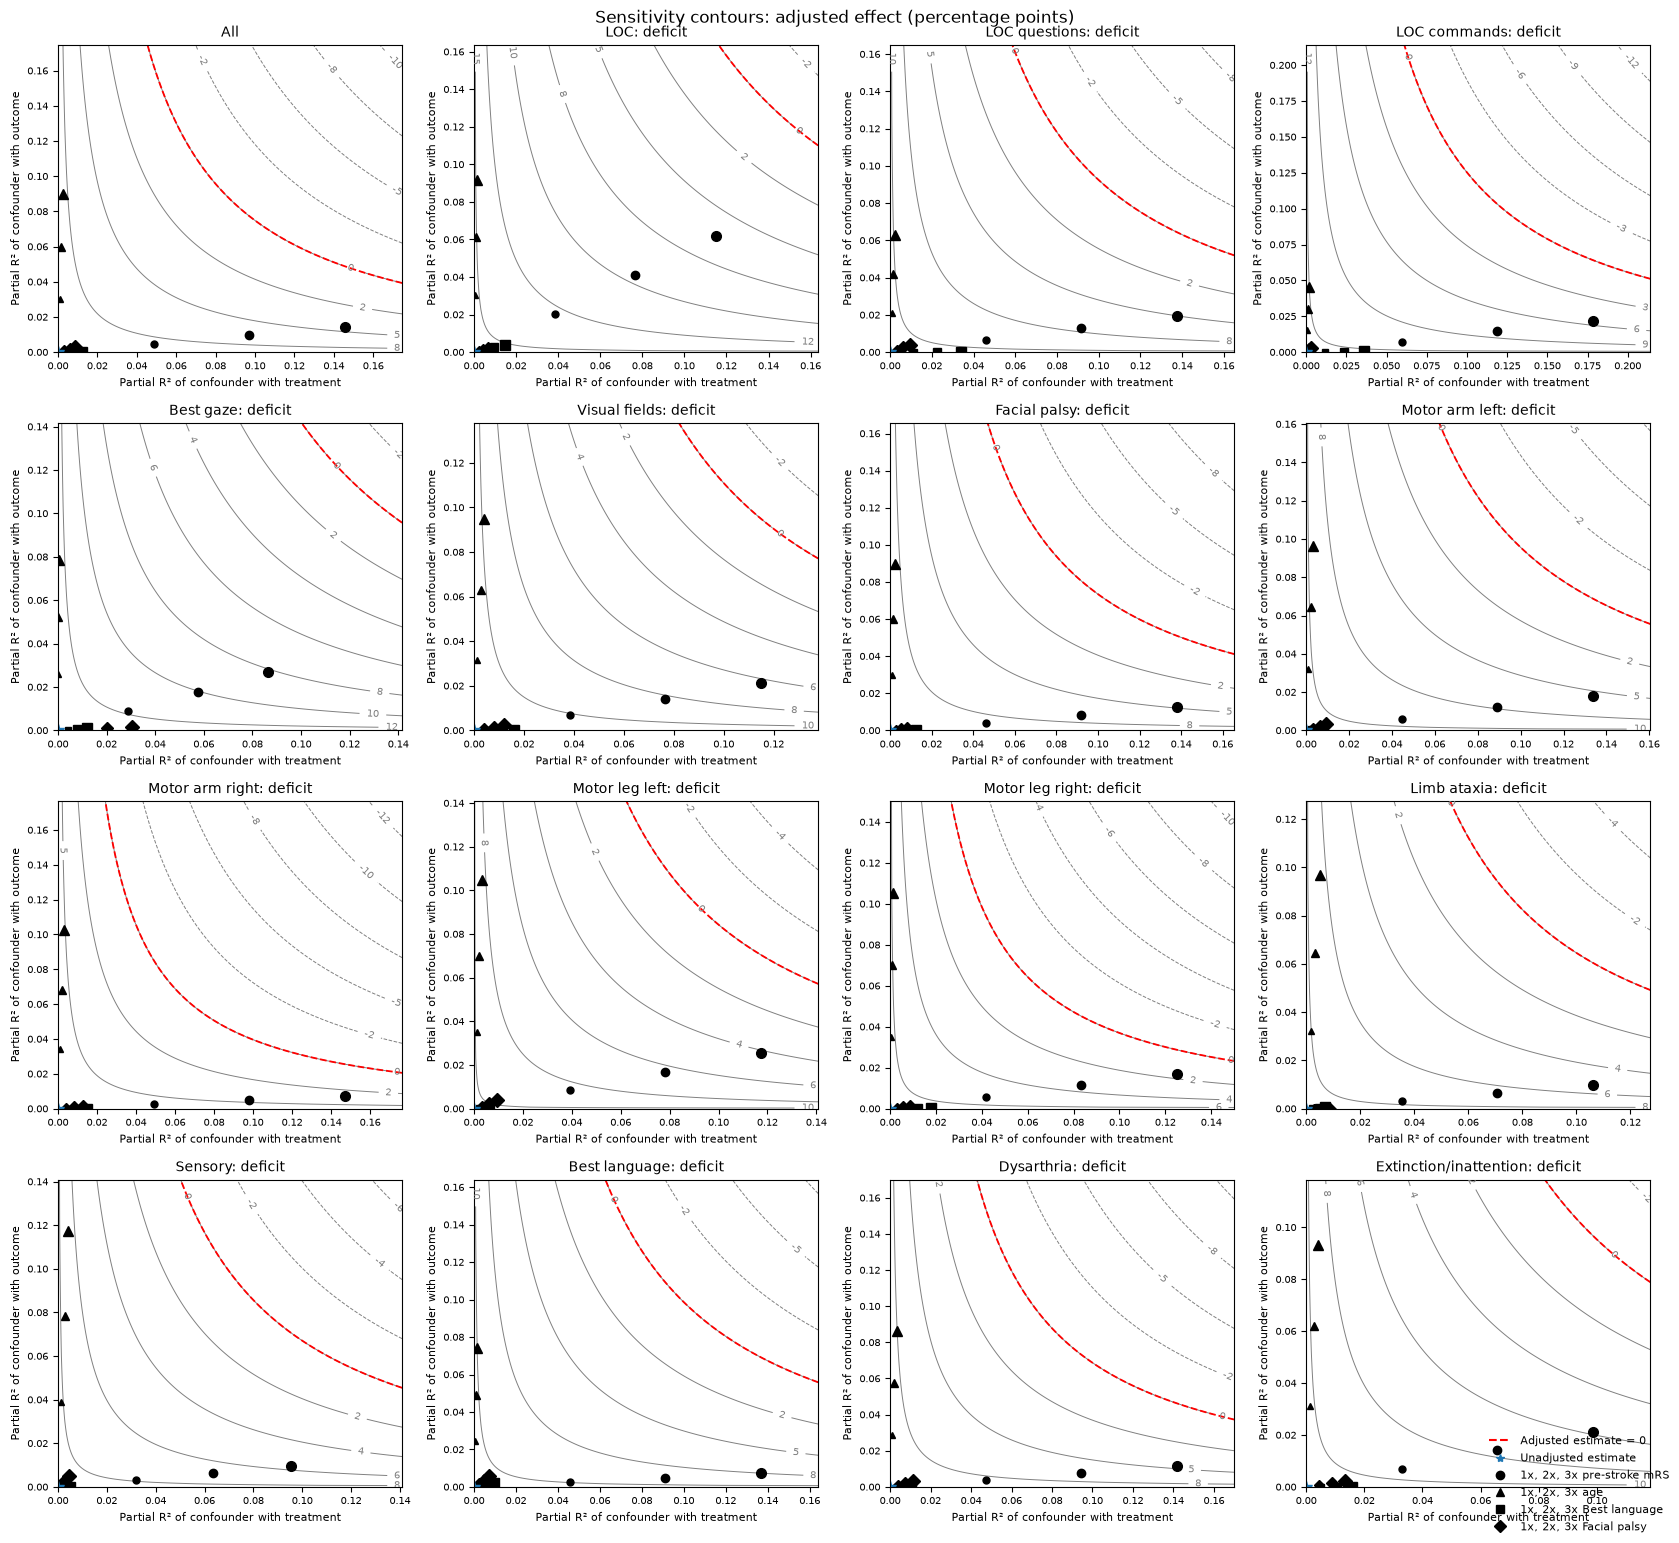

In [44]:
plot_sensemakr_contours(sensemakr_stats, sensemakr_bounds, SENS_LABELS, output_path("sensemakr_contours.png"))

**Results.** The linear probability model gives 9.8 percentage points overall (95% CI 8.5 to 11.0), close to the S-learner (9.4). The NIHSS benchmarks, the items most strongly associated with thrombolysis, are best language and facial palsy.
* **Overall robustness.** The robustness value is 8.7% (RV_q,α 7.6%), about twice that for NIHSS 1–5.
* **Benchmarks for the overall estimate.** A confounder 3 times as strong as a benchmark would leave:
  * age, language or facial palsy: 8.2–9.6 points;
  * **pre-stroke mRS**: 4.4 (3.1 to 5.8). Pre-stroke mRS is strongly associated with both thrombolysis and outcome in this group, so a confounder of similar strength would substantially reduce, but not remove, the benefit.
* **Within deficit groups.**
  * Estimates are 7.0–15.9 points, with robustness values of 6.2–13.6%. Robustness is highest with LOC, gaze and LOC commands (11.1–13.6%), and lowest with right-sided weakness (6.2–6.4%).
  * With benchmark confounders 3 times as strong as each benchmark, the lower CI limit stays above zero in every group except right leg weakness (pre-stroke mRS benchmark: −0.7). For LOC (0.1) and right arm weakness (1.0) it stays only just above zero.

## S5. Leave-one-out analysis of the main confounders and of each NIHSS item

Features are removed from the S-learner in turn, and the model is refitted with the same tuned hyperparameters and cross-validation folds:

* all 15 NIHSS items together (no measure of stroke severity left in the model);
* age;
* pre-stroke mRS;
* each NIHSS item on its own.

Leaving out a measured confounder is a deliberate misspecification. The change in the estimated effect in thrombolysed patients shows how much each result depends on adjusting for that confounder. It also suggests how much bias an unmeasured confounder of similar strength, acting in the same direction, could cause. Leaving out a single item also shows how much that item is needed to identify who benefits.

Results by NIHSS item deficit use each thrombolysed patient's recorded item scores, also when items are left out of the model.

In [45]:
# Leave-one-out sensitivity analysis: remove features from the S-learner in turn,
# refitting with the same tuned hyperparameters and cross-validation folds
LOO_MAIN = {
    "Without all NIHSS items": NIHSS_COMPONENTS,
    "Without age": ["age"],
    "Without pre-stroke mRS": ["prior_disability"],
}
LOO_ITEMS = {f"Without {label(c)}": [c] for c in NIHSS_COMPONENTS}

def loo_rows(cf_, analysis, auc):
    """Mean effect by group for one analysis, with the model's mean out-of-fold AUC."""
    estimates = effect_estimates(cf_).reset_index()
    estimates["analysis"] = analysis
    estimates["mean AUC"] = auc
    return estimates

loo_results = [loo_rows(cf, "Primary", performance["AUC"].mean())]
for name, removed in {**LOO_MAIN, **LOO_ITEMS}.items():
    cf_loo, performance_loo = run_thrombolysis_analysis(data, features=[f for f in X_FIELDS if f not in removed])
    loo_results.append(loo_rows(cf_loo, name, performance_loo["AUC"].mean()))
    print(f"Completed: {name}")

loo_df = pd.concat(loo_results, ignore_index=True)
loo_df["prob_diff_pp"] = 100 * loo_df["prob_diff"]
primary_pp = loo_df[loo_df["analysis"] == "Primary"].set_index("group")["prob_diff_pp"]
loo_df["change_pp"] = loo_df["prob_diff_pp"] - loo_df["group"].map(primary_pp)
loo_df.to_csv(output_path("leave_one_out.csv"), index=False)

loo_columns = ["Primary", *LOO_MAIN]
loo_groups = ["All"] + DEFICIT_GROUPS
for values, title, decimals in [
    ("prob_diff_pp", "Mean benefit in thrombolysed patients, percentage points", 1),
    ("change_pp", "Change from the primary estimate, percentage points", 1),
]:
    print(title)
    display(loo_df.pivot(index="group", columns="analysis", values=values)
            .reindex(index=loo_groups, columns=loo_columns).round(decimals))

# Single-item leave-one-out: change overall and in patients with the removed item's deficit
single_item_rows = []
for c in NIHSS_COMPONENTS:
    analysis = loo_df[loo_df["analysis"] == f"Without {label(c)}"].set_index("group")
    single_item_rows.append({
        "item left out": label(c),
        "mean AUC": analysis["mean AUC"].iloc[0],
        "change pp, all": analysis.loc["All", "change_pp"],
        "change pp, patients with this deficit": analysis.loc[deficit_group(c), "change_pp"],
        "change pp, patients without this deficit": analysis.loc[no_deficit_group(c), "change_pp"],
    })
single_item_loo = pd.DataFrame(single_item_rows).set_index("item left out")
single_item_loo.to_csv(output_path("leave_one_out_nihss_items.csv"))
print("Leaving out one NIHSS item at a time")
display(single_item_loo.round(3))
print("Mean out-of-fold AUC:",
      loo_df[loo_df["analysis"].isin(loo_columns)].drop_duplicates("analysis")
      .set_index("analysis")["mean AUC"].round(3).to_dict())

Completed: Without all NIHSS items
Completed: Without age
Completed: Without pre-stroke mRS
Completed: Without LOC
Completed: Without LOC questions
Completed: Without LOC commands
Completed: Without Best gaze
Completed: Without Visual fields
Completed: Without Facial palsy
Completed: Without Motor arm left
Completed: Without Motor arm right
Completed: Without Motor leg left
Completed: Without Motor leg right
Completed: Without Limb ataxia
Completed: Without Sensory
Completed: Without Best language
Completed: Without Dysarthria
Completed: Without Extinction/inattention
Mean benefit in thrombolysed patients, percentage points


analysis,Primary,Without all NIHSS items,Without age,Without pre-stroke mRS
group,,,,
All,9.4,9.8,10.1,8.5
LOC: deficit,11.5,9.3,12.0,10.3
LOC questions: deficit,10.3,9.4,11.0,9.2
LOC commands: deficit,11.0,9.4,11.9,9.6
Best gaze: deficit,10.8,9.6,11.3,10.5
Visual fields: deficit,9.9,9.6,10.6,9.4
Facial palsy: deficit,9.5,9.9,10.2,8.7
Motor arm left: deficit,9.8,9.8,10.6,9.1
Motor arm right: deficit,8.2,9.8,8.7,7.2


Change from the primary estimate, percentage points


analysis,Primary,Without all NIHSS items,Without age,Without pre-stroke mRS
group,,,,
All,0.0,0.3,0.6,-0.9
LOC: deficit,0.0,-2.1,0.5,-1.2
LOC questions: deficit,0.0,-0.9,0.8,-1.1
LOC commands: deficit,0.0,-1.5,0.9,-1.4
Best gaze: deficit,0.0,-1.2,0.5,-0.3
Visual fields: deficit,0.0,-0.3,0.7,-0.5
Facial palsy: deficit,0.0,0.4,0.6,-0.8
Motor arm left: deficit,0.0,-0.0,0.8,-0.7
Motor arm right: deficit,0.0,1.6,0.5,-1.0


Leaving out one NIHSS item at a time


,mean AUC,"change pp, all","change pp, patients with this deficit","change pp, patients without this deficit"
item left out,,,,
LOC,0.705,0.068,-2.024,0.151
LOC questions,0.704,0.105,-0.416,0.392
LOC commands,0.706,-0.035,-0.546,0.046
Best gaze,0.704,-0.090,-1.129,0.035
Visual fields,0.706,-0.037,-0.225,0.016
Facial palsy,0.705,-0.121,-0.172,-0.006
Motor arm left,0.703,-0.129,-0.516,0.148
Motor arm right,0.703,-0.092,-0.009,-0.138
Motor leg left,0.705,-0.041,0.062,-0.110


Mean out-of-fold AUC: {'Primary': 0.705, 'Without all NIHSS items': 0.688, 'Without age': 0.687, 'Without pre-stroke mRS': 0.671}


**Results.**
* **Without all NIHSS items** the estimated benefit hardly changes: 9.8 points overall, against 9.4 in the primary analysis (AUC 0.688). This is very different from mild stroke, where the benefit disappeared. Within NIHSS 6–10, thrombolysed and untreated patients have almost the same total NIHSS, so severity is not a major confounder. Without the items, every deficit group gets almost the same estimate (9.3–9.9 points), and the differences between deficits disappear.
* **Without pre-stroke mRS** the benefit falls to 8.5 points (−0.9), and AUC to 0.671.
* **Without age** the benefit increases to 10.1 points (+0.7).

  These are the most influential measured confounders in this group. Thrombolysed patients are less disabled and younger, which predicts better outcome; leaving one of them out shifts the estimate by up to 1 point.
* **Leaving out single items.**
  * The overall estimate changes by less than 0.2 points.
  * In patients with the removed item's deficit, the estimate moves towards the average. Benefit falls by 2.0 points for LOC and 1.1 for gaze. It rises by 0.8 for sensory and 0.3 for right leg weakness and ataxia.
  * The differences between deficits are therefore carried by the items themselves.

## S6. Further sensitivity analyses to consider (not run here)

* **Alternative meta-learners.** Compare with a T-learner (separate treated and untreated models), an X-learner, a doubly robust (DR) learner or a causal forest (e.g. `econml`). Doubly robust methods combine the outcome and propensity models and reduce reliance on either being correct. A causal forest would also give honest, item-level effect-modification estimates with confidence intervals.
* **Nested tuning.** Re-tune hyperparameters within each training fold to remove the small optimism of tuning on all patients.
* **Instrumental variable analysis.** Between-hospital variation in thrombolysis use for moderate stroke is large. Hospital thrombolysis rate (in moderate stroke) can be used as an instrument. Under its own assumptions, this addresses unmeasured patient-level confounding, such as a disabling vs non-disabling deficit.
* **Placebo / negative-control tests.**
  * (a) Randomly reassign thrombolysis times among treated patients: any time gradient should disappear.
  * (b) Use a negative-control outcome that thrombolysis cannot plausibly affect but that shares confounders.
* **Quantitative bias analysis** for a specified unmeasured confounder, to complement E-values and sensemakr. An example is the prevalence of disabling deficits in treated vs untreated patients, and their effect on outcome.
* **Clinically defined deficit groups.** Combine items into pre-specified groups (e.g. a 'clearly disabling' definition based on language, motor, visual field and neglect items, as used in PRISMS-style definitions) and estimate the benefit in each.
* **Comparison with trial evidence.** Trials of thrombolysis in minor, non-disabling stroke (e.g. PRISMS, ARAMIS) have not shown benefit over antiplatelet therapy. Restricting to the patients most like trial populations, where data allow, would directly check whether the observational estimate is consistent.
* **Missing data and selection.** Compare native missing-value handling with multiple imputation; vary the arrival window; include patients who had perfusion imaging.

# 7. Summary of observations and conclusions

## Observations

1. **Population and selection.**
   * 27,818 patients with moderate ischaemic stroke (NIHSS 6–10) arrived within 4 hours; 50.3% received thrombolysis.
   * Unlike in mild stroke, treatment did not depend on total NIHSS (49–53% at each score). Thrombolysed and untreated patients had almost the same mean NIHSS.
   * Treatment depended mainly on age, pre-stroke disability and anticoagulant use.
   * The propensity model had an AUC of 0.74, and overlap was good in every deficit group.
2. **Model quality.**
   * The tuned XGBoost outcome model had moderate discrimination (AUC 0.71). This is lower than in mild stroke because severity varies less.
   * It was well calibrated: intercept 0.00, slope 1.01.
3. **NIHSS items and outcome.**
   * **Strongest associations with poor outcome**: gaze (OR 0.72 per point), LOC (0.70) and arm weakness (0.77–0.78).
   * **Next**: extinction/inattention (0.83) and LOC questions (0.86).
   * **Weaker associations**: facial palsy, leg weakness, visual fields, LOC commands and dysarthria (0.87–0.91).
   * **No association with worse outcome**: language, limb ataxia and sensory deficits. Patients whose 6–10 points come from these items did better than those whose points come from consciousness, gaze or arm items.
4. **Average benefit.**
   * In thrombolysed patients, thrombolysis was associated with a **9.4 percentage-point** higher probability of good discharge outcome (bootstrap 95% CI 8.3 to 10.6; OR 1.55, 1.46 to 1.64).
   * This is nearly three times the benefit for NIHSS 1–5 (3.5 points).
   * It was stable across fold seeds, populations, outcome definitions (log OR 0.42–0.46), regularised and logistic models (9.0 and 9.8 points) and total NIHSS in place of the items (10.4 points).
5. **Time to treatment.**
   * Benefit declined steadily with delay, by about 0.13 log odds ratio per hour.
   * It was greatest within 1.5 hours and small after 5 hours.
   * The extrapolated zero point was about 372 minutes (bootstrap 95% CI 307 to 436).
   * Time was the strongest modifier of benefit in the meta-model.
6. **Other modifiers.** Benefit was much smaller in patients with:
   * pre-stroke mRS 4–5 (log OR about 0.1, vs 0.42–0.47 at mRS 0–2; meta-model SHAP −0.25 to −0.3);
   * age over 85 (about 0.31 vs 0.47);
   * diabetes (0.34 vs 0.46).

   In this group these patient factors outranked every NIHSS item as modifiers of benefit.
7. **Where thrombolysis is most effective.** Benefit was large with every deficit (7.9–11.5 points), and differences between deficits were modest:
   * **Greater**: LOC (+2.1 points, CI excluding zero). LOC commands, gaze, LOC questions and language pointed the same way (+1.1 to +1.8, CIs including zero).
   * **Smaller**: right arm (−1.8) and right leg weakness (−2.3), sensory (−1.7) and limb ataxia (−0.9), all with CIs excluding zero.
   * **Consistent**: the pattern held across the tuned sensitivity scenarios. Leaving an item out of the model moved the estimate for that deficit towards the average.
   * **Comparison with mild stroke**: the direction is similar to NIHSS 1–5 for consciousness, gaze, sensory and ataxia deficits. Smaller benefit with right-sided weakness is a feature of this group.
   * **Number of items**: unlike in mild stroke, benefit did not increase with the number of items affected.
8. **Robustness and unmeasured confounding.**
   * The overall E-value is 1.79 (bootstrap CI limit 1.71) and the sensemakr robustness value 8.7%. These are the most robust estimates across the severity ranges studied.
   * A confounder 3 times as strong as pre-stroke mRS would reduce the benefit to about 4.4 points but not remove it.
   * Leaving all NIHSS items out barely changed the average benefit, because severity is not a strong confounder within NIHSS 6–10.
   * Leaving out pre-stroke mRS or age changed it by up to 1 point.

## Comparison with trial evidence

Patients with NIHSS 6–10 have deficits that would generally be regarded as disabling, and they are well represented in the thrombolysis trials. Pooled trial data show a clear benefit of early thrombolysis in this range, decreasing with delay. The present estimates are consistent with that:
* a substantial average benefit (about 9 points, OR 1.55);
* a steady decline with time;
* benefit present with every type of deficit.

The smaller benefit in patients with high pre-stroke disability, very old age or diabetes is consistent with these patients' lower capacity to recover to independence, rather than evidence of harm.

Other differences from the trials:
* the comparator is usual care;
* outcome is measured at discharge rather than at 90 days;
* patients who received thrombectomy are excluded. At NIHSS 6–10 this removes many patients with large vessel occlusion, so the thrombolysed population here is weighted towards non-LVO strokes;
* there may be residual confounding.

## Conclusions

* In moderate stroke (NIHSS 6–10), thrombolysis is associated with a substantial improvement in good outcome at discharge, about 9 percentage points.
* The estimate is robust to model specification and moderately robust to unmeasured confounding.
* **Time to treatment is the dominant modifier**: benefit declines steadily, by about 0.13 log odds ratio per hour.
* **Patient factors matter more than the type of deficit.** Benefit is much smaller with pre-stroke mRS 4–5, age over 85 and diabetes.
* **The type of deficit modifies benefit only modestly.**
  * Benefit is somewhat greater with deficits of consciousness and gaze.
  * It is somewhat smaller with right-sided weakness, sensory and ataxia deficits.
  * Benefit is large in every deficit group.
* **Confounding by severity is weak** at this severity, so the estimates depend less on modelling it than in mild stroke.

## Limitations

* **Observational data.** Causal interpretation requires no unmeasured confounding. Pre-stroke disability, age and frailty drive treatment decisions here, and frailty is only partly measured.
* **Outcome.** It is measured at discharge, not at 90 days.
* **Population.** Patients who received thrombectomy or perfusion imaging are excluded, so this is a selected NIHSS 6–10 group.
* **Effect measure.** Effects are averages of model-based individual (conditional) estimates in thrombolysed patients. They are not marginal effects, and individual estimates are not validated against individual outcomes.
* **Time.** The zero-benefit time is an extrapolation beyond the observed treatment times.
* **Subgroups.** The deficit groups overlap and are compared one at a time; with 15 items, some smaller differences may arise by chance.
* **Tuning.** Hyperparameters were tuned on all patients (non-nested); the bootstrap held them fixed.
* **Sensemakr.** It uses a linear probability model as a stand-in for the S-learner.

Further analyses that would strengthen the conclusions are listed in S6, notably a causal forest or doubly robust learner for item-level effect modification.